# Section 2 — Washing-Machine Exploratory Data Analysis (EDA)

## Purpose and scope

This notebook explores washing-machine electricity use in the cleaned REFIT dataset. It examines data quality, household monitoring coverage, power distributions, estimated activation episodes, temporal usage patterns and differences across households. The outputs are intended to inform the appliance-disaggregation work in Section 3.

**Primary households:** Houses 1, 2, 6 and 7. House 5 is retained for supplementary signal-quality investigation but is not part of the primary four-household comparison.

**Analysis conventions:** Native-resolution observations are used for initial quality audits; the main usage and activation analysis is performed at one-minute resolution. Local usage time is interpreted in `Europe/London`. Missing or insufficiently observed minutes remain unavailable rather than being converted to zero.

**How to read this notebook:** Each major phase is marked as a numbered EDA step. A short *Cell purpose* note appears immediately before each code cell to explain what that cell does.

## Step 0 — Initialize the project environment

**Cell purpose:** Locate the project root from the current working directory and set it as the notebook working directory so that the relative `data/` and `outputs/` paths used below resolve consistently.

In [ ]:
from pathlib import Path
import os

current_dir = Path.cwd().resolve()
search_locations = [current_dir, *current_dir.parents]

PROJECT_ROOT = next(
    (location for location in search_locations
     if (location / "data" / "clean").is_dir()),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root. Open this notebook "
        "from inside the refit-nilm project, where data/clean exists."
    )

os.chdir(PROJECT_ROOT)
print("Project root:", PROJECT_ROOT)
print("Working directory:", Path.cwd())

## Step 1 — Set Up the Project and Locate the Cleaned REFIT Data

**Cell purpose:** Inspect the project data directory and list the cleaned REFIT files available for analysis.

In [2]:
from pathlib import Path

DATA_ROOT = PROJECT_ROOT / "data"
CLEAN_DIR = DATA_ROOT / "clean"

print("Clean Dataset Directory:", CLEAN_DIR)

if not CLEAN_DIR.exists():
    raise FileNotFoundError("data/clean directory not found.")

# Recursively inspect all files
files = sorted(
    file for file in CLEAN_DIR.rglob("*")
    if file.is_file()
)

print("\nTotal files:", len(files))

for file in files:
    size_mb = file.stat().st_size / (1024 ** 2)

    print(
        f"{file.relative_to(CLEAN_DIR)}"
        f" | {size_mb:.2f} MB"
    )

# Categorize files
csv_files = [
    f for f in files
    if f.suffix.lower() == ".csv"
]

archives = [
    f for f in files
    if f.suffix.lower() in [".7z", ".zip", ".rar"]
]

readme_files = [
    f for f in files
    if "readme" in f.name.lower()
]

print("\nCSV files:", len(csv_files))
print("Archives:", len(archives))
print("README files:", len(readme_files))

Clean Dataset Directory: /Users/rehaanraza/Desktop/assessmentFlock/refit-nilm/data/clean

Total files: 7
.DS_Store | 0.01 MB
.gitkeep | 0.00 MB
CLEAN_House1.csv | 382.27 MB
CLEAN_House2.csv | 310.32 MB
CLEAN_House5.csv | 415.11 MB
CLEAN_House6.csv | 349.42 MB
CLEAN_House7.csv | 370.96 MB

CSV files: 5
Archives: 0
README files: 0


**Cell purpose:** Define the cleaned CSV paths for the candidate households and verify that each input file exists.

In [3]:
import pandas as pd
from pathlib import Path

CLEAN_DIR = PROJECT_ROOT / "data" / "clean"

HOUSE_FILES = {
    1: CLEAN_DIR / "CLEAN_House1.csv",
    2: CLEAN_DIR / "CLEAN_House2.csv",
    5: CLEAN_DIR / "CLEAN_House5.csv",
    6: CLEAN_DIR / "CLEAN_House6.csv",
    7: CLEAN_DIR / "CLEAN_House7.csv",
}

# Verify files
for house, path in HOUSE_FILES.items():

    if not path.exists():
        raise FileNotFoundError(
            f"House {house} file not found: {path}"
        )

print("All household files verified.")

All household files verified.


Inspect columns, data types and sample records

## Step 2 — Inspect the Dataset Schema and Map Washing-Machine Channels

**Cell purpose:** Preview a few rows from each candidate file to inspect its columns, data types and basic structure.

In [4]:
for house, path in HOUSE_FILES.items():

    print("\n" + "=" * 70)
    print(f"HOUSE {house}")
    print("=" * 70)

    # Read only 5 rows, not the entire CSV
    sample = pd.read_csv(path, nrows=5)

    print("\nColumns:")
    print(sample.columns.tolist())

    print("\nData types:")
    print(sample.dtypes)

    print("\nFirst 3 records:")
    print(sample.head(3).to_string(index=False))

    print("\nNumber of columns:", len(sample.columns))


HOUSE 1

Columns:
['Time', 'Unix', 'Aggregate', 'Appliance1', 'Appliance2', 'Appliance3', 'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7', 'Appliance8', 'Appliance9', 'Issues']

Data types:
Time            str
Unix          int64
Aggregate     int64
Appliance1    int64
Appliance2    int64
Appliance3    int64
Appliance4    int64
Appliance5    int64
Appliance6    int64
Appliance7    int64
Appliance8    int64
Appliance9    int64
Issues        int64
dtype: object

First 3 records:
               Time       Unix  Aggregate  Appliance1  Appliance2  Appliance3  Appliance4  Appliance5  Appliance6  Appliance7  Appliance8  Appliance9  Issues
2013-10-09 13:06:17 1381323977        523          74           0          69           0           0           0           0           0           1       0
2013-10-09 13:06:31 1381323991        526          75           0          69           0           0           0           0           0           1       0
2013-10-09 13:06:46 1381324006      

All five houses ka schema verification

**Cell purpose:** Check the expected REFIT schema and map each candidate household to its washing-machine appliance channel.

In [5]:
expected_columns = (
    ["Time", "Unix", "Aggregate"]
    + [f"Appliance{i}" for i in range(1, 10)]
    + ["Issues"]
)

WM_MAPPING = {
    1: "Appliance5",
    2: "Appliance2",
    5: "Appliance3",
    6: "Appliance2",
    7: "Appliance5"
}

schema_results = []

for house, path in HOUSE_FILES.items():

    sample = pd.read_csv(path, nrows=5)

    wm_column = WM_MAPPING[house]

    schema_results.append({
        "House": house,
        "Total_Columns": len(sample.columns),
        "Columns_Match": list(sample.columns) == expected_columns,
        "Time_Dtype": str(sample["Time"].dtype),
        "Unix_Dtype": str(sample["Unix"].dtype),
        "WM_Column": wm_column,
        "WM_Dtype": str(sample[wm_column].dtype),
        "Issues_Present": "Issues" in sample.columns,
        "Time_Parse_OK": pd.to_datetime(
            sample["Time"], errors="coerce"
        ).notna().all()
    })

schema_summary = pd.DataFrame(schema_results)

display(schema_summary)

,House,Total_Columns,Columns_Match,Time_Dtype,Unix_Dtype,WM_Column,WM_Dtype,Issues_Present,Time_Parse_OK
0,1,13,True,str,int64,Appliance5,int64,True,True
1,2,13,True,str,int64,Appliance2,int64,True,True
2,5,13,True,str,int64,Appliance3,int64,True,True
3,6,13,True,str,int64,Appliance2,int64,True,True
4,7,13,True,str,int64,Appliance5,int64,True,True


audit function

## Step 3 — Audit Native-Resolution Data Quality and Availability

**Cell purpose:** Define reusable functions for auditing timestamps, sampling intervals, signal values and time-weighted data quality.

In [6]:
from collections import Counter
import numpy as np
import pandas as pd


def weighted_quantile(counter, q):

    if not counter:
        return np.nan

    items = sorted(
        (int(value), int(count))
        for value, count in counter.items()
        if count > 0
    )

    total = sum(count for _, count in items)
    target = max(1, int(np.ceil(q * total)))

    cumulative = 0

    for value, count in items:
        cumulative += count

        if cumulative >= target:
            return value

    return items[-1][0]


def audit_household(house, path, wm_column, chunksize=200_000):

    usecols = [
        "Time",
        "Unix",
        "Aggregate",
        wm_column,
        "Issues"
    ]

    stats = {
        "House": house,
        "Rows": 0,
        "Time_Parse_Failures": 0,
        "Unix_Parse_Failures": 0,
        "Adjacent_Duplicates": 0,
        "Time_Decreases": 0,
        "Issues_1": 0,
        "Issues_Missing": 0,
        "WM_Missing": 0,
        "WM_Zero": 0,
        "WM_Negative": 0,
        "WM_Max_W": np.nan,
        "Aggregate_Missing": 0,
        "Aggregate_Zero": 0,
        "Aggregate_Negative": 0,
        "Aggregate_Max_W": np.nan
    }

    interval_counts = Counter()
    offset_counts = Counter()

    first_time = None
    last_time = None

    previous_unix = None

    # Read the CSV in chunks
    for chunk in pd.read_csv(
        path,
        usecols=usecols,
        chunksize=chunksize
    ):

        rows = len(chunk)
        stats["Rows"] += rows

        # Convert timestamps
        time_values = pd.to_datetime(
            chunk["Time"],
            errors="coerce"
        )

        unix_values = pd.to_numeric(
            chunk["Unix"],
            errors="coerce"
        )

        # Missing timestamp checks
        stats["Time_Parse_Failures"] += time_values.isna().sum()
        stats["Unix_Parse_Failures"] += unix_values.isna().sum()

        valid_times = time_values.dropna()

        if not valid_times.empty:

            if first_time is None:
                first_time = valid_times.iloc[0]

            last_time = valid_times.iloc[-1]

        # Power readings
        wm = pd.to_numeric(
            chunk[wm_column],
            errors="coerce"
        )

        aggregate = pd.to_numeric(
            chunk["Aggregate"],
            errors="coerce"
        )

        issues = pd.to_numeric(
            chunk["Issues"],
            errors="coerce"
        )

        # Washing machine checks
        stats["WM_Missing"] += wm.isna().sum()
        stats["WM_Zero"] += wm.eq(0).sum()
        stats["WM_Negative"] += wm.lt(0).sum()

        if wm.notna().any():

            current_max = wm.max()

            if pd.isna(stats["WM_Max_W"]):
                stats["WM_Max_W"] = current_max
            else:
                stats["WM_Max_W"] = max(
                    stats["WM_Max_W"],
                    current_max
                )

        # Aggregate checks
        stats["Aggregate_Missing"] += aggregate.isna().sum()
        stats["Aggregate_Zero"] += aggregate.eq(0).sum()
        stats["Aggregate_Negative"] += aggregate.lt(0).sum()

        if aggregate.notna().any():

            current_max = aggregate.max()

            if pd.isna(stats["Aggregate_Max_W"]):
                stats["Aggregate_Max_W"] = current_max
            else:
                stats["Aggregate_Max_W"] = max(
                    stats["Aggregate_Max_W"],
                    current_max
                )

        # Issues column
        stats["Issues_1"] += issues.eq(1).sum()
        stats["Issues_Missing"] += issues.isna().sum()

        # Timestamp differences using Unix
        delta = unix_values.diff()

        if rows > 0:

            if (
                previous_unix is not None
                and pd.notna(unix_values.iloc[0])
            ):
                delta.iloc[0] = (
                    unix_values.iloc[0] - previous_unix
                )
            else:
                delta.iloc[0] = np.nan

            last_unix = unix_values.iloc[-1]

            previous_unix = (
                last_unix if pd.notna(last_unix) else None
            )

        stats["Adjacent_Duplicates"] += delta.eq(0).sum()
        stats["Time_Decreases"] += delta.lt(0).sum()

        # Track sampling interval frequencies
        valid_deltas = delta.dropna()

        interval_counts.update(
            valid_deltas.astype("int64").value_counts().to_dict()
        )

        # Convert Unix UTC to UK local time
        unix_uk = (
            pd.to_datetime(
                unix_values,
                unit="s",
                utc=True,
                errors="coerce"
            )
            .dt.tz_convert("Europe/London")
            .dt.tz_localize(None)
        )

        # Difference between supplied Time and Unix-derived UK time
        offsets = (
            time_values - unix_uk
        ).dt.total_seconds()

        offset_counts.update(
            offsets.dropna().round().astype("int64").value_counts().to_dict()
        )

    # Calculate interval statistics
    positive_intervals = Counter({
        interval: count
        for interval, count in interval_counts.items()
        if interval > 0
    })

    most_common_interval = (
        positive_intervals.most_common(1)[0][0]
        if positive_intervals else np.nan
    )

    stats["Start_Time"] = first_time
    stats["End_Time"] = last_time

    stats["Interval_Mode_Sec"] = most_common_interval

    stats["Interval_Median_Sec"] = weighted_quantile(
        positive_intervals, 0.50
    )

    stats["Interval_P95_Sec"] = weighted_quantile(
        positive_intervals, 0.95
    )

    stats["Negative_Intervals"] = sum(
        count
        for interval, count in interval_counts.items()
        if interval < 0
    )

    stats["Zero_Intervals"] = sum(
        count
        for interval, count in interval_counts.items()
        if interval == 0
    )

    return stats, interval_counts, offset_counts

**Cell purpose:** Run the native-resolution data-quality audit for all five candidate households and collect the results.

In [7]:
audit_results = []
audit_details = {}

for house, path in HOUSE_FILES.items():

    print(f"Auditing House {house}...")

    result, intervals, offsets = audit_household(
        house=house,
        path=path,
        wm_column=WM_MAPPING[house]
    )

    audit_results.append(result)

    audit_details[house] = {
        "intervals": intervals,
        "offsets": offsets
    }

    print(f"House {house} completed.")


availability_summary = pd.DataFrame(audit_results)

display(
    availability_summary.round(2)
)

Auditing House 1...
House 1 completed.
Auditing House 2...
House 2 completed.
Auditing House 5...
House 5 completed.
Auditing House 6...
House 6 completed.
Auditing House 7...
House 7 completed.


/var/folders/4y/wyg1yj8s6171ybbm1q81x0m00000gn/T/ipykernel_3174/1929470447.py:27: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  availability_summary.round(2)


,House,Rows,Time_Parse_Failures,Unix_Parse_Failures,Adjacent_Duplicates,Time_Decreases,Issues_1,Issues_Missing,WM_Missing,WM_Zero,...,Aggregate_Zero,Aggregate_Negative,Aggregate_Max_W,Start_Time,End_Time,Interval_Mode_Sec,Interval_Median_Sec,Interval_P95_Sec,Negative_Intervals,Zero_Intervals
0,1,6960008,0,0,0,0,58183,0,0,6803776,...,44,0,29159,2013-10-09 13:06:17,2015-07-10 11:56:32,7,7,14,0,0
1,2,5733526,0,0,0,0,28444,0,0,5413660,...,75,0,24595,2013-09-17 22:08:11,2015-05-28 08:05:43,7,7,14,0,0
2,5,7430755,0,0,0,0,425766,0,0,3845800,...,7,0,41738,2013-09-26 09:56:09,2015-07-06 17:48:55,7,7,14,0,0
3,6,6241971,0,0,0,0,34451,0,0,6089983,...,339,0,32756,2013-11-28 12:15:35,2015-06-28 22:14:45,7,7,14,0,0
4,7,6756034,0,0,0,0,161919,0,0,5673418,...,326,0,32730,2013-11-01 22:01:18,2015-07-08 02:10:54,7,7,14,0,0


**Cell purpose:** Inspect the most common sampling intervals and timestamp-offset patterns recorded for each household.

In [8]:
for house, details in audit_details.items():

    print("\n" + "=" * 55)
    print(f"HOUSE {house}")
    print("=" * 55)

    print("Most common sampling intervals:")

    for interval, count in details["intervals"].most_common(10):
        print(f"{interval:>6} seconds : {count:,} observations")

    print("\nTime vs Unix-derived Europe/London offsets:")

    for offset, count in details["offsets"].most_common(5):
        print(f"{offset:>6} seconds : {count:,} observations")


HOUSE 1
Most common sampling intervals:
     7 seconds : 2,291,708 observations
     6 seconds : 815,764 observations
     1 seconds : 810,052 observations
     2 seconds : 563,532 observations
    14 seconds : 445,223 observations
     3 seconds : 360,681 observations
    13 seconds : 299,367 observations
    15 seconds : 262,968 observations
    12 seconds : 249,765 observations
     8 seconds : 225,526 observations

Time vs Unix-derived Europe/London offsets:
 -3600 seconds : 3,650,764 observations
     0 seconds : 3,309,244 observations

HOUSE 2
Most common sampling intervals:
     7 seconds : 2,088,157 observations
     1 seconds : 719,539 observations
     6 seconds : 597,259 observations
    14 seconds : 419,364 observations
     2 seconds : 331,344 observations
     8 seconds : 292,683 observations
    13 seconds : 252,940 observations
     3 seconds : 221,236 observations
    15 seconds : 207,286 observations
     4 seconds : 137,077 observations

Time vs Unix-derived Europe/

complete audit summary

**Cell purpose:** Display the main audit fields together in a readable household-level summary.

In [9]:
# Display all important audit columns without truncation

audit_columns = [
    "House",
    "Rows",
    "Time_Parse_Failures",
    "Unix_Parse_Failures",
    "Adjacent_Duplicates",
    "Time_Decreases",
    "Issues_1",
    "Issues_Missing",
    "WM_Missing",
    "WM_Zero",
    "WM_Negative",
    "WM_Max_W",
    "Aggregate_Missing",
    "Aggregate_Zero",
    "Aggregate_Negative",
    "Aggregate_Max_W",
    "Start_Time",
    "End_Time",
    "Interval_Mode_Sec",
    "Interval_Median_Sec",
    "Interval_P95_Sec"
]

display(
    availability_summary[audit_columns].to_string(index=False)
)

' House    Rows  Time_Parse_Failures  Unix_Parse_Failures  Adjacent_Duplicates  Time_Decreases  Issues_1  Issues_Missing  WM_Missing  WM_Zero  WM_Negative  WM_Max_W  Aggregate_Missing  Aggregate_Zero  Aggregate_Negative  Aggregate_Max_W          Start_Time            End_Time  Interval_Mode_Sec  Interval_Median_Sec  Interval_P95_Sec\n     1 6960008                    0                    0                    0               0     58183               0           0  6803776            0      3072                  0              44                   0            29159 2013-10-09 13:06:17 2015-07-10 11:56:32                  7                    7                14\n     2 5733526                    0                    0                    0               0     28444               0           0  5413660            0      3584                  0              75                   0            24595 2013-09-17 22:08:11 2015-05-28 08:05:43                  7                    7              

calculate percentages

**Cell purpose:** Convert the counts of zero washing-machine readings and Issues flags into percentages for comparison.

In [10]:
percentage_summary = availability_summary[
    ["House", "Rows", "WM_Zero", "Issues_1"]
].copy()

percentage_summary["WM_Zero_Pct"] = (
    percentage_summary["WM_Zero"]
    / percentage_summary["Rows"] * 100
)

percentage_summary["WM_NonZero_Pct"] = (
    100 - percentage_summary["WM_Zero_Pct"]
)

percentage_summary["Issues_Pct"] = (
    percentage_summary["Issues_1"]
    / percentage_summary["Rows"] * 100
)

display(
    percentage_summary.round(2).to_string(index=False)
)

' House    Rows  WM_Zero  Issues_1  WM_Zero_Pct  WM_NonZero_Pct  Issues_Pct\n     1 6960008  6803776     58183        97.76            2.24        0.84\n     2 5733526  5413660     28444        94.42            5.58        0.50\n     5 7430755  3845800    425766        51.76           48.24        5.73\n     6 6241971  6089983     34451        97.57            2.43        0.55\n     7 6756034  5673418    161919        83.98           16.02        2.40'

All household sampling intervals and timezone offsets

**Cell purpose:** Review detailed sampling-interval and timezone-offset distributions household by household.

In [11]:
for house, details in audit_details.items():

    print(f"\n{'='*55}")
    print(f"HOUSE {house}")
    print(f"{'='*55}")

    print("\nSampling intervals:")

    for interval, count in details["intervals"].most_common(7):
        pct = count / sum(details["intervals"].values()) * 100

        print(
            f"{interval:>6} sec : {count:>12,} "
            f"({pct:.2f}%)"
        )

    print("\nTimezone offsets:")

    total_offsets = sum(details["offsets"].values())

    for offset, count in sorted(details["offsets"].items()):
        pct = count / total_offsets * 100

        print(
            f"{offset:>7} sec : {count:>12,} "
            f"({pct:.2f}%)"
        )


HOUSE 1

Sampling intervals:
     7 sec :    2,291,708 (32.93%)
     6 sec :      815,764 (11.72%)
     1 sec :      810,052 (11.64%)
     2 sec :      563,532 (8.10%)
    14 sec :      445,223 (6.40%)
     3 sec :      360,681 (5.18%)
    13 sec :      299,367 (4.30%)

Timezone offsets:
  -3600 sec :    3,650,764 (52.45%)
      0 sec :    3,309,244 (47.55%)

HOUSE 2

Sampling intervals:
     7 sec :    2,088,157 (36.42%)
     1 sec :      719,539 (12.55%)
     6 sec :      597,259 (10.42%)
    14 sec :      419,364 (7.31%)
     2 sec :      331,344 (5.78%)
     8 sec :      292,683 (5.10%)
    13 sec :      252,940 (4.41%)

Timezone offsets:
  -3600 sec :    3,500,834 (61.06%)
      0 sec :    2,232,692 (38.94%)

HOUSE 5

Sampling intervals:
     7 sec :    2,427,968 (32.67%)
     6 sec :      622,471 (8.38%)
     2 sec :      582,901 (7.84%)
     8 sec :      571,732 (7.69%)
     1 sec :      518,151 (6.97%)
     3 sec :      486,881 (6.55%)
     5 sec :      341,322 (4.59%)

Timezo

Verify timezone behaviour by month (House 1)

**Cell purpose:** Check the monthly relationship between the supplied Time column and Unix-derived UTC timestamps for House 1.

In [12]:
def inspect_monthly_offsets(path, chunksize=200_000):

    monthly_results = []

    for chunk in pd.read_csv(
        path,
        usecols=["Time", "Unix"],
        chunksize=chunksize
    ):

        supplied_time = pd.to_datetime(
            chunk["Time"],
            errors="coerce"
        )

        unix_utc = pd.to_datetime(
            chunk["Unix"],
            unit="s",
            utc=True,
            errors="coerce"
        )

        london_time = (
            unix_utc
            .dt.tz_convert("Europe/London")
            .dt.tz_localize(None)
        )

        offsets = (
            supplied_time - london_time
        ).dt.total_seconds()

        temp = pd.DataFrame({
            "Month": supplied_time.dt.to_period("M"),
            "Offset_Seconds": offsets
        })

        counts = (
            temp.dropna()
            .groupby(["Month", "Offset_Seconds"])
            .size()
        )

        monthly_results.append(counts)

    return (
        pd.concat(monthly_results)
        .groupby(level=[0, 1])
        .sum()
        .unstack(fill_value=0)
    )


monthly_offsets = inspect_monthly_offsets(
    HOUSE_FILES[1]
)

display(monthly_offsets)

Offset_Seconds,-3600.0,0.0
Month,,
2013-10,242412,68964
2013-11,0,346065
2013-12,0,368266
2014-01,0,308916
2014-03,26854,329388
2014-04,363981,0
2014-05,366985,0
2014-06,382266,0
2014-07,329559,0


the analysis function

## Step 4 — Investigate Signal Continuity and Long Constant-Power Runs

**Cell purpose:** Define a helper that identifies long constant-power runs while respecting gaps in the native-resolution signal.

In [13]:
def analyse_signal_runs(unix, values, max_gap_sec=120):

    unix = np.asarray(unix, dtype=np.int64)
    values = np.asarray(values, dtype=np.int32)

    # Estimate typical sampling interval
    intervals = np.diff(unix)

    valid_intervals = intervals[
        (intervals > 0) & (intervals <= max_gap_sec)
    ]

    typical_interval = int(np.median(valid_intervals))

    # A new run begins when:
    # 1. Power value changes
    # 2. A monitoring gap exceeds 120 seconds

    boundaries = (
        (values[1:] != values[:-1])
        | (intervals > max_gap_sec)
    )

    starts = np.r_[0, np.flatnonzero(boundaries) + 1]
    ends = np.r_[starts[1:], len(values)]

    run_values = values[starts]
    run_start = unix[starts]

    run_duration = np.empty(len(starts), dtype=float)

    for i, end in enumerate(ends):

        last = end - 1

        if end < len(unix):

            gap = unix[end] - unix[last]

            if 0 < gap <= max_gap_sec:
                end_time = unix[end]
            else:
                end_time = unix[last] + typical_interval

        else:
            end_time = unix[last] + typical_interval

        run_duration[i] = max(
            0,
            end_time - run_start[i]
        )

    zero_mask = run_values == 0
    nonzero_mask = run_values != 0

    total_valid_seconds = run_duration.sum()

    zero_time_pct = (
        run_duration[zero_mask].sum()
        / total_valid_seconds * 100
        if total_valid_seconds > 0 else np.nan
    )

    result = {
        "Total_Runs": len(run_values),
        "Distinct_Power_Values": len(np.unique(values)),
        "Zero_Runs": int(zero_mask.sum()),

        "Zero_Time_Pct_Observed": zero_time_pct,

        "Zero_Runs_30min": int(
            np.sum(zero_mask & (run_duration >= 1800))
        ),

        "Zero_Runs_1hour": int(
            np.sum(zero_mask & (run_duration >= 3600))
        ),

        "Max_Zero_Run_Hours": (
            run_duration[zero_mask].max() / 3600
            if zero_mask.any() else 0
        ),

        "Nonzero_Constant_Runs_30min": int(
            np.sum(nonzero_mask & (run_duration >= 1800))
        ),

        "Nonzero_Constant_Runs_1hour": int(
            np.sum(nonzero_mask & (run_duration >= 3600))
        ),

        "Max_Nonzero_Run_Hours": (
            run_duration[nonzero_mask].max() / 3600
            if nonzero_mask.any() else 0
        ),

        "Max_Power_W": int(values.max()),

        "Readings_Above_2700W": int(
            np.sum(values > 2700)
        )
    }

    # Keep the five longest non-zero constant runs
    candidates = np.flatnonzero(
        nonzero_mask & (run_duration >= 1800)
    )

    top_indices = candidates[
        np.argsort(run_duration[candidates])[-5:][::-1]
    ]

    top_runs = pd.DataFrame({
        "Power_W": run_values[top_indices],
        "Duration_Min": run_duration[top_indices] / 60,
        "Start_Unix": run_start[top_indices]
    })

    if not top_runs.empty:

        top_runs["Start_London"] = (
            pd.to_datetime(
                top_runs["Start_Unix"],
                unit="s",
                utc=True
            ).dt.tz_convert("Europe/London")
        )

    return result, top_runs

run it for all five households

**Cell purpose:** Apply the constant-run analysis to the mapped washing-machine channel in all five candidate households.

In [14]:
run_summaries = []
long_runs = {}

for house, path in HOUSE_FILES.items():

    print(f"Analysing House {house}...")

    wm_column = WM_MAPPING[house]

    # Read only the necessary columns, one house at a time
    df = pd.read_csv(
        path,
        usecols=["Unix", "Aggregate", wm_column],
        dtype={
            "Unix": "int64",
            "Aggregate": "int32",
            wm_column: "int32"
        }
    )

    unix = df["Unix"].to_numpy()

    # Washing machine analysis
    wm_result, wm_top = analyse_signal_runs(
        unix,
        df[wm_column].to_numpy()
    )

    wm_result["House"] = house
    wm_result["Signal"] = "Washing Machine"

    run_summaries.append(wm_result)

    long_runs[house] = wm_top

    # Aggregate analysis
    agg_result, _ = analyse_signal_runs(
        unix,
        df["Aggregate"].to_numpy()
    )

    agg_result["House"] = house
    agg_result["Signal"] = "Aggregate"

    run_summaries.append(agg_result)

    del df

    print(f"House {house} completed.")


run_summary = pd.DataFrame(run_summaries)

display(
    run_summary.round(2).to_string(index=False)
)

Analysing House 1...
House 1 completed.
Analysing House 2...
House 2 completed.
Analysing House 5...
House 5 completed.
Analysing House 6...
House 6 completed.
Analysing House 7...
House 7 completed.


' Total_Runs  Distinct_Power_Values  Zero_Runs  Zero_Time_Pct_Observed  Zero_Runs_30min  Zero_Runs_1hour  Max_Zero_Run_Hours  Nonzero_Constant_Runs_30min  Nonzero_Constant_Runs_1hour  Max_Nonzero_Run_Hours  Max_Power_W  Readings_Above_2700W  House          Signal\n      94010                    876       2710                   97.76             1243              973              200.17                           10                            4                   2.81         3072                     4      1 Washing Machine\n    4585892                   9067         25                    0.00                0                0                0.00                           12                            9                  19.79        29159                142516      1       Aggregate\n     200295                    807        990                   94.45              635              581              207.15                            5                            0                   0.72   

**Cell purpose:** Inspect the long constant-power runs found in each household and review their duration and power level.

In [15]:
for house, runs in long_runs.items():

    print(f"\nHouse {house}")

    if runs.empty:
        print("No non-zero constant runs above 30 minutes.")
    else:
        display(runs.drop(columns=["Start_Unix"]))


House 1


,Power_W,Duration_Min,Start_London
0,2256,168.650000,2015-02-08 13:24:00+00:00
1,514,99.000000,2014-10-02 04:06:42+01:00
2,8,89.383333,2014-10-05 16:10:01+01:00
3,1,75.783333,2014-10-02 09:18:28+01:00
4,32,53.133333,2014-10-02 05:56:20+01:00



House 2


,Power_W,Duration_Min,Start_London
0,92,42.966667,2014-12-05 09:21:41+00:00
1,5,37.983333,2014-05-04 07:08:36+01:00
2,5,37.766667,2014-05-04 05:10:05+01:00
3,5,31.000000,2014-05-03 23:01:07+01:00
4,5,30.733333,2014-05-04 06:05:51+01:00



House 5


,Power_W,Duration_Min,Start_London
0,3,5970.883333,2013-10-27 01:00:01+01:00
1,3,4596.816667,2014-08-22 08:08:21+01:00
2,3,2946.483333,2014-01-08 19:56:50+00:00
3,64,2866.700000,2014-10-28 18:37:10+00:00
4,86,2721.016667,2014-08-30 12:14:29+01:00



House 6


,Power_W,Duration_Min,Start_London
0,1,104.250000,2014-08-19 12:46:35+01:00
1,1,80.500000,2014-09-28 13:36:06+01:00
2,1,67.383333,2015-04-24 14:07:49+01:00
3,1,66.400000,2014-11-21 12:27:57+00:00
4,1,65.500000,2014-10-19 20:42:21+01:00



House 7


,Power_W,Duration_Min,Start_London
0,2178,98.150000,2014-10-04 16:27:45+01:00
1,2,30.433333,2015-02-22 13:19:21+00:00


house 5 looks suspicious lets run some experiments 
This creates the event windows we want to investigate.

**Cell purpose:** Select representative suspicious runs and convert them into padded event windows for closer inspection.

In [16]:
# Events selected from the longest constant non-zero runs

SELECTED_EVENTS = {
    1: [0],
    5: [0, 3, 4],
    7: [0]
}

PAD_MINUTES = 15

event_specs = []

for house, indices in SELECTED_EVENTS.items():

    runs = long_runs[house]

    for idx in indices:

        row = runs.iloc[idx]

        start_unix = int(row["Start_Unix"])
        duration_sec = row["Duration_Min"] * 60

        event_specs.append({
            "House": house,
            "Run_Index": idx,
            "Power_W": int(row["Power_W"]),
            "Duration_Min": row["Duration_Min"],
            "Start_Unix": start_unix,
            "End_Unix": int(start_unix + duration_sec)
        })

event_specs = pd.DataFrame(event_specs)

display(event_specs)

,House,Run_Index,Power_W,Duration_Min,Start_Unix,End_Unix
0,1,0,2256,168.650000,1423401840,1423411959
1,5,0,3,5970.883333,1382832001,1383190254
2,5,3,64,2866.700000,1414521430,1414693432
3,5,4,86,2721.016667,1409397269,1409560530
4,7,0,2178,98.150000,1412436465,1412442354


Load only those event windows

**Cell purpose:** Define a chunked reader that extracts only the raw observations around the selected event windows.

In [17]:
from collections import defaultdict

def extract_event_data(
    house,
    events,
    chunksize=200_000,
    padding_minutes=15
):

    path = HOUSE_FILES[house]
    wm_column = WM_MAPPING[house]

    usecols = [
        "Unix",
        "Aggregate",
        wm_column,
        "Issues"
    ]

    event_buffers = defaultdict(list)

    padding = padding_minutes * 60

    max_end = int(events["End_Unix"].max()) + padding

    for chunk in pd.read_csv(
        path,
        usecols=usecols,
        chunksize=chunksize
    ):

        # CSV is chronologically ordered, so we can stop
        # once all selected event windows have passed.

        if chunk["Unix"].iloc[0] > max_end:
            break

        for idx, event in events.iterrows():

            lower = int(event["Start_Unix"]) - padding
            upper = int(event["End_Unix"]) + padding

            mask = chunk["Unix"].between(lower, upper)

            if mask.any():

                event_buffers[idx].append(
                    chunk.loc[mask].copy()
                )

    return event_buffers

Plot Aggregate and Washing Machine separately

**Cell purpose:** Define a plotting helper to compare aggregate and washing-machine power around a selected event.

In [18]:
import matplotlib.pyplot as plt


def plot_event(house, event_index, event_data):

    if event_data.empty:
        print("No data found for this event.")
        return

    wm_column = WM_MAPPING[house]

    df = event_data.copy()

    df["Timestamp"] = pd.to_datetime(
        df["Unix"],
        unit="s",
        utc=True
    ).dt.tz_convert("Europe/London")

    df = df.set_index("Timestamp").sort_index()

    # One-minute means for visualization only
    plot_data = df[
        ["Aggregate", wm_column, "Issues"]
    ].resample("1min").mean()

    event = event_specs[
        (event_specs["House"] == house)
        & (event_specs["Run_Index"] == event_index)
    ].iloc[0]

    start = pd.to_datetime(
        event["Start_Unix"],
        unit="s",
        utc=True
    ).tz_convert("Europe/London")

    end = pd.to_datetime(
        event["End_Unix"],
        unit="s",
        utc=True
    ).tz_convert("Europe/London")

    issues_pct = df["Issues"].mean() * 100

    fig, axes = plt.subplots(
        2, 1,
        figsize=(15, 8),
        sharex=True
    )

    # Aggregate power
    axes[0].plot(
        plot_data.index,
        plot_data["Aggregate"],
        label="Aggregate Power"
    )

    # Washing-machine event boundaries
    axes[0].axvspan(
        start, end,
        alpha=0.15,
        label="Constant WM segment"
    )

    axes[0].set_ylabel("Aggregate Power (W)")
    axes[0].set_title(
        f"House {house} – Aggregate Power"
    )

    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Washing machine power
    axes[1].plot(
        plot_data.index,
        plot_data[wm_column],
        label="Washing Machine Power"
    )

    axes[1].axvspan(
        start, end,
        alpha=0.15,
        label="Constant WM segment"
    )

    axes[1].axhline(
        event["Power_W"],
        linestyle="--",
        label=f"Constant reading: {event['Power_W']} W"
    )

    axes[1].set_ylabel("Washing Machine Power (W)")
    axes[1].set_xlabel("Time (Europe/London)")
    axes[1].set_title(
        f"House {house} – Washing Machine"
    )

    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.suptitle(
        f"House {house} | "
        f"{event['Power_W']} W for "
        f"{event['Duration_Min'] / 60:.2f} hours "
        f"| Issues rows: {issues_pct:.2f}%"
    )

    plt.tight_layout()
    plt.show()

Matplotlib is building the font cache; this may take a moment.


Execute the inspection

**Cell purpose:** Extract the selected event windows and plot their aggregate and washing-machine traces for visual review.


Inspecting House 1
Event 0: 1806 observations


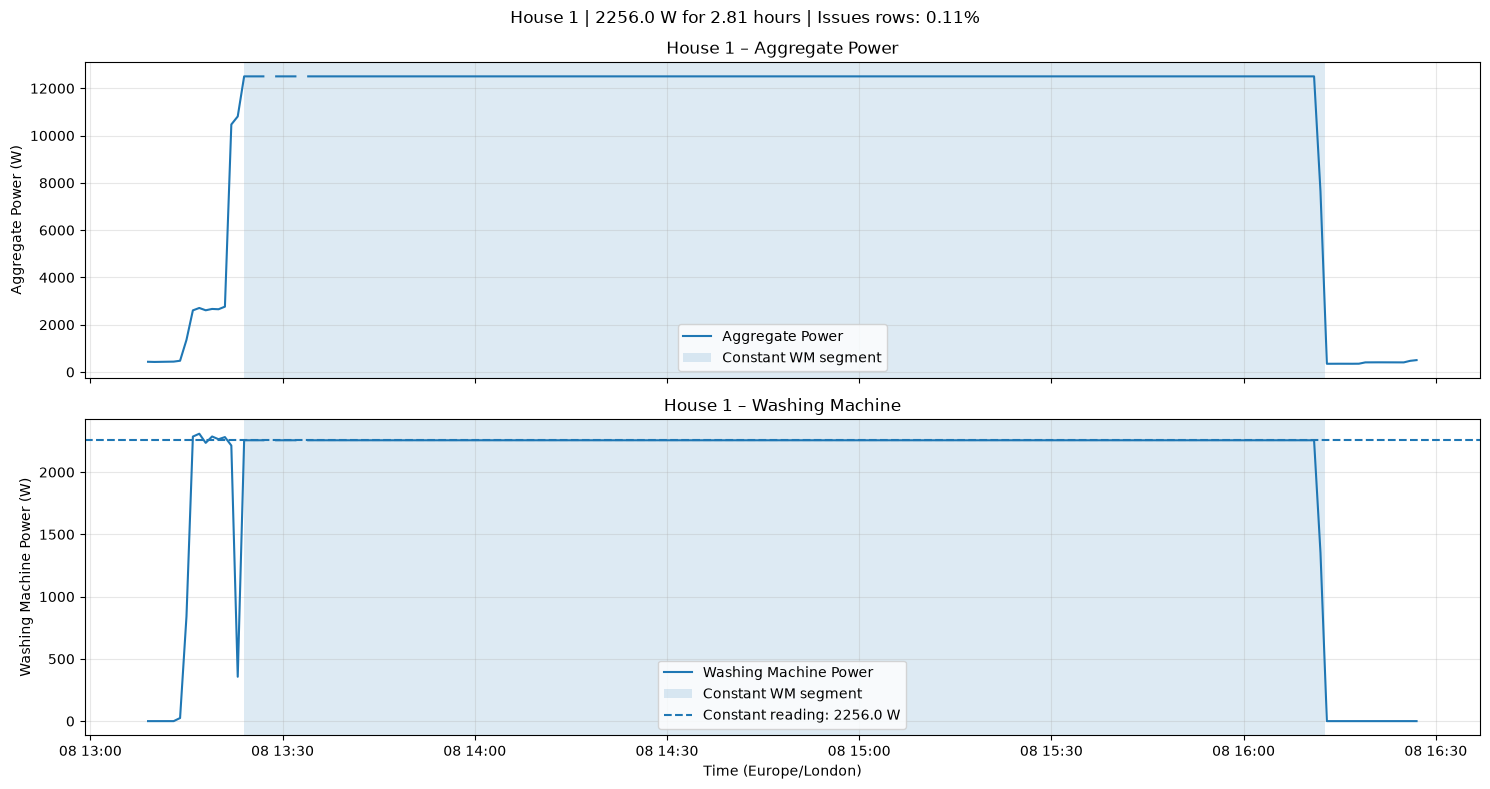


Inspecting House 5
Event 1: 59127 observations


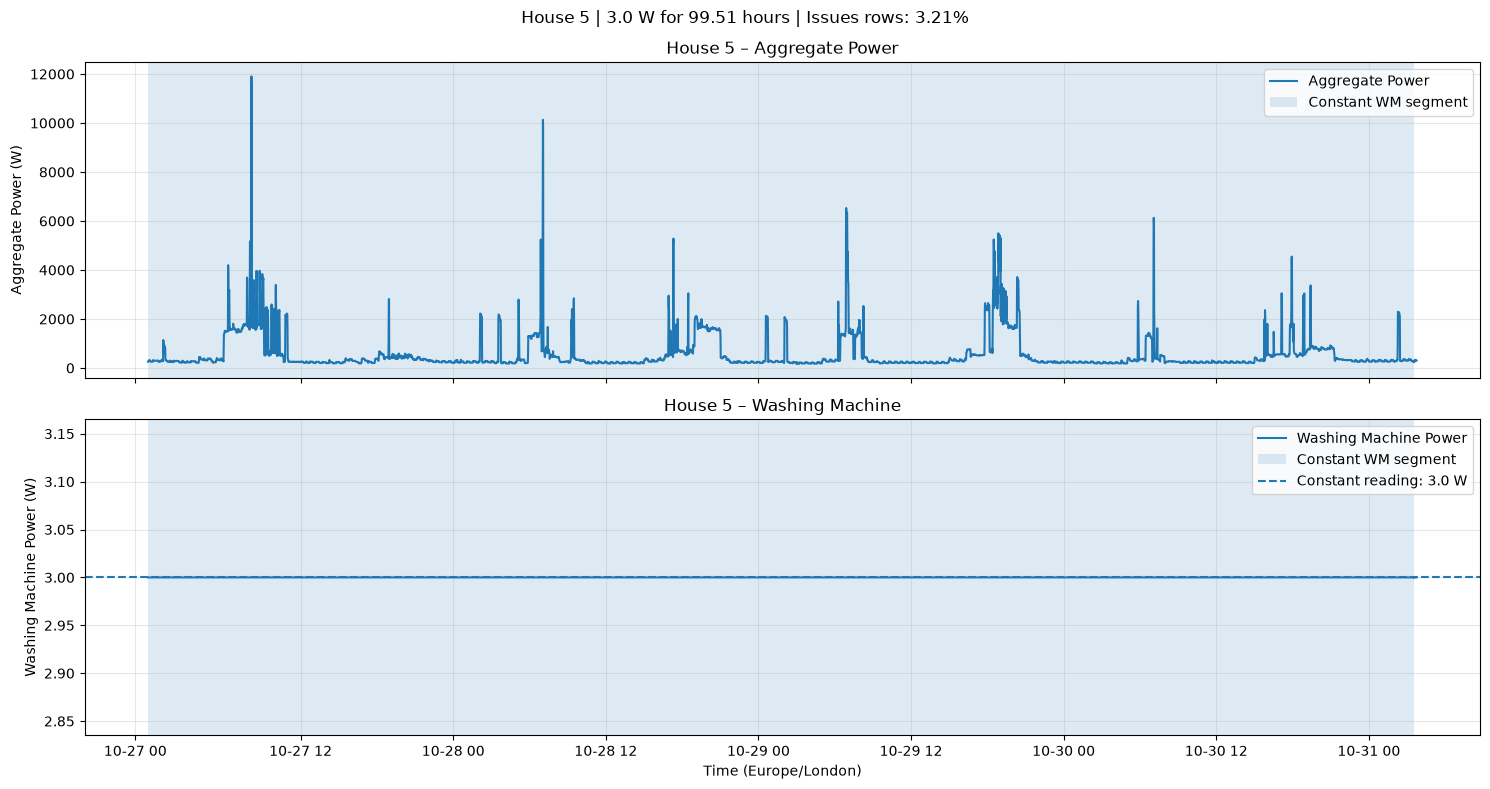

Event 2: 25184 observations


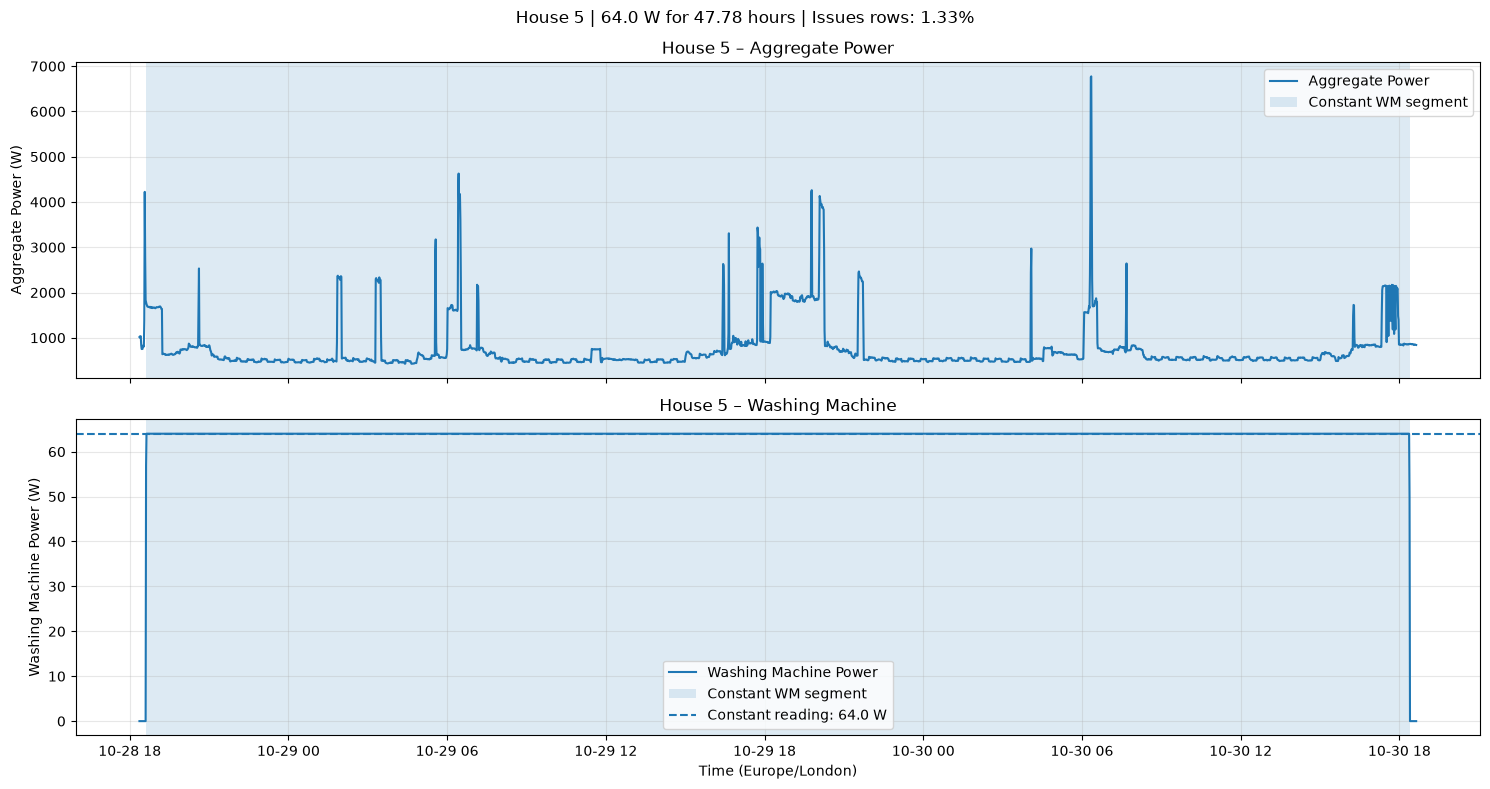

Event 3: 5257 observations


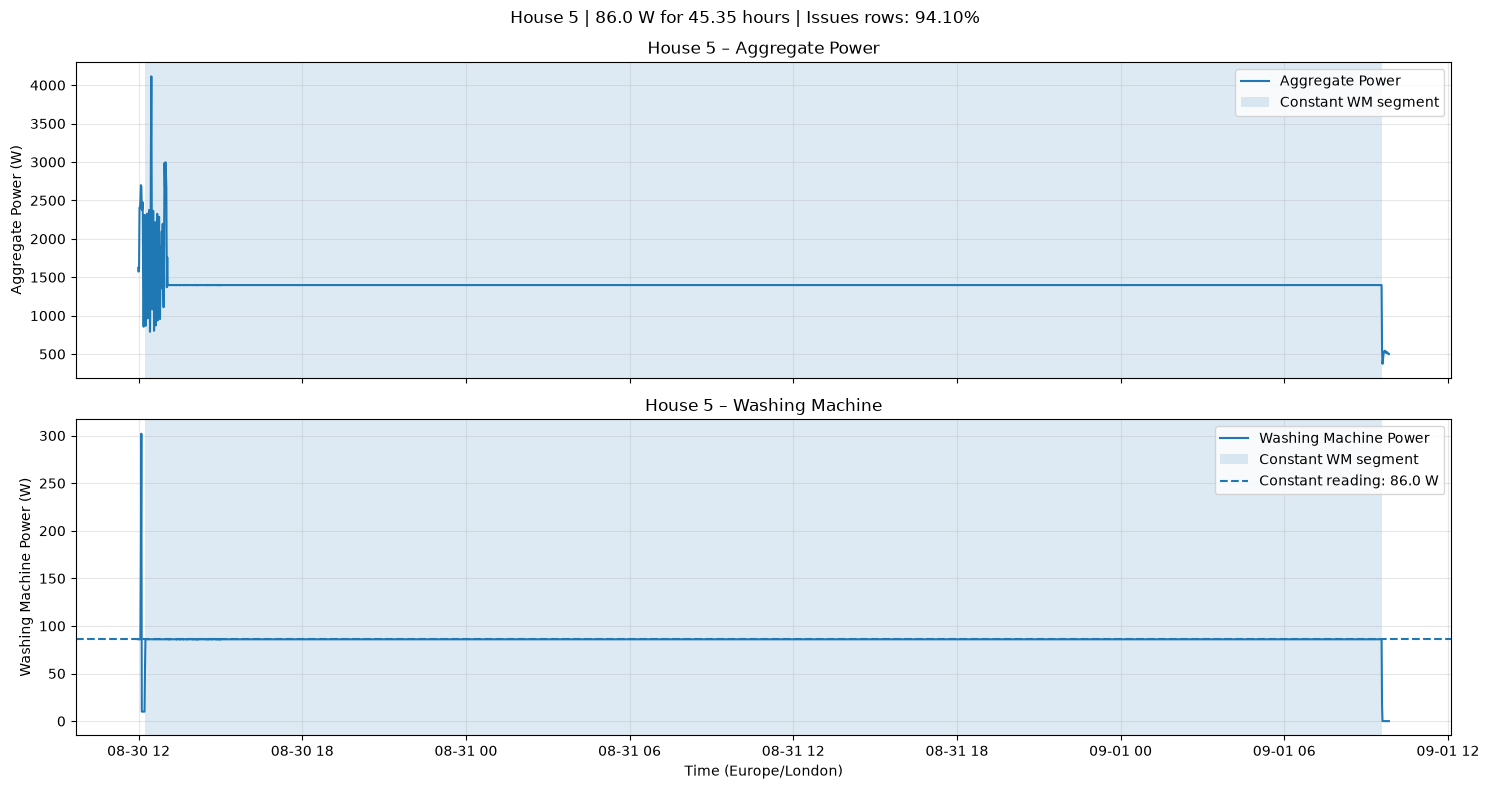


Inspecting House 7
Event 4: 266 observations


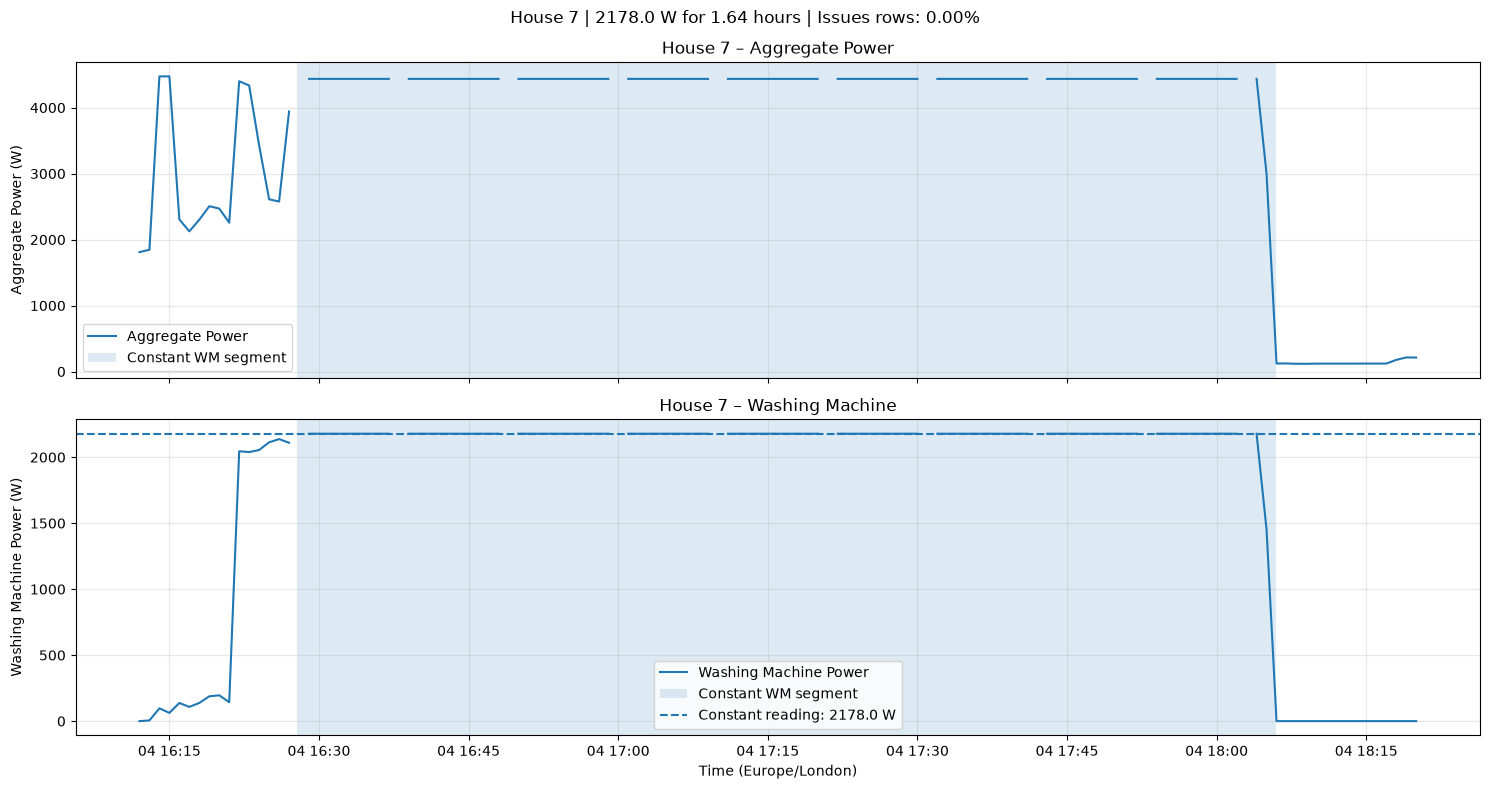

In [19]:
for house in sorted(SELECTED_EVENTS):

    house_events = event_specs[
        event_specs["House"] == house
    ]

    print(f"\nInspecting House {house}")

    extracted = extract_event_data(
        house,
        house_events
    )

    for idx in house_events.index:

        parts = extracted.get(idx, [])

        if not parts:
            print(f"Event {idx}: No observations extracted.")
            continue

        event_df = pd.concat(
            parts,
            ignore_index=True
        )

        print(
            f"Event {idx}:",
            len(event_df),
            "observations"
        )

        plot_event(
            house,
            event_specs.loc[idx, "Run_Index"],
            event_df
        )

final investigation

**Cell purpose:** Calculate event-level diagnostics to assess whether suspicious washing-machine readings are supported by the aggregate signal.

In [20]:
event_diagnostics = []

for house in sorted(SELECTED_EVENTS):

    house_events = event_specs[
        event_specs["House"] == house
    ]

    extracted = extract_event_data(
        house,
        house_events,
        padding_minutes=0
    )

    wm_column = WM_MAPPING[house]

    for idx, event in house_events.iterrows():

        parts = extracted.get(idx, [])

        if not parts:
            continue

        df = pd.concat(parts, ignore_index=True)

        # Use only the exact event interval
        core = df[
            df["Unix"].between(
                event["Start_Unix"],
                event["End_Unix"]
            )
        ]

        wm = core[wm_column]
        aggregate = core["Aggregate"]
        issues = core["Issues"]

        event_diagnostics.append({

            "House": house,

            "Power_W": event["Power_W"],

            "Duration_Hours": (
                event["Duration_Min"] / 60
            ),

            "WM_Unique_Values": wm.nunique(),

            "WM_Std": wm.std(),

            "WM_Changes": wm.diff().ne(0).sum() - 1,

            "WM_Target_Value_Pct": (
                wm.eq(event["Power_W"]).mean() * 100
            ),

            "Aggregate_Unique_Values": (
                aggregate.nunique()
            ),

            "Aggregate_Std": aggregate.std(),

            "Aggregate_Changes": (
                aggregate.diff().ne(0).sum() - 1
            ),

            "Issues_Pct": issues.eq(1).mean() * 100

        })


event_diagnostics_df = pd.DataFrame(
    event_diagnostics
)

display(
    event_diagnostics_df.round(2).to_string(index=False)
)

' House  Power_W  Duration_Hours  WM_Unique_Values  WM_Std  WM_Changes  WM_Target_Value_Pct  Aggregate_Unique_Values  Aggregate_Std  Aggregate_Changes  Issues_Pct\n     1   2256.0            2.81                 2   57.56           1                99.93                        2         310.17                  1        0.00\n     5      3.0           99.51                 1    0.00           0               100.00                     2561         777.79              32033        3.22\n     5     64.0           47.78                 2    0.41           1               100.00                     1499         561.31              22159        1.34\n     5     86.0           45.35                 2    1.21           1                99.98                      298         264.14                351       97.42\n     7   2178.0            1.64                 2  225.85           1                98.92                        2         447.44                  1        0.00'

Next experiment – inspect ALL appliance channels
Cell 1 – Extract all appliance readings for selected events

**Cell purpose:** Define a chunked extraction function for retrieving all appliance channels around the selected suspicious events.

In [21]:
POWER_COLUMNS = [
    "Aggregate",
    *[f"Appliance{i}" for i in range(1, 10)]
]

def extract_all_channel_events(
    house,
    events,
    chunksize=200_000
):

    path = HOUSE_FILES[house]

    usecols = ["Unix"] + POWER_COLUMNS + ["Issues"]

    buffers = {idx: [] for idx in events.index}

    min_start = events["Start_Unix"].min()
    max_end = events["End_Unix"].max()

    for chunk in pd.read_csv(
        path,
        usecols=usecols,
        chunksize=chunksize
    ):

        if chunk["Unix"].iloc[-1] < min_start:
            continue

        if chunk["Unix"].iloc[0] > max_end:
            break

        for idx, event in events.iterrows():

            mask = chunk["Unix"].between(
                event["Start_Unix"],
                event["End_Unix"]
            )

            if mask.any():
                buffers[idx].append(
                    chunk.loc[mask].copy()
                )

    return {
        idx: pd.concat(parts, ignore_index=True)
        for idx, parts in buffers.items()
        if parts
    }

Calculate channel-wise statistics

**Cell purpose:** Compare appliance-channel statistics and Issues flags within the selected event windows.

In [22]:
events_to_check = event_specs[
    (
        ((event_specs["House"] == 1) &
         (event_specs["Power_W"] == 2256))
        |
        ((event_specs["House"] == 5) &
         (event_specs["Power_W"].isin([3, 64, 86])))
        |
        ((event_specs["House"] == 7) &
         (event_specs["Power_W"] == 2178))
    )
]

channel_results = []

for house in sorted(events_to_check["House"].unique()):

    house_events = events_to_check[
        events_to_check["House"] == house
    ]

    extracted_events = extract_all_channel_events(
        house,
        house_events
    )

    for event_id, event in house_events.iterrows():

        df = extracted_events.get(event_id)

        if df is None or df.empty:
            continue

        for col in POWER_COLUMNS:

            values = df[col]

            frequencies = values.value_counts()

            channel_results.append({

                "House": house,
                "Event_Power_W": event["Power_W"],
                "Channel": col,

                "Unique_Values": values.nunique(),

                "Dominant_Value_W": frequencies.index[0],

                "Dominant_Value_Pct": (
                    frequencies.iloc[0] / len(values) * 100
                ),

                "Changes": values.diff().ne(0).sum() - 1,

                "Std_W": values.std(),

                "Min_W": values.min(),

                "Max_W": values.max(),

                "Issues_Pct": (
                    df["Issues"].eq(1).mean() * 100
                )
            })


channel_diagnostics = pd.DataFrame(channel_results)

display(
    channel_diagnostics.round(2).to_string(index=False)
)

' House  Event_Power_W    Channel  Unique_Values  Dominant_Value_W  Dominant_Value_Pct  Changes  Std_W  Min_W  Max_W  Issues_Pct\n     1         2256.0  Aggregate              2             12505               99.93        1 310.17    349  12505        0.00\n     1         2256.0 Appliance1              1                 0              100.00        0   0.00      0      0        0.00\n     1         2256.0 Appliance2              1                 0              100.00        0   0.00      0      0        0.00\n     1         2256.0 Appliance3              2                73               99.93        1   1.86      0     73        0.00\n     1         2256.0 Appliance4              1                 0              100.00        0   0.00      0      0        0.00\n     1         2256.0 Appliance5              2              2256               99.93        1  57.56      0   2256        0.00\n     1         2256.0 Appliance6              1                 0              100.00        0  

### Signal Quality Investigation – Event-level Findings

Selected long-duration constant-power events were investigated
using aggregate and individual appliance measurements.

Key observations:

1. House 1:
   A 2256 W washing-machine reading remained nearly constant
   for approximately 2.81 hours. Aggregate power also remained
   nearly constant. The event is flagged as uncertain.

2. House 5:
   - A 3 W reading persisted for approximately 99.51 hours.
     This is treated as potential standby consumption.
   - A 64 W reading persisted for approximately 47.78 hours
     while other household signals continued changing.
     This interval is flagged as suspicious.
   - An 86 W reading persisted for approximately 45.35 hours.
     The interval had approximately 97.42% Issues observations
     and is classified as unreliable.

3. House 7:
   A 2178 W washing-machine reading persisted for approximately
   1.64 hours. Aggregate power also remained nearly constant.
   The event is flagged as uncertain.

Methodological decision:

- Suspicious events will be flagged at interval level.
- Data will not be deleted automatically.
- Intervals with strong data-quality evidence will be excluded
  from reliable activation analysis.
- Household selection will consider overall data quality,
  not individual suspicious events alone.

## Step 5 — Verify Timestamp and Timezone Consistency


### Compare the REFIT Time Field with Unix-Derived UTC Timestamps

**Cell purpose:** Compare the REFIT Time field with Unix-derived UTC timestamps to verify timestamp consistency.

In [23]:
def compare_time_with_utc(path, chunksize=200_000):

    results = []

    for chunk in pd.read_csv(
        path,
        usecols=["Time", "Unix"],
        chunksize=chunksize
    ):

        supplied = pd.to_datetime(
            chunk["Time"],
            errors="coerce"
        )

        unix_utc = pd.to_datetime(
            chunk["Unix"],
            unit="s",
            utc=True,
            errors="coerce"
        ).dt.tz_localize(None)

        offsets = (supplied - unix_utc).dt.total_seconds()

        temp = pd.DataFrame({
            "Month": supplied.dt.to_period("M"),
            "Offset_Seconds": offsets
        })

        results.append(
            temp.groupby(["Month", "Offset_Seconds"])
            .size()
        )

    return (
        pd.concat(results)
        .groupby(level=[0, 1])
        .sum()
        .unstack(fill_value=0)
    )


utc_check = compare_time_with_utc(HOUSE_FILES[1])

display(utc_check)

Offset_Seconds,0.0
Month,
2013-10,311376
2013-11,346065
2013-12,368266
2014-01,308916
2014-03,356242
2014-04,363981
2014-05,366985
2014-06,382266
2014-07,329559


## Step 6 — Examine Native-Resolution Washing-Machine Power Behaviour

### Native-Resolution Washing-Machine Power Distribution

**Objective:** Examine the range and frequency of washing-machine power readings before choosing an activation threshold. The analysis uses the native cleaned-data observations and time-weighted exposure.


### Build Native-Resolution Power-Distribution Summaries

**Cell purpose:** Define a function that summarizes native-resolution washing-machine power values and associated Issues readings.

In [24]:
from collections import Counter

def analyse_wm_distribution(
    house,
    path,
    wm_column,
    chunksize=200_000
):

    counts = Counter()
    issue_counts = Counter()

    total_rows = 0
    total_issues = 0

    for chunk in pd.read_csv(
        path,
        usecols=[wm_column, "Issues"],
        chunksize=chunksize
    ):

        power = chunk[wm_column]

        counts.update(
            power.value_counts().to_dict()
        )

        for threshold in [10, 20, 30, 50]:

            mask = power > threshold

            issue_counts[threshold] += int(
                (mask & chunk["Issues"].eq(1)).sum()
            )

        total_rows += len(chunk)
        total_issues += chunk["Issues"].eq(1).sum()

    def count_above(threshold):

        return sum(
            count
            for value, count in counts.items()
            if value > threshold
        )

    result = {
        "House": house,
        "Total_Rows": total_rows,
        "Distinct_Values": len(counts),
        "Max_Power_W": max(counts),
        "Median_All_W": weighted_quantile(counts, 0.50),
        "P90_All_W": weighted_quantile(counts, 0.90),
        "P95_All_W": weighted_quantile(counts, 0.95),
        "P99_All_W": weighted_quantile(counts, 0.99),
        "Issues_Pct": total_issues / total_rows * 100
    }

    positive_counts = Counter({
        value: count
        for value, count in counts.items()
        if value > 0
    })

    result["Median_Positive_W"] = (
        weighted_quantile(positive_counts, 0.50)
    )

    result["P95_Positive_W"] = (
        weighted_quantile(positive_counts, 0.95)
    )

    for threshold in [10, 20, 30, 50]:

        active_count = count_above(threshold)

        result[f"Above_{threshold}W_Count"] = active_count

        result[f"Above_{threshold}W_Pct"] = (
            active_count / total_rows * 100
        )

        result[f"Issues_Above_{threshold}W_Pct"] = (
            issue_counts[threshold] / active_count * 100
            if active_count else np.nan
        )

    return result, counts

**Cell purpose:** Apply the native-resolution power-distribution analysis to the candidate households and display the summaries.

In [25]:
distribution_results = []
power_distributions = {}

for house, path in HOUSE_FILES.items():

    print(f"Processing House {house}...")

    result, counts = analyse_wm_distribution(
        house,
        path,
        WM_MAPPING[house]
    )

    distribution_results.append(result)
    power_distributions[house] = counts

wm_distribution_summary = pd.DataFrame(
    distribution_results
)

display(
    wm_distribution_summary.round(2)
)

Processing House 1...
Processing House 2...
Processing House 5...
Processing House 6...
Processing House 7...


,House,Total_Rows,Distinct_Values,Max_Power_W,Median_All_W,P90_All_W,P95_All_W,P99_All_W,Issues_Pct,Median_Positive_W,...,Issues_Above_10W_Pct,Above_20W_Count,Above_20W_Pct,Issues_Above_20W_Pct,Above_30W_Count,Above_30W_Pct,Issues_Above_30W_Pct,Above_50W_Count,Above_50W_Pct,Issues_Above_50W_Pct
0,1,6960008,876,3072,0,0,0,139,0.84,115,...,11.28,114389,1.64,12.07,107187,1.54,12.78,101103,1.45,13.48
1,2,5733526,807,3584,0,0,5,227,0.50,74,...,3.88,213809,3.73,4.29,196190,3.42,4.63,179447,3.13,4.99
2,5,7430755,1045,2437,0,4,75,552,5.73,3,...,19.61,508070,6.84,20.95,476614,6.41,21.81,445525,6.00,22.78
3,6,6241971,767,3968,0,0,0,129,0.55,91,...,2.80,87200,1.40,2.95,84596,1.36,3.03,82415,1.32,3.09
4,7,6756034,843,3584,0,1,110,1991,2.40,2,...,10.01,462870,6.85,10.19,441947,6.54,10.50,423168,6.26,10.79


Time-weighted power distribution

Time-weighted analysis function

**Cell purpose:** Define a time-weighted distribution function so each reading contributes only over its valid interval to the next timestamp.

In [26]:
from collections import Counter


def time_weighted_distribution(
    path,
    wm_column,
    chunksize=200_000,
    max_gap_sec=120
):

    power_seconds = Counter()

    thresholds = [10, 20, 30, 50]

    above_seconds = {t: 0 for t in thresholds}
    issues_above_seconds = {t: 0 for t in thresholds}

    total_valid_seconds = 0
    zero_seconds = 0
    issue_seconds = 0

    total_energy_wh = 0

    long_gap_count = 0
    long_gap_seconds = 0

    previous = None

    for chunk in pd.read_csv(
        path,
        usecols=["Unix", wm_column, "Issues"],
        chunksize=chunksize
    ):

        unix = chunk["Unix"].to_numpy(dtype=np.int64)
        power = chunk[wm_column].to_numpy(dtype=np.int32)
        issues = chunk["Issues"].to_numpy(dtype=np.int8)

        # Connect the last observation from the previous chunk
        if previous is not None:

            unix = np.r_[previous[0], unix]
            power = np.r_[previous[1], power]
            issues = np.r_[previous[2], issues]

        # Duration represented by each observation
        dt = np.diff(unix)

        current_power = power[:-1]
        current_issues = issues[:-1]

        valid = (
            (dt > 0) &
            (dt <= max_gap_sec)
        )

        long_gaps = dt > max_gap_sec

        total_valid_seconds += int(dt[valid].sum())

        long_gap_count += int(long_gaps.sum())
        long_gap_seconds += int(dt[long_gaps].sum())

        zero_mask = valid & (current_power == 0)

        zero_seconds += int(dt[zero_mask].sum())

        issue_mask = valid & (current_issues == 1)

        issue_seconds += int(dt[issue_mask].sum())

        # Energy integration
        total_energy_wh += float(
            np.sum(
                current_power[valid].astype(float)
                * dt[valid]
            ) / 3600
        )

        # Time spent at every power value
        grouped = (
            pd.Series(dt[valid])
            .groupby(current_power[valid])
            .sum()
        )

        for value, seconds in grouped.items():
            power_seconds[int(value)] += int(seconds)

        # Threshold-specific time analysis
        for threshold in thresholds:

            active = (
                valid &
                (current_power > threshold)
            )

            above_seconds[threshold] += int(
                dt[active].sum()
            )

            issues_active = active & (current_issues == 1)

            issues_above_seconds[threshold] += int(
                dt[issues_active].sum()
            )

        # Carry last observation forward for the next chunk
        previous = (
            unix[-1],
            power[-1],
            issues[-1]
        )

    def weighted_percentile(counter, q):

        return weighted_quantile(counter, q)

    total_positive = Counter({
        p: seconds
        for p, seconds in power_seconds.items()
        if p > 0
    })

    result = {

        "Observed_Hours": total_valid_seconds / 3600,

        "Long_Gap_Count": long_gap_count,

        "Long_Gap_Hours": long_gap_seconds / 3600,

        "Zero_Time_Pct": (
            zero_seconds / total_valid_seconds * 100
            if total_valid_seconds else np.nan
        ),

        "Issues_Time_Pct": (
            issue_seconds / total_valid_seconds * 100
            if total_valid_seconds else np.nan
        ),

        "Median_Positive_W_TimeWeighted":
            weighted_percentile(total_positive, 0.50),

        "P95_Positive_W_TimeWeighted":
            weighted_percentile(total_positive, 0.95),

        "Total_Energy_kWh":
            total_energy_wh / 1000
    }

    for threshold in thresholds:

        result[f"Above_{threshold}W_TimePct"] = (
            above_seconds[threshold]
            / total_valid_seconds * 100
            if total_valid_seconds else np.nan
        )

        result[f"Issues_Above_{threshold}W_TimePct"] = (
            issues_above_seconds[threshold]
            / above_seconds[threshold] * 100
            if above_seconds[threshold] else np.nan
        )

    return result, power_seconds

**Cell purpose:** Calculate time-weighted washing-machine power distributions and monitoring statistics for all candidate households.

In [27]:
time_weighted_results = []
time_weighted_distributions = {}

for house, path in HOUSE_FILES.items():

    print(f"Processing House {house}...")

    result, power_seconds = time_weighted_distribution(
        path=path,
        wm_column=WM_MAPPING[house]
    )

    result["House"] = house

    time_weighted_results.append(result)

    time_weighted_distributions[house] = power_seconds

    print(f"House {house} completed.")


time_weighted_summary = pd.DataFrame(
    time_weighted_results
)

display(
    time_weighted_summary.round(2).to_string(index=False)
)

Processing House 1...
House 1 completed.
Processing House 2...
House 2 completed.
Processing House 5...
House 5 completed.
Processing House 6...
House 6 completed.
Processing House 7...
House 7 completed.


' Observed_Hours  Long_Gap_Count  Long_Gap_Hours  Zero_Time_Pct  Issues_Time_Pct  Median_Positive_W_TimeWeighted  P95_Positive_W_TimeWeighted  Total_Energy_kWh  Above_10W_TimePct  Issues_Above_10W_TimePct  Above_20W_TimePct  Issues_Above_20W_TimePct  Above_30W_TimePct  Issues_Above_30W_TimePct  Above_50W_TimePct  Issues_Above_50W_TimePct  House\n       13390.95             659         1943.89          97.76             0.82                             114                         2332            145.74               1.76                     11.22               1.64                     12.02               1.53                     12.73               1.44                     13.45      1\n       11163.98             597         3653.97          94.45             0.49                              74                         2066            201.82               4.16                      3.89               3.71                      4.31               3.41                      4.65            

## Step 7 — Compare Candidate Households and Select the Primary Cohort

### Compare Household Data Quality Before Selecting the Primary Cohort

**Cell purpose:** Combine the time-weighted results into a household-quality comparison, including observed time, gaps and activity exposure.

In [28]:
# Create a combined household quality summary

final_quality = time_weighted_summary.copy()

# Total monitoring span
final_quality["Total_Span_Hours"] = (
    final_quality["Observed_Hours"]
    + final_quality["Long_Gap_Hours"]
)

# Monitoring coverage
final_quality["Coverage_Pct"] = (
    final_quality["Observed_Hours"]
    / final_quality["Total_Span_Hours"]
    * 100
)

# Gap percentage
final_quality["Gap_Pct"] = (
    100 - final_quality["Coverage_Pct"]
)

# Normalize energy by observed monitoring days
final_quality["Observed_Days"] = (
    final_quality["Observed_Hours"] / 24
)

final_quality["Raw_kWh_Per_Observed_Day"] = (
    final_quality["Total_Energy_kWh"]
    / final_quality["Observed_Days"]
)

# Calculate time spent above 20W with Issues == 0
final_quality["Above_20W_Clean_TimePct"] = (
    final_quality["Above_20W_TimePct"]
    * (1 - final_quality["Issues_Above_20W_TimePct"] / 100)
)

quality_columns = [
    "House",
    "Observed_Hours",
    "Total_Span_Hours",
    "Coverage_Pct",
    "Gap_Pct",
    "Issues_Time_Pct",
    "Above_20W_TimePct",
    "Issues_Above_20W_TimePct",
    "Above_20W_Clean_TimePct",
    "Total_Energy_kWh",
    "Raw_kWh_Per_Observed_Day"
]

display(
    final_quality[quality_columns]
    .round(3)
    .to_string(index=False)
)

' House  Observed_Hours  Total_Span_Hours  Coverage_Pct  Gap_Pct  Issues_Time_Pct  Above_20W_TimePct  Issues_Above_20W_TimePct  Above_20W_Clean_TimePct  Total_Energy_kWh  Raw_kWh_Per_Observed_Day\n     1       13390.950         15334.838        87.324   12.676            0.818              1.637                    12.018                    1.440           145.742                     0.261\n     2       11163.984         14817.959        75.341   24.659            0.489              3.715                     4.312                    3.554           201.818                     0.434\n     5       14097.429         15559.879        90.601    9.399            5.777              7.113                    22.878                    5.486           445.376                     0.758\n     6       11759.081         13857.986        84.854   15.146            0.565              1.391                     2.893                    1.351            83.282                     0.170\n     7       12863.

### Audit Long, High-Power Flatline Behaviour Before Finalizing the Cohort

**Cell purpose:** Define an audit for unusually long, nearly constant washing-machine readings above the selected low-power threshold.

In [29]:
def high_power_flatline_audit(
    path,
    wm_column,
    threshold=20,
    max_gap_sec=120
):

    df = pd.read_csv(
        path,
        usecols=["Unix", wm_column, "Issues"],
        dtype={
            "Unix": "int64",
            wm_column: "int32",
            "Issues": "int8"
        }
    )

    unix = df["Unix"].to_numpy()
    power = df[wm_column].to_numpy()
    issues = df["Issues"].to_numpy()

    del df

    intervals = np.diff(unix)

    valid_intervals = (
        (intervals > 0) &
        (intervals <= max_gap_sec)
    )

    typical_interval = np.median(
        intervals[valid_intervals]
    )

    # New run when power changes or a monitoring gap occurs
    boundaries = (
        (power[1:] != power[:-1]) |
        (~valid_intervals)
    )

    starts = np.r_[0, np.flatnonzero(boundaries) + 1]
    ends = np.r_[starts[1:], len(power)]

    run_power = power[starts]
    run_lengths = ends - starts

    run_duration = np.zeros(len(starts))

    for i, end in enumerate(ends):

        last = end - 1

        if end < len(unix):

            gap = unix[end] - unix[last]

            if 0 < gap <= max_gap_sec:
                end_time = unix[end]
            else:
                end_time = unix[last] + typical_interval

        else:
            end_time = unix[last] + typical_interval

        run_duration[i] = max(
            0,
            end_time - unix[starts[i]]
        )

    # Issues percentage within each constant run
    run_issue_count = np.add.reduceat(issues, starts)

    run_issues_pct = (
        run_issue_count / run_lengths * 100
    )

    total_observed_seconds = intervals[
        valid_intervals
    ].sum()

    results = []

    for minimum_minutes in [30, 60, 120]:

        mask = (
            (run_power > threshold) &
            (run_duration >= minimum_minutes * 60)
        )

        selected = run_duration[mask]

        results.append({

            "Minimum_Duration_Min": minimum_minutes,

            "Constant_Runs": int(mask.sum()),

            "Total_Flatline_Hours": (
                selected.sum() / 3600
            ),

            "Maximum_Flatline_Hours": (
                selected.max() / 3600
                if len(selected) else 0
            ),

            "Share_Of_Observed_Time_Pct": (
                selected.sum() / total_observed_seconds * 100
                if total_observed_seconds else np.nan
            ),

            "Issues_Pct_In_Runs": (
                np.average(
                    run_issues_pct[mask],
                    weights=selected
                )
                if mask.any() else np.nan
            )
        })

    return pd.DataFrame(results)

**Cell purpose:** Run the high-power flatline audit across candidate households and compare the resulting suspicious intervals.

In [30]:
flatline_results = []

for house, path in HOUSE_FILES.items():

    print(f"Checking House {house}...")

    result = high_power_flatline_audit(
        path,
        WM_MAPPING[house],
        threshold=20
    )

    result.insert(0, "House", house)

    flatline_results.append(result)

    print(f"House {house} completed.")

high_power_flatline_summary = pd.concat(
    flatline_results,
    ignore_index=True
)

display(
    high_power_flatline_summary.round(3)
)

Checking House 1...
House 1 completed.
Checking House 2...
House 2 completed.
Checking House 5...
House 5 completed.
Checking House 6...
House 6 completed.
Checking House 7...
House 7 completed.


,House,Minimum_Duration_Min,Constant_Runs,Total_Flatline_Hours,Maximum_Flatline_Hours,Share_Of_Observed_Time_Pct,Issues_Pct_In_Runs
0,1,30,5,6.466,2.811,0.048,34.477
1,1,60,2,4.461,2.811,0.033,36.989
2,1,120,1,2.811,2.811,0.021,0.000
3,2,30,1,0.716,0.716,0.006,46.770
4,2,60,0,0.000,0.000,0.000,NaN
5,2,120,0,0.000,0.000,0.000,NaN
6,5,30,127,372.244,47.778,2.641,38.853
7,5,60,65,330.343,47.778,2.343,40.170
8,5,120,32,284.299,47.778,2.017,42.994
9,6,30,0,0.000,0.000,0.000,NaN


### Household Selection and Data Quality Assessment

Five candidate households were initially investigated:
Houses 1, 2, 5, 6 and 7.

The selection was based on:
- Monitoring coverage.
- Washing-machine signal behaviour.
- Aggregate/submeter consistency.
- Long-duration constant-power episodes.
- Availability of usable observations.

### Selected households

| House | WM Channel | Coverage | Decision |
|---|---|---:|---|
| 1 | Appliance5 | 87.32% | Include |
| 2 | Appliance2 | 75.34% | Include |
| 6 | Appliance2 | 84.85% | Include |
| 7 | Appliance5 | 87.41% | Include |
| 5 | Appliance3 | 90.60% | Secondary analysis |

House 5 had 127 non-zero constant-power runs lasting at least
30 minutes, covering approximately 372 hours (2.64% of
operationally observed time). Several intervals also showed
elevated Issues percentages and unusual channel behaviour.

Therefore, House 5 is retained for supplementary investigation
but excluded from the primary four-household analysis.

### Treatment of suspicious observations

- Issues=1 observations will be flagged and examined through
  sensitivity analysis.
- Long-duration constant-power episodes will be flagged.
- Identified unreliable intervals will not contribute to
  primary activation statistics.
- Raw cleaned REFIT files will remain unchanged.

Household selection does not imply that the selected households
are completely error-free.

## Step 8 — Visualize Native-Resolution Power Distributions

### Visualize Native-Resolution Power Distributions

**Cell purpose:** Prepare descriptive power-distribution statistics for the selected primary households using time-weighted observations.

In [31]:
from collections import Counter
import numpy as np
import pandas as pd

PRIMARY_HOUSES = [1, 2, 6, 7]

power_summary = []

for house in PRIMARY_HOUSES:

    distribution = time_weighted_distributions[house]

    # Total observed duration
    total_seconds = sum(distribution.values())

    # Zero-power duration
    zero_seconds = distribution.get(0, 0)

    # Positive-power distribution
    positive_distribution = Counter({
        power: seconds
        for power, seconds in distribution.items()
        if power > 0
    })

    positive_seconds = sum(positive_distribution.values())

    power_summary.append({

        "House": house,

        "Observed_Hours": total_seconds / 3600,

        "Zero_Time_Pct": (
            zero_seconds / total_seconds * 100
        ),

        "Positive_Time_Pct": (
            positive_seconds / total_seconds * 100
        ),

        "Median_All_W": weighted_quantile(
            distribution, 0.50
        ),

        "Median_Positive_W": weighted_quantile(
            positive_distribution, 0.50
        ),

        "P90_Positive_W": weighted_quantile(
            positive_distribution, 0.90
        ),

        "P95_Positive_W": weighted_quantile(
            positive_distribution, 0.95
        ),

        "P99_Positive_W": weighted_quantile(
            positive_distribution, 0.99
        )
    })


power_summary_df = pd.DataFrame(power_summary)

display(power_summary_df.round(2))

,House,Observed_Hours,Zero_Time_Pct,Positive_Time_Pct,Median_All_W,Median_Positive_W,P90_Positive_W,P95_Positive_W,P99_Positive_W
0,1,13390.95,97.76,2.24,0,114,2256,2332,2413
1,2,11163.98,94.45,5.55,0,74,2013,2066,2119
2,6,11759.08,97.55,2.45,0,86,1863,2036,2119
3,7,12863.91,84.06,15.94,0,2,390,2029,2140


### Plot 1 — Household Power-Distribution Histograms

**Cell purpose:** Plot household-wise histograms to compare the distribution of positive washing-machine power readings.

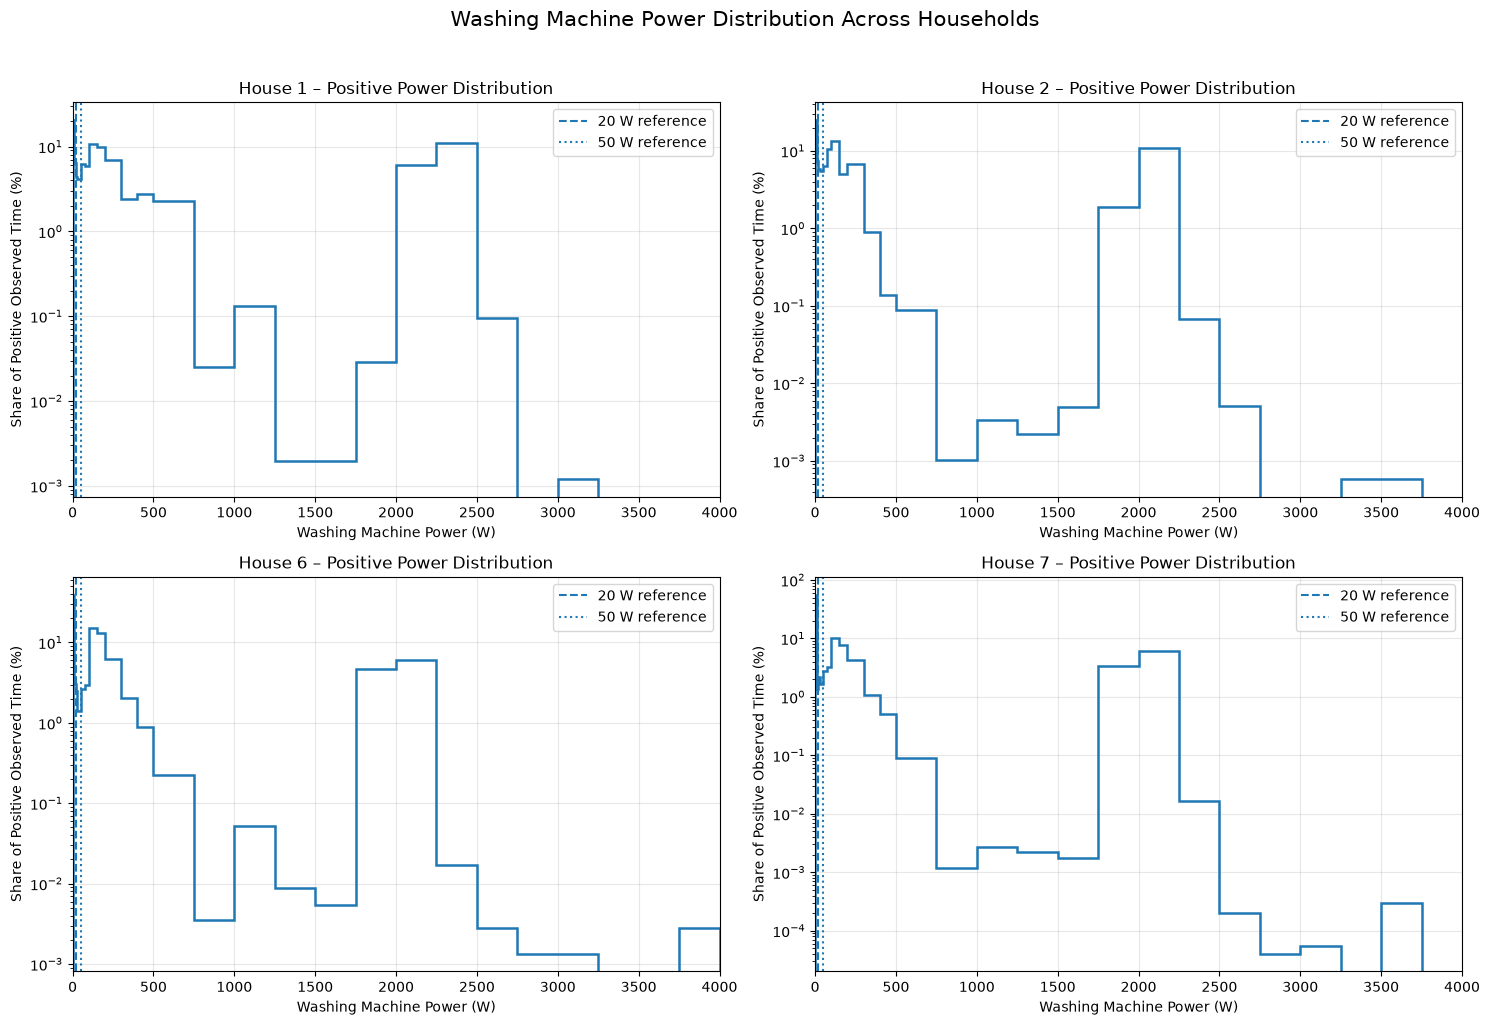

Histogram saved at: /Users/rehaanraza/Desktop/assessmentFlock/refit-nilm/outputs/figures/wm_power_distribution.png


In [35]:
import matplotlib.pyplot as plt
import numpy as np

# Create output directory
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Power ranges in Watts
POWER_BINS = [
    0, 10, 20, 30, 50, 75, 100, 150,
    200, 300, 400, 500, 750, 1000,
    1250, 1500, 1750, 2000, 2250,
    2500, 2750, 3000, 3250, 3500,
    3750, 4000
]

# Create 2x2 subplot layout
hist_fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 10)
)

axes = axes.flatten()

# Analyse each selected household
for ax, house in zip(axes, PRIMARY_HOUSES):

    distribution = time_weighted_distributions[house]

    # Keep only positive power readings
    positive = {
        power: seconds
        for power, seconds in distribution.items()
        if power > 0
    }

    powers = np.array(list(positive.keys()))

    seconds = np.array(list(positive.values()))

    # Convert observed duration into percentage
    weights = (
        seconds / seconds.sum() * 100
    )

    # Plot histogram
    ax.hist(
        powers,
        bins=POWER_BINS,
        weights=weights,
        histtype="step",
        linewidth=1.8
    )

    # Reference threshold lines
    ax.axvline(
        20,
        linestyle="--",
        label="20 W reference"
    )

    ax.axvline(
        50,
        linestyle=":",
        label="50 W reference"
    )

    # Logarithmic frequency scale
    ax.set_yscale("log")

    ax.set_xlim(0, 4000)

    # Titles and labels
    ax.set_title(
        f"House {house} – Positive Power Distribution"
    )

    ax.set_xlabel(
        "Washing Machine Power (W)"
    )

    ax.set_ylabel(
        "Share of Positive Observed Time (%)"
    )

    ax.grid(alpha=0.3)

    ax.legend()


# Overall figure title
hist_fig.suptitle(
    "Washing Machine Power Distribution Across Households",
    fontsize=15,
    y=1.02
)

hist_fig.tight_layout()

# Save figure
hist_fig.savefig(
    FIGURE_DIR / "wm_power_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Histogram saved at:",
    FIGURE_DIR / "wm_power_distribution.png"
)

### Plot 2 — Empirical Cumulative Distribution Function (ECDF)

**Cell purpose:** Plot an empirical cumulative distribution function (ECDF) to compare positive power values across households.

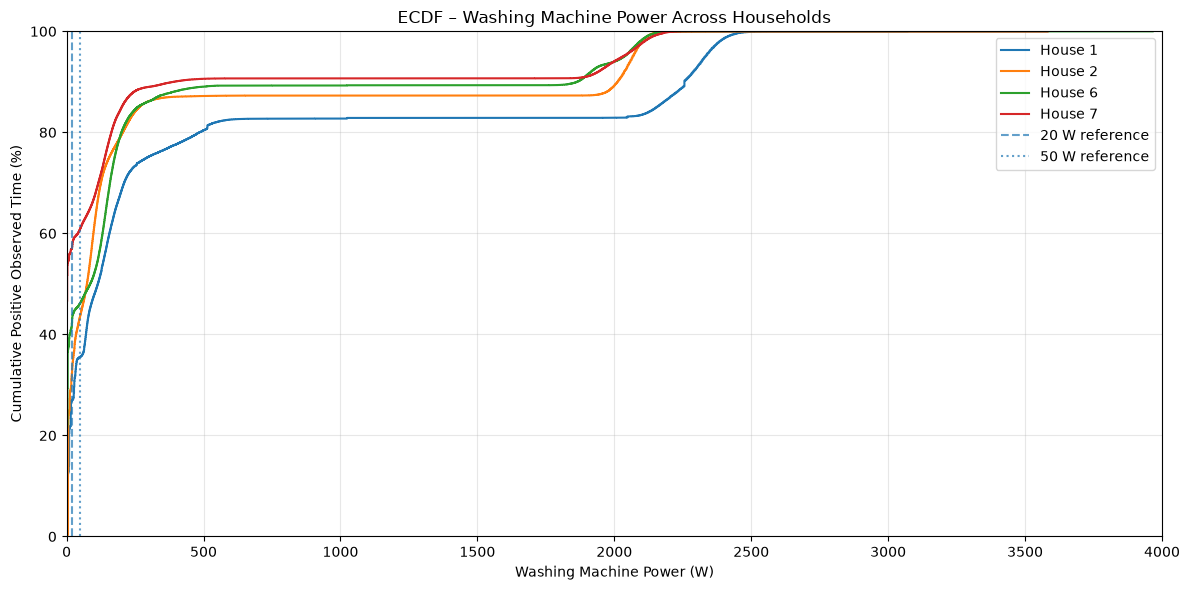

In [33]:
fig, ax = plt.subplots(figsize=(12, 6))

for house in PRIMARY_HOUSES:

    distribution = time_weighted_distributions[house]

    # Only positive readings
    positive = {
        power: seconds
        for power, seconds in distribution.items()
        if power > 0
    }

    # Sort power values
    powers = np.array(sorted(positive.keys()))

    durations = np.array([
        positive[power]
        for power in powers
    ])

    # Cumulative proportion of positive observed time
    cumulative = (
        np.cumsum(durations)
        / durations.sum() * 100
    )

    ax.step(
        powers,
        cumulative,
        where="post",
        label=f"House {house}"
    )


ax.axvline(
    20,
    linestyle="--",
    alpha=0.7,
    label="20 W reference"
)

ax.axvline(
    50,
    linestyle=":",
    alpha=0.7,
    label="50 W reference"
)

ax.set_xlabel("Washing Machine Power (W)")

ax.set_ylabel(
    "Cumulative Positive Observed Time (%)"
)

ax.set_title(
    "ECDF – Washing Machine Power Across Households"
)

ax.set_xlim(0, 4000)

ax.set_ylim(0, 100)

ax.grid(alpha=0.3)

ax.legend()

plt.tight_layout()

plt.show()

### Save the Native-Resolution Distribution Figures

**Cell purpose:** Create the figure output directory and save the current power-distribution visualization at high resolution.

In [34]:
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Save histogram
fig.savefig(
    FIGURE_DIR / "wm_power_ecdf.png",
    dpi=300,
    bbox_inches="tight"
)

### Power Distribution – Initial Findings

The positive-power distributions reveal different consumption
patterns across the four selected households.

Key observations:

1. All households show substantial low-power readings.
2. A separate high-power concentration is visible around
   approximately 1900–2300 W.
3. Households differ in the proportion and spread of
   low-power and high-power readings.
4. Positive power readings cannot automatically be
   classified as active washing-machine operation.

The histogram and ECDF are diagnostic visualizations based
on native cleaned-data timestamps and elapsed-time weighting.

These distributions will help guide activation threshold
experiments, but the final threshold will be validated using
one-minute power traces and sensitivity analysis.

## Step 9 — Resample the Primary Households to One-Minute Resolution


### Why One-Minute Resampling Is Used

**Objective:** Convert irregular native-resolution readings into one-minute, time-weighted aggregate and washing-machine measurements while preserving unavailable intervals as missing.


### Define the One-Minute Resampling Procedure

**Cell purpose:** Define a chunked, time-weighted resampling function that converts native readings into one-minute aggregate and appliance measurements.

In [36]:
def resample_house_to_1min(
    path,
    wm_column,
    chunksize=200_000,
    max_gap_sec=120
):

    partials = []
    previous = None

    total_rows = 0
    long_gap_count = 0
    long_gap_seconds = 0

    first_unix = None
    last_unix = None

    usecols = [
        "Unix",
        "Aggregate",
        wm_column,
        "Issues"
    ]

    for chunk in pd.read_csv(
        path,
        usecols=usecols,
        chunksize=chunksize
    ):

        total_rows += len(chunk)

        current_unix = chunk["Unix"].to_numpy(dtype=np.int64)
        current_agg = chunk["Aggregate"].to_numpy(dtype=np.int64)
        current_wm = chunk[wm_column].to_numpy(dtype=np.int64)
        current_issues = chunk["Issues"].to_numpy(dtype=np.int8)

        if first_unix is None:
            first_unix = current_unix[0]

        last_unix = current_unix[-1]

        # Carry the last observation across chunk boundaries
        if previous is not None:

            unix = np.r_[previous[0], current_unix]
            agg = np.r_[previous[1], current_agg]
            wm = np.r_[previous[2], current_wm]
            issues = np.r_[previous[3], current_issues]

        else:

            unix = current_unix
            agg = current_agg
            wm = current_wm
            issues = current_issues

        if len(unix) < 2:
            previous = (
                unix[-1], agg[-1], wm[-1], issues[-1]
            )
            continue

        # Interval between consecutive observations
        dt = np.diff(unix)

        valid = (
            (dt > 0) &
            (dt <= max_gap_sec)
        )

        long_gaps = dt > max_gap_sec

        long_gap_count += int(long_gaps.sum())
        long_gap_seconds += int(dt[long_gaps].sum())

        # Each interval is represented by the earlier reading
        start = unix[:-1][valid]
        end = unix[1:][valid]

        agg_power = agg[:-1][valid]
        wm_power = wm[:-1][valid]
        issue_flag = issues[:-1][valid]

        if len(start) == 0:

            previous = (
                current_unix[-1],
                current_agg[-1],
                current_wm[-1],
                current_issues[-1]
            )

            continue

        # Accumulate contributions into UTC minute buckets
        contributions = []

        base_minute = start // 60

        for offset in range(3):

            minute_id = base_minute + offset

            minute_start = minute_id * 60

            overlap = (
                np.minimum(end, minute_start + 60)
                - np.maximum(start, minute_start)
            )

            mask = overlap > 0

            if not mask.any():
                continue

            duration = overlap[mask].astype(np.int64)

            clean_mask = issue_flag[mask] == 0

            part = pd.DataFrame({

                "minute_id": minute_id[mask],

                "observed_seconds": duration,

                "aggregate_ws": (
                    agg_power[mask] * duration
                ),

                "wm_ws": (
                    wm_power[mask] * duration
                ),

                "issues_seconds": (
                    issue_flag[mask] * duration
                ),

                "clean_seconds": (
                    clean_mask * duration
                ),

                "wm_clean_ws": (
                    wm_power[mask]
                    * duration
                    * clean_mask
                ),

                "aggregate_clean_ws": (
                    agg_power[mask]
                    * duration
                    * clean_mask
                )
            })

            contributions.append(part)

        if contributions:

            chunk_result = pd.concat(
                contributions,
                ignore_index=True
            )

            chunk_result = (
                chunk_result
                .groupby("minute_id", as_index=False)
                .sum()
            )

            partials.append(chunk_result)

        # Save last actual row for the next chunk
        previous = (
            current_unix[-1],
            current_agg[-1],
            current_wm[-1],
            current_issues[-1]
        )

    if not partials:
        raise ValueError("No valid timestamp intervals found.")

    # Combine minute-level contributions from all chunks
    combined = (
        pd.concat(partials, ignore_index=True)
        .groupby("minute_id")
        .sum()
        .sort_index()
    )

    observed = combined["observed_seconds"]

    clean_observed = combined["clean_seconds"]

    # Calculate weighted power averages
    combined["Aggregate_W"] = (
        combined["aggregate_ws"] / observed
    )

    combined["Washing_Machine_W"] = (
        combined["wm_ws"] / observed
    )

    combined["WM_Issues0_W"] = (
        combined["wm_clean_ws"] / clean_observed.replace(0, np.nan)
    )

    combined["Aggregate_Issues0_W"] = (
        combined["aggregate_clean_ws"]
        / clean_observed.replace(0, np.nan)
    )

    combined["Issues_Time_Pct"] = (
        combined["issues_seconds"] / observed * 100
    )

    combined["Coverage_Pct"] = (
        observed / 60 * 100
    )

    combined["Issues0_Coverage_Sec"] = clean_observed

    # Convert minute ID to UTC datetime
    combined.index = pd.to_datetime(
        combined.index.to_numpy(dtype=np.int64) * 60,
        unit="s",
        utc=True
    )

    combined.index.name = "Timestamp_UTC"

    # Add missing minutes explicitly as NaN, not zero
    full_index = pd.date_range(
        start=combined.index.min(),
        end=combined.index.max(),
        freq="1min"
    )

    combined = combined.reindex(full_index)

    # Missing minute means no observed measurement
    combined["observed_seconds"] = (
        combined["observed_seconds"].fillna(0)
    )

    combined["Issues0_Coverage_Sec"] = (
        combined["Issues0_Coverage_Sec"].fillna(0)
    )

    # Add household-local time
    combined["Timestamp_London"] = (
        combined.index.tz_convert("Europe/London")
    )

    metadata = {

        "Total_Rows": total_rows,

        "Start_UTC": pd.to_datetime(
            first_unix,
            unit="s",
            utc=True
        ),

        "End_UTC": pd.to_datetime(
            last_unix,
            unit="s",
            utc=True
        ),

        "Observed_Hours": (
            observed.sum() / 3600
        ),

        "Long_Gap_Count": long_gap_count,

        "Long_Gap_Hours": (
            long_gap_seconds / 3600
        ),

        "Total_Minute_Bins": len(combined),

        "Empty_Minutes": int(
            (combined["observed_seconds"] == 0).sum()
        ),

        "Partially_Observed_Minutes": int(
            (
                (combined["observed_seconds"] > 0)
                & (combined["observed_seconds"] < 60)
            ).sum()
        )
    }

    return combined, metadata

**Cell purpose:** Resample Houses 1, 2, 6 and 7 to one-minute resolution and save the processed data for later analysis.

In [37]:
PRIMARY_HOUSES = [1, 2, 6, 7]

PROCESSED_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "section2_1min"
)

PROCESSED_DIR.mkdir(
    parents=True,
    exist_ok=True
)

resampled_summary = []

resampled_paths = {}

for house in PRIMARY_HOUSES:

    print(f"\nResampling House {house}...")

    resampled, metadata = resample_house_to_1min(
        path=HOUSE_FILES[house],
        wm_column=WM_MAPPING[house]
    )

    metadata["House"] = house

    resampled_summary.append(metadata)

    output_path = (
        PROCESSED_DIR
        / f"house{house}_1min.parquet"
    )

    try:

        resampled.to_parquet(output_path)

    except ImportError:

        output_path = (
            PROCESSED_DIR
            / f"house{house}_1min.csv.gz"
        )

        resampled.to_csv(
            output_path,
            compression="gzip"
        )

    resampled_paths[house] = output_path

    print("Saved:", output_path)

    del resampled


resampled_summary_df = pd.DataFrame(
    resampled_summary
)

display(
    resampled_summary_df.round(2)
)


Resampling House 1...
Saved: /Users/rehaanraza/Desktop/assessmentFlock/refit-nilm/data/processed/section2_1min/house1_1min.parquet

Resampling House 2...
Saved: /Users/rehaanraza/Desktop/assessmentFlock/refit-nilm/data/processed/section2_1min/house2_1min.parquet

Resampling House 6...
Saved: /Users/rehaanraza/Desktop/assessmentFlock/refit-nilm/data/processed/section2_1min/house6_1min.parquet

Resampling House 7...
Saved: /Users/rehaanraza/Desktop/assessmentFlock/refit-nilm/data/processed/section2_1min/house7_1min.parquet


/var/folders/4y/wyg1yj8s6171ybbm1q81x0m00000gn/T/ipykernel_3174/1867142379.py:65: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  resampled_summary_df.round(2)


,Total_Rows,Start_UTC,End_UTC,Observed_Hours,Long_Gap_Count,Long_Gap_Hours,Total_Minute_Bins,Empty_Minutes,Partially_Observed_Minutes,House
0,6960008,2013-10-09 13:06:17+00:00,2015-07-10 11:56:32+00:00,13390.95,659,1943.89,920091,115973,1270,1
1,5733526,2013-09-17 22:08:11+00:00,2015-05-28 08:05:43+00:00,11163.98,597,3653.97,889078,218707,1165,2
2,6241971,2013-11-28 12:15:35+00:00,2015-06-28 22:14:45+00:00,11759.08,469,2098.91,831480,125485,896,6
3,6756034,2013-11-01 22:01:18+00:00,2015-07-08 02:10:54+00:00,12863.91,367,1852.25,882970,110775,700,7


### Validate the Resampled Household Files

**Cell purpose:** Load samples of the resampled files and inspect their dimensions, records and minute-coverage statistics.

In [38]:
for house, path in resampled_paths.items():

    if path.suffix == ".parquet":
        sample = pd.read_parquet(path)
    else:
        sample = pd.read_csv(
            path,
            index_col=0,
            parse_dates=True
        )

    print(f"\nHOUSE {house}")

    print("Shape:", sample.shape)

    print("\nFirst five records:")

    display(sample.head())

    print("\nCoverage statistics:")

    display(
        sample["Coverage_Pct"].describe()
    )


HOUSE 1
Shape: (920091, 15)

First five records:


,observed_seconds,aggregate_ws,wm_ws,issues_seconds,clean_seconds,wm_clean_ws,aggregate_clean_ws,Aggregate_W,Washing_Machine_W,WM_Issues0_W,Aggregate_Issues0_W,Issues_Time_Pct,Coverage_Pct,Issues0_Coverage_Sec,Timestamp_London
2013-10-09 13:06:00+00:00,43.0,22772.0,0.0,0.0,43.0,0.0,22772.0,529.581395,0.0,0.0,529.581395,0.0,71.666667,43.0,2013-10-09 14:06:00+01:00
2013-10-09 13:07:00+00:00,60.0,32483.0,0.0,0.0,60.0,0.0,32483.0,541.383333,0.0,0.0,541.383333,0.0,100.000000,60.0,2013-10-09 14:07:00+01:00
2013-10-09 13:08:00+00:00,60.0,34544.0,0.0,0.0,60.0,0.0,34544.0,575.733333,0.0,0.0,575.733333,0.0,100.000000,60.0,2013-10-09 14:08:00+01:00
2013-10-09 13:09:00+00:00,60.0,38106.0,0.0,0.0,60.0,0.0,38106.0,635.100000,0.0,0.0,635.100000,0.0,100.000000,60.0,2013-10-09 14:09:00+01:00
2013-10-09 13:10:00+00:00,60.0,46981.0,0.0,0.0,60.0,0.0,46981.0,783.016667,0.0,0.0,783.016667,0.0,100.000000,60.0,2013-10-09 14:10:00+01:00



Coverage statistics:


count    804118.000000
mean         99.917796
std           2.369722
min           1.666667
25%         100.000000
50%         100.000000
75%         100.000000
max         100.000000
Name: Coverage_Pct, dtype: float64


HOUSE 2
Shape: (889078, 15)

First five records:


,observed_seconds,aggregate_ws,wm_ws,issues_seconds,clean_seconds,wm_clean_ws,aggregate_clean_ws,Aggregate_W,Washing_Machine_W,WM_Issues0_W,Aggregate_Issues0_W,Issues_Time_Pct,Coverage_Pct,Issues0_Coverage_Sec,Timestamp_London
2013-09-17 22:08:00+00:00,49.0,34193.0,0.0,0.0,49.0,0.0,34193.0,697.816327,0.0,0.0,697.816327,0.0,81.666667,49.0,2013-09-17 23:08:00+01:00
2013-09-17 22:09:00+00:00,60.0,40828.0,0.0,0.0,60.0,0.0,40828.0,680.466667,0.0,0.0,680.466667,0.0,100.000000,60.0,2013-09-17 23:09:00+01:00
2013-09-17 22:10:00+00:00,60.0,45476.0,0.0,0.0,60.0,0.0,45476.0,757.933333,0.0,0.0,757.933333,0.0,100.000000,60.0,2013-09-17 23:10:00+01:00
2013-09-17 22:11:00+00:00,60.0,44533.0,0.0,0.0,60.0,0.0,44533.0,742.216667,0.0,0.0,742.216667,0.0,100.000000,60.0,2013-09-17 23:11:00+01:00
2013-09-17 22:12:00+00:00,60.0,41323.0,0.0,0.0,60.0,0.0,41323.0,688.716667,0.0,0.0,688.716667,0.0,100.000000,60.0,2013-09-17 23:12:00+01:00


... (6 outputs left out)


HOUSE 7
Shape: (882970, 15)

First five records:


,observed_seconds,aggregate_ws,wm_ws,issues_seconds,clean_seconds,wm_clean_ws,aggregate_clean_ws,Aggregate_W,Washing_Machine_W,WM_Issues0_W,Aggregate_Issues0_W,Issues_Time_Pct,Coverage_Pct,Issues0_Coverage_Sec,Timestamp_London
2013-11-01 22:01:00+00:00,42.0,8877.0,0.0,0.0,42.0,0.0,8877.0,211.357143,0.0,0.0,211.357143,0.0,70.0,42.0,2013-11-01 22:01:00+00:00
2013-11-01 22:02:00+00:00,60.0,12634.0,0.0,0.0,60.0,0.0,12634.0,210.566667,0.0,0.0,210.566667,0.0,100.0,60.0,2013-11-01 22:02:00+00:00
2013-11-01 22:03:00+00:00,60.0,14712.0,0.0,0.0,60.0,0.0,14712.0,245.200000,0.0,0.0,245.200000,0.0,100.0,60.0,2013-11-01 22:03:00+00:00
2013-11-01 22:04:00+00:00,60.0,20411.0,0.0,0.0,60.0,0.0,20411.0,340.183333,0.0,0.0,340.183333,0.0,100.0,60.0,2013-11-01 22:04:00+00:00
2013-11-01 22:05:00+00:00,60.0,16530.0,0.0,0.0,60.0,0.0,16530.0,275.500000,0.0,0.0,275.500000,0.0,100.0,60.0,2013-11-01 22:05:00+00:00



Coverage statistics:


count    772195.000000
mean         99.953308
std           1.771731
min           1.666667
25%         100.000000
50%         100.000000
75%         100.000000
max         100.000000
Name: Coverage_Pct, dtype: float64

### Decide Which Minute-Level Observations Are Valid for the Primary Analysis

**Cell purpose:** Test how many minute bins qualify as usable when requiring 30, 45 or 60 seconds of observed data.

In [39]:
#Minute coverage sensitivity analysis

import pandas as pd
import numpy as np

COVERAGE_THRESHOLDS = [30, 45, 60]

minute_quality_results = []

for house in PRIMARY_HOUSES:

    path = resampled_paths[house]

    df = pd.read_parquet(path)

    observed = df["observed_seconds"]

    clean_observed = df["Issues0_Coverage_Sec"]

    total_minutes = len(df)

    result = {
        "House": house,
        "Total_Minutes": total_minutes,

        "Empty_Minutes": int(
            observed.eq(0).sum()
        ),

        "Partial_Minutes": int(
            observed.between(1, 59).sum()
        ),

        "Full_Minutes": int(
            observed.eq(60).sum()
        )
    }

    for threshold in COVERAGE_THRESHOLDS:

        valid_minutes = observed >= threshold

        clean_valid_minutes = (
            clean_observed >= threshold
        )

        result[f"Valid_{threshold}s"] = int(
            valid_minutes.sum()
        )

        result[f"Valid_{threshold}s_Pct"] = (
            valid_minutes.sum() / total_minutes * 100
        )

        result[f"Issues0_Valid_{threshold}s"] = int(
            clean_valid_minutes.sum()
        )

    minute_quality_results.append(result)

    del df


minute_quality_summary = pd.DataFrame(
    minute_quality_results
)

display(
    minute_quality_summary.round(2)
)

,House,Total_Minutes,Empty_Minutes,Partial_Minutes,Full_Minutes,Valid_30s,Valid_30s_Pct,Issues0_Valid_30s,Valid_45s,Valid_45s_Pct,Issues0_Valid_45s,Valid_60s,Valid_60s_Pct,Issues0_Valid_60s
0,1,920091,115973,1270,802848,803477,87.33,798838,803158,87.29,796632,802848,87.26,784956
1,2,889078,218707,1165,669206,669952,75.35,668906,669367,75.29,666580,669206,75.27,654275
2,6,831480,125485,896,705099,705557,84.86,703752,705316,84.83,701417,705099,84.80,688862
3,7,882970,110775,700,771495,771844,87.41,756540,771669,87.39,751077,771495,87.37,733673


### Check the Minute-Level Power Calculation

**Cell purpose:** Check that the stored minute-level washing-machine power agrees with its watt-second total divided by observed seconds.

In [40]:
house = 1

df = pd.read_parquet(
    resampled_paths[house]
)

sample = df[df["observed_seconds"] > 0].head(10)

check = pd.DataFrame({
    "Observed_Seconds": sample["observed_seconds"],

    "Stored_WM_Power": sample["Washing_Machine_W"],

    "Recalculated_WM_Power": (
        sample["wm_ws"] / sample["observed_seconds"]
    )
})

check["Difference"] = (
    check["Stored_WM_Power"]
    - check["Recalculated_WM_Power"]
)

display(check)

del df

,Observed_Seconds,Stored_WM_Power,Recalculated_WM_Power,Difference
2013-10-09 13:06:00+00:00,43.0,0.0,0.0,0.0
2013-10-09 13:07:00+00:00,60.0,0.0,0.0,0.0
2013-10-09 13:08:00+00:00,60.0,0.0,0.0,0.0
2013-10-09 13:09:00+00:00,60.0,0.0,0.0,0.0
2013-10-09 13:10:00+00:00,60.0,0.0,0.0,0.0
2013-10-09 13:11:00+00:00,60.0,0.0,0.0,0.0
2013-10-09 13:12:00+00:00,60.0,0.0,0.0,0.0
2013-10-09 13:13:00+00:00,60.0,0.0,0.0,0.0
2013-10-09 13:14:00+00:00,60.0,0.0,0.0,0.0
2013-10-09 13:15:00+00:00,60.0,0.0,0.0,0.0


### Independently Validate Resampling Against the Original CSV

**Cell purpose:** Independently recompute a selected minute from the original CSV and compare it with the saved resampled value.

In [41]:
def independently_verify_minute(house):

    path = HOUSE_FILES[house]

    resampled = pd.read_parquet(
        resampled_paths[house]
    )

    # Select a complete minute with non-zero WM power
    candidates = resampled[
        (resampled["observed_seconds"] == 60)
        & (resampled["Washing_Machine_W"] > 0)
    ]

    if candidates.empty:
        raise ValueError(
            f"No suitable complete active minute found for House {house}"
        )

    target_minute = candidates.index[0]

    start = int(target_minute.timestamp())
    end = start + 60

    lower = start - 120
    upper = end + 120

    wm_column = WM_MAPPING[house]

    parts = []

    for chunk in pd.read_csv(
        path,
        usecols=["Unix", wm_column],
        chunksize=200_000
    ):

        if chunk["Unix"].iloc[0] > upper:
            break

        selected = chunk[
            chunk["Unix"].between(lower, upper)
        ]

        if not selected.empty:
            parts.append(selected)

    raw = pd.concat(
        parts,
        ignore_index=True
    )

    raw = raw.sort_values("Unix")

    t = raw["Unix"].to_numpy()
    p = raw[wm_column].to_numpy()

    dt = np.diff(t)

    # Calculate overlap of every raw interval with target minute
    overlap = (
        np.minimum(t[1:], end)
        - np.maximum(t[:-1], start)
    )

    valid = (
        (dt > 0)
        & (dt <= 120)
        & (overlap > 0)
    )

    observed_seconds = overlap[valid].sum()

    weighted_energy = np.sum(
        p[:-1][valid] * overlap[valid]
    )

    independently_calculated = (
        weighted_energy / observed_seconds
    )

    stored_value = resampled.loc[
        target_minute,
        "Washing_Machine_W"
    ]

    return {
        "House": house,
        "Minute": target_minute,
        "Observed_Seconds": observed_seconds,
        "Original_CSV_Average_W": independently_calculated,
        "Stored_Parquet_Average_W": stored_value,
        "Difference_W": (
            independently_calculated - stored_value
        )
    }


verification_results = []

for house in PRIMARY_HOUSES:

    result = independently_verify_minute(house)

    verification_results.append(result)


independent_validation = pd.DataFrame(
    verification_results
)

display(
    independent_validation.round(6)
)

/var/folders/4y/wyg1yj8s6171ybbm1q81x0m00000gn/T/ipykernel_3174/772036775.py:113: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  independent_validation.round(6)


,House,Minute,Observed_Seconds,Original_CSV_Average_W,Stored_Parquet_Average_W,Difference_W
0,1,2013-10-22 22:08:00+00:00,60,0.033333,0.033333,0.0
1,2,2013-09-20 07:49:00+00:00,60,15.433333,15.433333,0.0
2,6,2013-11-30 11:23:00+00:00,60,13.400000,13.400000,0.0
3,7,2013-11-02 18:16:00+00:00,60,5.700000,5.700000,0.0


**Cell purpose:** Create an initial analysis view of the resampled households with primary and sensitivity-ready signal columns.

In [42]:
analysis_data = {}

for house in PRIMARY_HOUSES:

    df = pd.read_parquet(
        resampled_paths[house]
    )

    # Only completely observed minutes
    valid = df["observed_seconds"] == 60

    # Create analysis columns without overwriting original columns
    df["WM_Analysis_W"] = (
        df["Washing_Machine_W"].where(valid)
    )

    df["Aggregate_Analysis_W"] = (
        df["Aggregate_W"].where(valid)
    )

    # Track aggregate/submeter discrepancy separately
    df["Issues_Flag"] = (
        df["Issues_Time_Pct"] > 0
    )

    # Sensitivity version: completely clean Issues minutes
    df["WM_Clean_Sensitivity_W"] = (
        df["WM_Issues0_W"].where(
            valid & (df["Issues_Time_Pct"] == 0)
        )
    )

    analysis_data[house] = df

    print(
        f"House {house}:",
        f"{valid.sum():,} complete minutes"
    )

House 1: 802,848 complete minutes
House 2: 669,206 complete minutes
House 6: 705,099 complete minutes
House 7: 771,495 complete minutes


**Cell purpose:** Build the final primary and sensitivity signals using complete-minute, partial-minute and Issues-free criteria.

In [43]:
analysis_data = {}

for house in PRIMARY_HOUSES:

    df = pd.read_parquet(resampled_paths[house])

    # PRIMARY ANALYSIS
    # Require complete 60-second observation

    primary_valid = (
        df["observed_seconds"] == 60
    )

    df["Primary_WM_W"] = (
        df["Washing_Machine_W"].where(primary_valid)
    )

    df["Primary_Aggregate_W"] = (
        df["Aggregate_W"].where(primary_valid)
    )

    # SENSITIVITY ANALYSIS 1
    # Allow at least 45 seconds of observation

    sensitivity_valid = (
        df["observed_seconds"] >= 45
    )

    df["Sensitivity_WM_W"] = (
        df["Washing_Machine_W"].where(sensitivity_valid)
    )

    # SENSITIVITY ANALYSIS 2
    # At least 45 seconds observed AND no Issues=1 time

    clean_valid = (
        (df["observed_seconds"] >= 45)
        & (df["Issues_Time_Pct"] == 0)
    )

    df["Sensitivity_Issues0_WM_W"] = (
        df["Washing_Machine_W"].where(clean_valid)
    )

    # Retain quality information
    df["Issues_Flag"] = (
        df["Issues_Time_Pct"] > 0
    )

    analysis_data[house] = df

    print(
        f"House {house}: "
        f"Primary valid = {primary_valid.sum():,}, "
        f"45s sensitivity = {sensitivity_valid.sum():,}, "
        f"Issues0 sensitivity = {clean_valid.sum():,}"
    )

House 1: Primary valid = 802,848, 45s sensitivity = 803,158, Issues0 sensitivity = 785,258
House 2: Primary valid = 669,206, 45s sensitivity = 669,367, Issues0 sensitivity = 654,428
House 6: Primary valid = 705,099, 45s sensitivity = 705,316, Issues0 sensitivity = 689,067
House 7: Primary valid = 771,495, 45s sensitivity = 771,669, Issues0 sensitivity = 733,836


## Step 10 — Explore One-Minute Washing-Machine Power Distributions

### Build the One-Minute Power-Distribution Summary

**Cell purpose:** Summarize one-minute washing-machine power distributions, zero/positive shares, percentiles and threshold exceedance rates.

In [44]:
#Generate the one-minute summary table
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PRIMARY_HOUSES = [1, 2, 6, 7]

minute_power_distributions = {}
minute_quality_data = {}

summary_results = []

for house in PRIMARY_HOUSES:

    path = resampled_paths[house]

    # Load only required columns
    df = pd.read_parquet(
        path,
        columns=[
            "observed_seconds",
            "Washing_Machine_W",
            "Issues_Time_Pct"
        ]
    )

    # Primary analysis: complete 60-second minutes
    valid = df["observed_seconds"] == 60

    wm = df.loc[
        valid, "Washing_Machine_W"
    ]

    issues = df.loc[
        valid, "Issues_Time_Pct"
    ]

    # Positive power observations
    positive = wm[wm > 0]

    # Store distributions for plotting
    minute_power_distributions[house] = (
        positive.value_counts().sort_index()
    )

    minute_quality_data[house] = {
        "valid_minutes": len(wm),
        "issues": issues
    }

    result = {

        "House": house,

        "Valid_Minutes": len(wm),

        "Zero_Minutes_Pct": (
            wm.eq(0).mean() * 100
        ),

        "Positive_Minutes_Pct": (
            wm.gt(0).mean() * 100
        ),

        "Median_All_W": wm.median(),

        "Median_Positive_W": positive.median(),

        "P90_Positive_W": positive.quantile(0.90),

        "P95_Positive_W": positive.quantile(0.95),

        "P99_Positive_W": positive.quantile(0.99),

        "Issues_Minutes_Pct": (
            issues.gt(0).mean() * 100
        )
    }

    # Threshold-specific analysis
    for threshold in [10, 20, 30, 50]:

        above = wm > threshold

        result[f"Above_{threshold}W_Pct"] = (
            above.mean() * 100
        )

        result[f"Issues_Above_{threshold}W_Pct"] = (
            issues[above].gt(0).mean() * 100
            if above.any() else np.nan
        )

    summary_results.append(result)

    del df


minute_power_summary = pd.DataFrame(summary_results)

display(
    minute_power_summary.round(2)
)

,House,Valid_Minutes,Zero_Minutes_Pct,Positive_Minutes_Pct,Median_All_W,Median_Positive_W,P90_Positive_W,P95_Positive_W,P99_Positive_W,Issues_Minutes_Pct,Above_10W_Pct,Issues_Above_10W_Pct,Above_20W_Pct,Issues_Above_20W_Pct,Above_30W_Pct,Issues_Above_30W_Pct,Above_50W_Pct,Issues_Above_50W_Pct
0,1,802848,97.53,2.47,0.0,98.18,2228.45,2285.10,2358.28,2.23,2.03,32.50,1.90,34.57,1.85,35.10,1.74,36.36
1,2,669206,94.38,5.62,0.0,74.17,2010.94,2059.09,2102.27,2.23,5.03,17.67,4.71,18.64,4.33,19.63,3.58,21.43
2,6,705099,97.41,2.59,0.0,85.28,1200.42,2000.43,2060.81,2.30,1.91,12.36,1.88,12.47,1.85,12.59,1.73,12.96
3,7,771495,74.50,25.50,0.0,0.60,157.27,1965.48,2078.80,4.90,8.47,24.47,8.38,24.63,8.26,24.80,7.88,25.30


### Plot 1 — One-Minute Power Histograms

**Cell purpose:** Plot one-minute washing-machine power histograms for the four primary households.

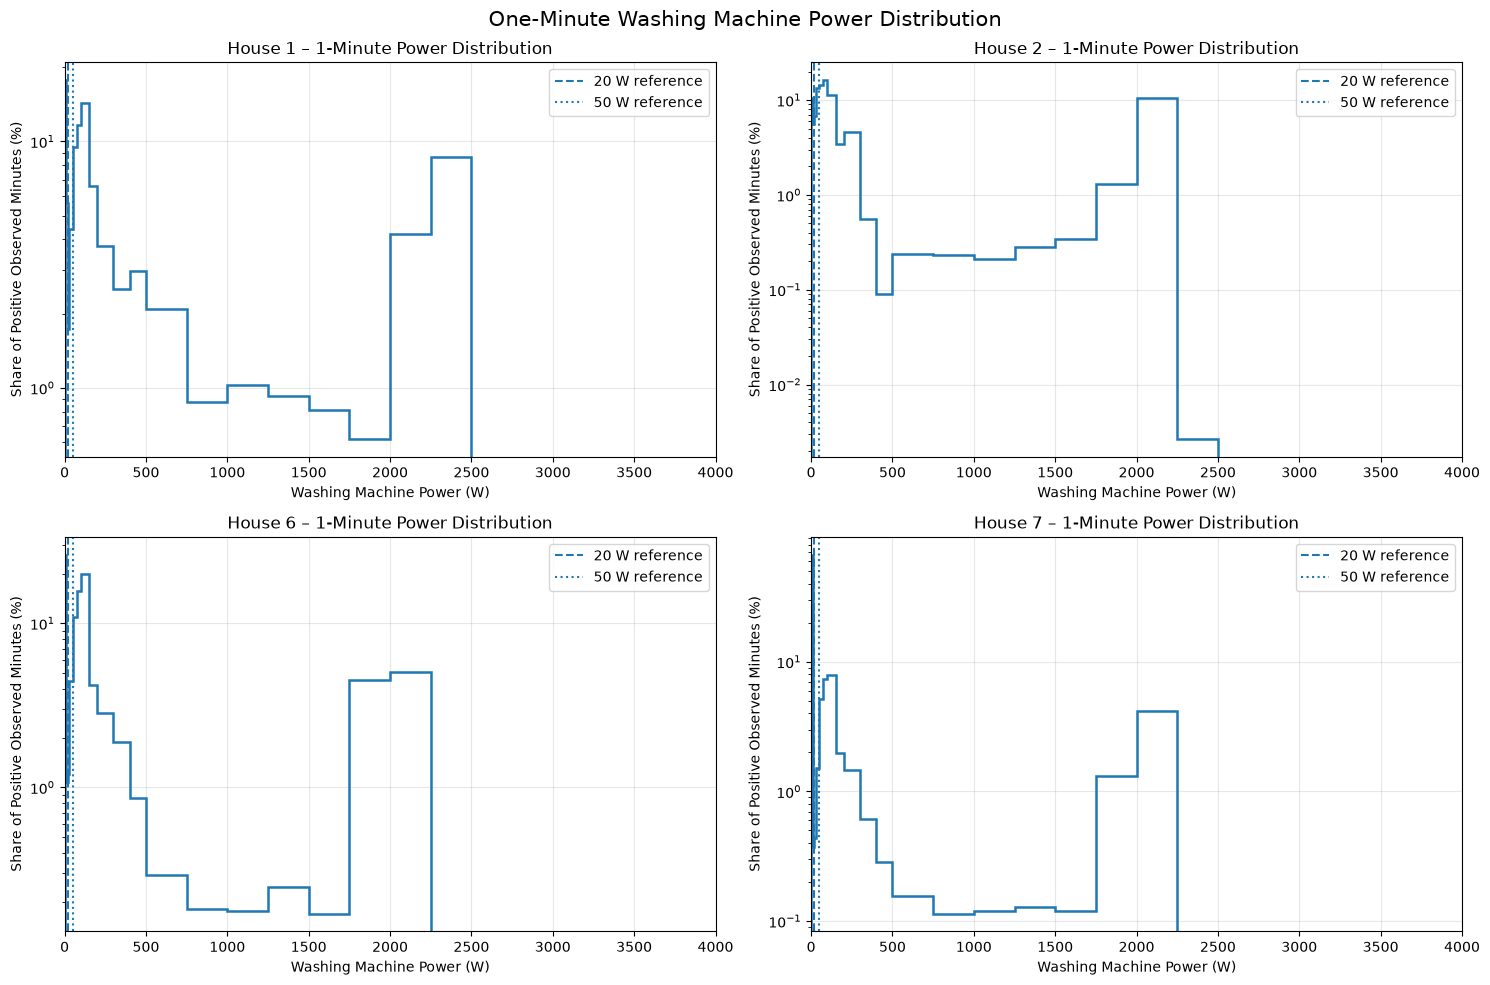

Figure saved successfully.


In [45]:
# Output directory
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

POWER_BINS = [
    0, 10, 20, 30, 50, 75, 100, 150,
    200, 300, 400, 500, 750, 1000,
    1250, 1500, 1750, 2000, 2250,
    2500, 2750, 3000, 3250, 3500,
    3750, 4000
]

# Create figure
hist_fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 10)
)

axes = axes.flatten()

for ax, house in zip(axes, PRIMARY_HOUSES):

    counts = minute_power_distributions[house]

    powers = counts.index.to_numpy()

    frequencies = counts.to_numpy()

    # Percentage of positive-power minutes
    weights = (
        frequencies / frequencies.sum() * 100
    )

    ax.hist(
        powers,
        bins=POWER_BINS,
        weights=weights,
        histtype="step",
        linewidth=1.8
    )

    ax.axvline(
        20,
        linestyle="--",
        label="20 W reference"
    )

    ax.axvline(
        50,
        linestyle=":",
        label="50 W reference"
    )

    ax.set_yscale("log")

    ax.set_xlim(0, 4000)

    ax.set_title(
        f"House {house} – 1-Minute Power Distribution"
    )

    ax.set_xlabel("Washing Machine Power (W)")

    ax.set_ylabel(
        "Share of Positive Observed Minutes (%)"
    )

    ax.grid(alpha=0.3)

    ax.legend()

hist_fig.suptitle(
    "One-Minute Washing Machine Power Distribution",
    fontsize=15
)

hist_fig.tight_layout()

hist_fig.savefig(
    FIGURE_DIR / "wm_power_distribution_1min.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved successfully.")

### Plot 2 — One-Minute ECDF

**Cell purpose:** Plot the one-minute ECDF to compare the cumulative positive-power distributions across households.

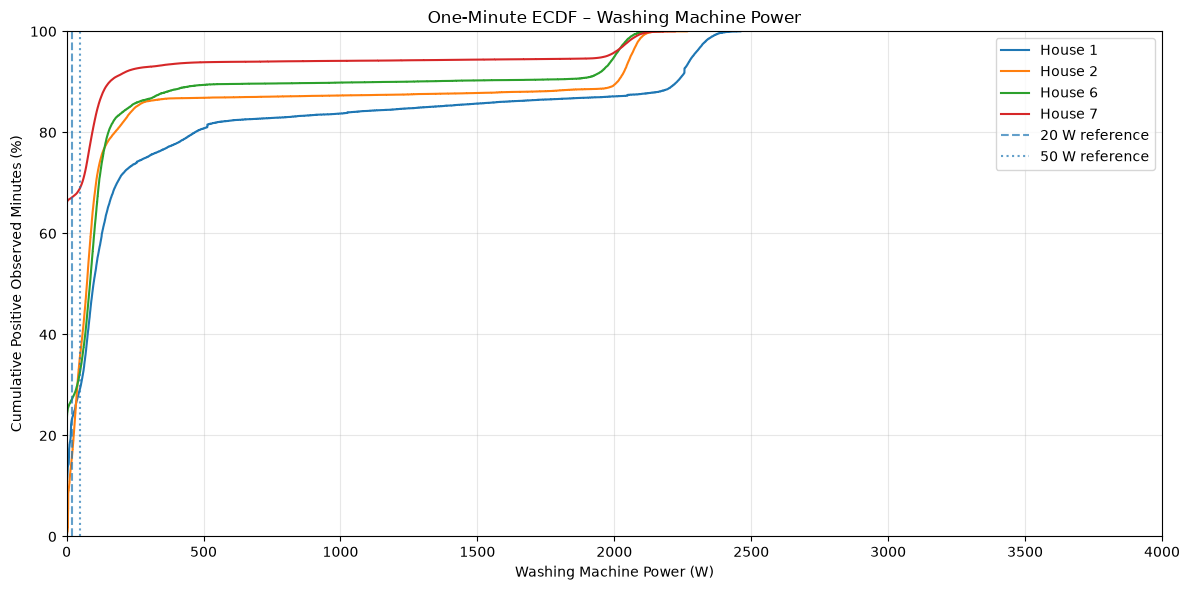

In [46]:
ecdf_fig, ax = plt.subplots(
    figsize=(12, 6)
)

for house in PRIMARY_HOUSES:

    counts = minute_power_distributions[house]

    powers = counts.index.to_numpy()

    frequencies = counts.to_numpy()

    cumulative = (
        np.cumsum(frequencies)
        / frequencies.sum() * 100
    )

    ax.step(
        powers,
        cumulative,
        where="post",
        label=f"House {house}"
    )

ax.axvline(
    20,
    linestyle="--",
    alpha=0.7,
    label="20 W reference"
)

ax.axvline(
    50,
    linestyle=":",
    alpha=0.7,
    label="50 W reference"
)

ax.set_xlabel(
    "Washing Machine Power (W)"
)

ax.set_ylabel(
    "Cumulative Positive Observed Minutes (%)"
)

ax.set_title(
    "One-Minute ECDF – Washing Machine Power"
)

ax.set_xlim(0, 4000)

ax.set_ylim(0, 100)

ax.grid(alpha=0.3)

ax.legend()

ecdf_fig.tight_layout()

ecdf_fig.savefig(
    FIGURE_DIR / "wm_power_ecdf_1min.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Plot 3 — Low-Power ECDF Detail

**Cell purpose:** Zoom into the low-power ECDF region to inspect readings around the candidate activation thresholds.

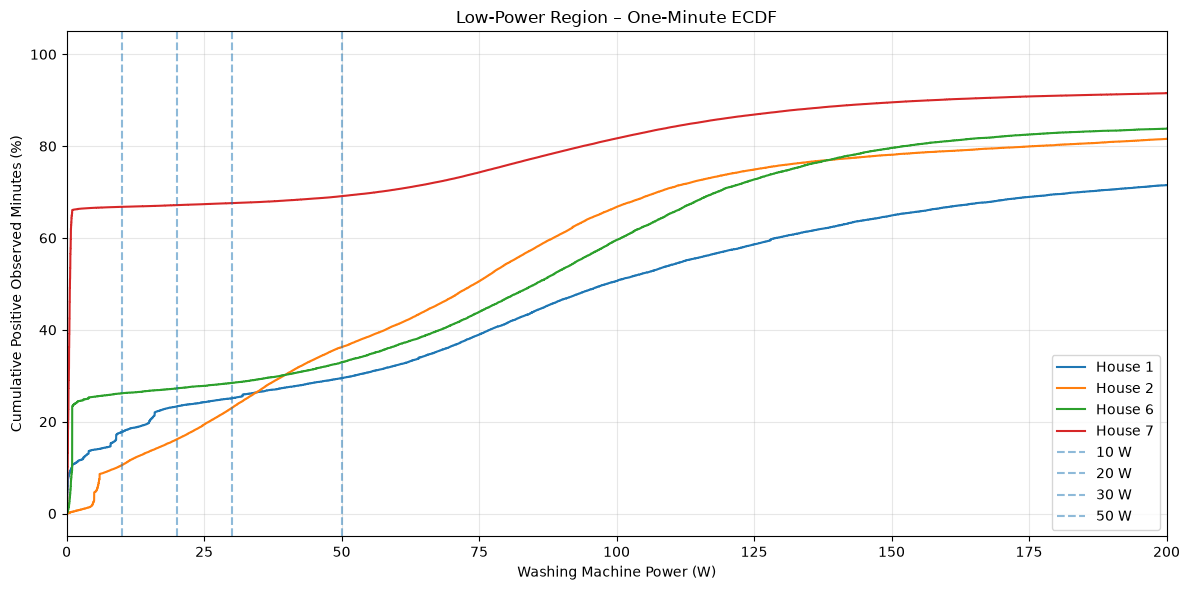

In [47]:
zoom_fig, ax = plt.subplots(
    figsize=(12, 6)
)

for house in PRIMARY_HOUSES:

    counts = minute_power_distributions[house]

    powers = counts.index.to_numpy()

    frequencies = counts.to_numpy()

    cumulative = (
        np.cumsum(frequencies)
        / frequencies.sum() * 100
    )

    ax.step(
        powers,
        cumulative,
        where="post",
        label=f"House {house}"
    )

for threshold in [10, 20, 30, 50]:

    ax.axvline(
        threshold,
        linestyle="--",
        alpha=0.5,
        label=f"{threshold} W"
    )

ax.set_xlim(0, 200)

ax.set_xlabel("Washing Machine Power (W)")

ax.set_ylabel("Cumulative Positive Observed Minutes (%)")

ax.set_title(
    "Low-Power Region – One-Minute ECDF"
)

ax.grid(alpha=0.3)

ax.legend()

zoom_fig.tight_layout()

zoom_fig.savefig(
    FIGURE_DIR / "wm_low_power_ecdf_1min.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Step 11 — Detect Washing-Machine Activation Episodes


### Initial Activation-Detection Experiments


### Activation-Detection Methodology Overview


### Activation Detection Methodology

An activation episode is identified using a power threshold.

1. A minute is considered active when washing-machine power
   exceeds the selected threshold.
2. Short, observed OFF intervals can be merged when they are
   within the selected gap tolerance.
3. Missing or insufficiently observed minutes break an episode.
4. Episodes shorter than the selected minimum duration are
   discarded.

The initial experiment uses a 5-minute OFF-gap tolerance
and a 27-minute minimum episode duration.

Multiple ON thresholds are tested before selecting the
final configuration.

**Cell purpose:** Define the activation detector using the power threshold, short OFF-gap merging rule and minimum episode duration.

In [48]:
def detect_wm_episodes(
    df,
    threshold_w=20,
    gap_tolerance_min=5,
    min_duration_min=27
):

    # Original one-minute washing-machine readings
    power = df["Washing_Machine_W"].to_numpy(dtype=float)

    # Only complete minutes are valid
    valid = (
        df["observed_seconds"].to_numpy() == 60
    ) & np.isfinite(power)

    # Three possible states:
    #  1 = ON
    #  0 = observed OFF
    # -1 = unavailable / invalid

    state = np.full(len(power), -1, dtype=np.int8)

    state[valid] = (
        power[valid] > threshold_w
    ).astype(np.int8)

    # Identify consecutive runs of identical states
    changes = np.flatnonzero(
        state[1:] != state[:-1]
    ) + 1

    starts = np.r_[0, changes]
    ends = np.r_[changes, len(state)]

    run_states = state[starts]
    run_lengths = ends - starts

    # Initially, only actual ON minutes are active
    merged_active = state == 1

    # Merge short observed OFF gaps bounded by ON periods
    for i in range(1, len(run_states) - 1):

        if (
            run_states[i] == 0
            and run_states[i - 1] == 1
            and run_states[i + 1] == 1
            and run_lengths[i] <= gap_tolerance_min
        ):

            merged_active[starts[i]:ends[i]] = True

    # Identify resulting activation episodes
    episode_starts = np.flatnonzero(
        merged_active
        & np.r_[True, ~merged_active[:-1]]
    )

    episode_ends = (
        np.flatnonzero(
            merged_active
            & np.r_[~merged_active[1:], True]
        ) + 1
    )

    records = []

    timestamps = df.index

    issues_pct = df["Issues_Time_Pct"].to_numpy()

    for start, end in zip(
        episode_starts,
        episode_ends
    ):

        duration = end - start

        # Apply minimum episode duration
        if duration < min_duration_min:
            continue

        episode_power = power[start:end]

        # Original active observations, excluding merged OFF gaps
        active_mask = (
            state[start:end] == 1
        )

        active_power = episode_power[active_mask]

        active_minutes = int(active_mask.sum())

        if active_minutes == 0:
            continue

        # Energy across the complete episode
        episode_energy_wh = (
            episode_power.sum() / 60
        )

        # Energy during actual threshold-active minutes
        active_energy_wh = (
            active_power.sum() / 60
        )

        episode_issues = issues_pct[start:end]

        records.append({

            "Cycle_ID": len(records) + 1,

            "Start_UTC": timestamps[start],

            "End_UTC": (
                timestamps[end - 1]
                + pd.Timedelta(minutes=1)
            ),

            "Duration_Min": duration,

            "Active_Minutes": active_minutes,

            "Bridged_OFF_Minutes": (
                duration - active_minutes
            ),

            "Mean_Active_Power_W": (
                active_power.mean()
            ),

            "Peak_Power_W": (
                active_power.max()
            ),

            "Energy_Wh": episode_energy_wh,

            "Active_Energy_Wh": active_energy_wh,

            "Issues_Minutes_Pct": (
                np.mean(episode_issues > 0) * 100
            ),

            "Issues_Time_Pct": (
                np.mean(episode_issues)
            )

        })

    return pd.DataFrame(records)

**Cell purpose:** Run the detector at 10, 20, 30 and 50 W while keeping the gap and minimum-duration settings fixed.

In [49]:
THRESHOLDS = [10, 20, 30, 50]

BASELINE_GAP_MIN = 5
BASELINE_DURATION_MIN = 27

threshold_experiment_results = []

threshold_episode_store = {}

for house in PRIMARY_HOUSES:

    print(f"\nProcessing House {house}...")

    df = pd.read_parquet(
        resampled_paths[house],
        columns=[
            "observed_seconds",
            "Washing_Machine_W",
            "Issues_Time_Pct"
        ]
    )

    for threshold in THRESHOLDS:

        episodes = detect_wm_episodes(
            df=df,
            threshold_w=threshold,
            gap_tolerance_min=BASELINE_GAP_MIN,
            min_duration_min=BASELINE_DURATION_MIN
        )

        threshold_episode_store[
            (house, threshold)
        ] = episodes

        result = {

            "House": house,

            "Threshold_W": threshold,

            "Gap_Tolerance_Min": BASELINE_GAP_MIN,

            "Minimum_Duration_Min": BASELINE_DURATION_MIN,

            "Detected_Episodes": len(episodes)
        }

        if not episodes.empty:

            result.update({

                "Median_Duration_Min": (
                    episodes["Duration_Min"].median()
                ),

                "Median_Active_Minutes": (
                    episodes["Active_Minutes"].median()
                ),

                "Median_Peak_Power_W": (
                    episodes["Peak_Power_W"].median()
                ),

                "Median_Energy_Wh": (
                    episodes["Energy_Wh"].median()
                ),

                "Issues_Affected_Episodes_Pct": (
                    (episodes["Issues_Minutes_Pct"] > 0)
                    .mean() * 100
                )
            })

        else:

            result.update({

                "Median_Duration_Min": np.nan,

                "Median_Active_Minutes": np.nan,

                "Median_Peak_Power_W": np.nan,

                "Median_Energy_Wh": np.nan,

                "Issues_Affected_Episodes_Pct": np.nan
            })

        threshold_experiment_results.append(result)

    del df

    print(f"House {house} completed.")


threshold_experiment_summary = pd.DataFrame(
    threshold_experiment_results
)

display(
    threshold_experiment_summary.round(2)
)


Processing House 1...
House 1 completed.

Processing House 2...
House 2 completed.

Processing House 6...
House 6 completed.

Processing House 7...
House 7 completed.


,House,Threshold_W,Gap_Tolerance_Min,Minimum_Duration_Min,Detected_Episodes,Median_Duration_Min,Median_Active_Minutes,Median_Peak_Power_W,Median_Energy_Wh,Issues_Affected_Episodes_Pct
0,1,10,5,27,398,34.0,33.0,2319.86,312.61,98.99
1,1,20,5,27,395,33.0,31.0,2321.87,312.79,98.99
2,1,30,5,27,392,33.0,30.0,2322.43,312.61,99.23
3,1,50,5,27,396,33.0,29.0,2322.14,312.45,99.24
4,2,10,5,27,336,99.0,98.0,2089.19,608.72,97.62
5,2,20,5,27,338,96.0,91.5,2088.90,607.21,96.75
6,2,30,5,27,340,94.0,84.0,2088.90,603.86,96.18
7,2,50,5,27,377,81.0,63.0,2083.88,561.84,93.63
8,6,10,5,27,123,128.0,128.0,2049.18,670.60,97.56
9,6,20,5,27,121,129.0,128.0,2049.18,674.99,97.52


Calculate a better threshold comparison summary

**Cell purpose:** Summarize threshold-test episode counts relative to each household's monitored exposure.

In [50]:
threshold_diagnostics = []

for house in PRIMARY_HOUSES:

    # Calculate valid monitored days
    quality_df = pd.read_parquet(
        resampled_paths[house],
        columns=["observed_seconds"]
    )

    valid_minutes = (
        quality_df["observed_seconds"] == 60
    ).sum()

    valid_days = valid_minutes / 1440

    del quality_df

    for threshold in THRESHOLDS:

        episodes = threshold_episode_store[
            (house, threshold)
        ]

        if episodes.empty:
            continue

        issue_pct = episodes["Issues_Minutes_Pct"]

        threshold_diagnostics.append({

            "House": house,

            "Threshold_W": threshold,

            "Valid_Monitoring_Days": valid_days,

            "Detected_Episodes": len(episodes),

            "Episodes_Per_30_Days": (
                len(episodes) / valid_days * 30
            ),

            "Median_Duration_Min": (
                episodes["Duration_Min"].median()
            ),

            "Mean_Duration_Min": (
                episodes["Duration_Min"].mean()
            ),

            "Median_Energy_Wh": (
                episodes["Energy_Wh"].median()
            ),

            "Episodes_With_Issues_Pct": (
                issue_pct.gt(0).mean() * 100
            ),

            "Mean_Episode_Minutes_With_Issues_Pct": (
                issue_pct.mean()
            ),

            "Median_Episode_Minutes_With_Issues_Pct": (
                issue_pct.median()
            ),

            "Issues_Free_Episodes_Pct": (
                issue_pct.eq(0).mean() * 100
            )

        })


threshold_diagnostics_df = pd.DataFrame(
    threshold_diagnostics
)

display(
    threshold_diagnostics_df.round(2)
)

,House,Threshold_W,Valid_Monitoring_Days,Detected_Episodes,Episodes_Per_30_Days,Median_Duration_Min,Mean_Duration_Min,Median_Energy_Wh,Episodes_With_Issues_Pct,Mean_Episode_Minutes_With_Issues_Pct,Median_Episode_Minutes_With_Issues_Pct,Issues_Free_Episodes_Pct
0,1,10,557.53,398,21.42,34.0,41.20,312.61,98.99,31.29,30.30,1.01
1,1,20,557.53,395,21.25,33.0,40.45,312.79,98.99,31.65,31.25,1.01
2,1,30,557.53,392,21.09,33.0,40.15,312.61,99.23,31.90,31.25,0.77
3,1,50,557.53,396,21.31,33.0,39.05,312.45,99.24,32.11,31.25,0.76
4,2,10,464.73,336,21.69,99.0,100.45,608.72,97.62,17.19,15.62,2.38
5,2,20,464.73,338,21.82,96.0,97.60,607.21,96.75,17.40,16.05,3.25
6,2,30,464.73,340,21.95,94.0,93.57,603.86,96.18,17.93,16.67,3.82
7,2,50,464.73,377,24.34,81.0,73.72,561.84,93.63,18.56,17.24,6.37
8,6,10,489.65,123,7.54,128.0,104.93,670.60,97.56,11.07,9.38,2.44
9,6,20,489.65,121,7.41,129.0,105.71,674.99,97.52,11.08,9.33,2.48


Next experiment – OFF-gap tolerance

**Cell purpose:** Vary the allowed OFF-gap duration to measure how merging short gaps changes detected episode counts.

In [51]:
GAP_VALUES = [3, 5, 10, 15]

gap_experiment_results = []

gap_episode_store = {}

for house in PRIMARY_HOUSES:

    print(f"Processing House {house}...")

    df = pd.read_parquet(
        resampled_paths[house],
        columns=[
            "observed_seconds",
            "Washing_Machine_W",
            "Issues_Time_Pct"
        ]
    )

    for gap in GAP_VALUES:

        episodes = detect_wm_episodes(
            df=df,
            threshold_w=20,
            gap_tolerance_min=gap,
            min_duration_min=27
        )

        gap_episode_store[
            (house, gap)
        ] = episodes

        result = {

            "House": house,

            "Threshold_W": 20,

            "Gap_Tolerance_Min": gap,

            "Minimum_Duration_Min": 27,

            "Detected_Episodes": len(episodes)
        }

        if not episodes.empty:

            result.update({

                "Median_Duration_Min": (
                    episodes["Duration_Min"].median()
                ),

                "Median_Active_Minutes": (
                    episodes["Active_Minutes"].median()
                ),

                "Median_Peak_Power_W": (
                    episodes["Peak_Power_W"].median()
                ),

                "Median_Energy_Wh": (
                    episodes["Energy_Wh"].median()
                )

            })

        else:

            result.update({

                "Median_Duration_Min": np.nan,

                "Median_Active_Minutes": np.nan,

                "Median_Peak_Power_W": np.nan,

                "Median_Energy_Wh": np.nan

            })

        gap_experiment_results.append(result)

    del df

    print(f"House {house} completed.")


gap_experiment_summary = pd.DataFrame(
    gap_experiment_results
)

display(
    gap_experiment_summary.round(2)
)

Processing House 1...
House 1 completed.
Processing House 2...
House 2 completed.
Processing House 6...
House 6 completed.
Processing House 7...
House 7 completed.


,House,Threshold_W,Gap_Tolerance_Min,Minimum_Duration_Min,Detected_Episodes,Median_Duration_Min,Median_Active_Minutes,Median_Peak_Power_W,Median_Energy_Wh
0,1,20,3,27,409,33.0,30.0,2319.02,304.49
1,1,20,5,27,395,33.0,31.0,2321.87,312.79
2,1,20,10,27,374,33.0,31.0,2323.59,323.56
3,1,20,15,27,364,33.0,31.0,2324.09,324.44
4,2,20,3,27,340,96.0,91.0,2088.27,606.74
5,2,20,5,27,338,96.0,91.5,2088.90,607.21
6,2,20,10,27,330,97.0,92.0,2089.57,612.07
7,2,20,15,27,320,97.0,92.0,2089.96,622.95
8,6,20,3,27,122,129.0,128.5,2049.01,677.18
9,6,20,5,27,121,129.0,128.0,2049.18,674.99


**Cell purpose:** Vary the minimum episode duration to measure how the episode filter changes the detected counts.

In [52]:
MIN_DURATION_VALUES = [10, 20, 27, 30]

duration_experiment_results = []

duration_episode_store = {}

for house in PRIMARY_HOUSES:

    print(f"\nProcessing House {house}...")

    df = pd.read_parquet(
        resampled_paths[house],
        columns=[
            "observed_seconds",
            "Washing_Machine_W",
            "Issues_Time_Pct"
        ]
    )

    # Valid monitoring days
    valid_minutes = (
        df["observed_seconds"] == 60
    ).sum()

    valid_days = valid_minutes / 1440

    for min_duration in MIN_DURATION_VALUES:

        episodes = detect_wm_episodes(
            df=df,
            threshold_w=20,
            gap_tolerance_min=5,
            min_duration_min=min_duration
        )

        duration_episode_store[
            (house, min_duration)
        ] = episodes

        result = {

            "House": house,

            "Threshold_W": 20,

            "Gap_Tolerance_Min": 5,

            "Minimum_Duration_Min": min_duration,

            "Detected_Episodes": len(episodes),

            "Episodes_Per_30_Days": (
                len(episodes) / valid_days * 30
            )
        }

        if not episodes.empty:

            result.update({

                "Median_Duration_Min": (
                    episodes["Duration_Min"].median()
                ),

                "Mean_Duration_Min": (
                    episodes["Duration_Min"].mean()
                ),

                "Median_Active_Minutes": (
                    episodes["Active_Minutes"].median()
                ),

                "Median_Peak_Power_W": (
                    episodes["Peak_Power_W"].median()
                ),

                "Median_Energy_Wh": (
                    episodes["Energy_Wh"].median()
                ),

                "Episodes_With_Issues_Pct": (
                    episodes["Issues_Minutes_Pct"]
                    .gt(0).mean() * 100
                )
            })

        else:

            result.update({

                "Median_Duration_Min": np.nan,

                "Mean_Duration_Min": np.nan,

                "Median_Active_Minutes": np.nan,

                "Median_Peak_Power_W": np.nan,

                "Median_Energy_Wh": np.nan,

                "Episodes_With_Issues_Pct": np.nan
            })

        duration_experiment_results.append(result)

    del df

    print(f"House {house} completed.")


duration_experiment_summary = pd.DataFrame(
    duration_experiment_results
)

display(
    duration_experiment_summary.round(2)
)


Processing House 1...
House 1 completed.

Processing House 2...
House 2 completed.

Processing House 6...
House 6 completed.

Processing House 7...
House 7 completed.


,House,Threshold_W,Gap_Tolerance_Min,Minimum_Duration_Min,Detected_Episodes,Episodes_Per_30_Days,Median_Duration_Min,Mean_Duration_Min,Median_Active_Minutes,Median_Peak_Power_W,Median_Energy_Wh,Episodes_With_Issues_Pct
0,1,20,5,10,436,23.46,33.0,38.12,30.0,2314.34,302.12,96.10
1,1,20,5,20,408,21.95,33.0,39.88,30.0,2317.56,310.08,98.53
2,1,20,5,27,395,21.25,33.0,40.45,31.0,2321.87,312.79,98.99
3,1,20,5,30,390,20.99,33.0,40.61,31.0,2322.14,313.42,99.23
4,2,20,5,10,352,22.72,96.0,94.47,90.0,2087.82,602.05,95.45
5,2,20,5,20,343,22.14,96.0,96.52,91.0,2088.60,606.48,96.50
6,2,20,5,27,338,21.82,96.0,97.60,91.5,2088.90,607.21,96.75
7,2,20,5,30,337,21.75,96.0,97.81,92.0,2089.03,607.21,96.74
8,6,20,5,10,145,8.88,89.0,90.96,87.0,2044.75,618.06,91.72
9,6,20,5,20,125,7.66,127.0,103.07,126.0,2049.23,666.28,96.80


## Step 12 — Validate Detected Episodes and Review Outliers

### Select and Visually Validate Representative Episodes


Select representative episodes

**Cell purpose:** Select representative detected episodes, including typical and relatively low-Issues examples, for visual validation.

In [53]:
representative_events = []

for house in PRIMARY_HOUSES:

    episodes = duration_episode_store[
        (house, 27)
    ].copy()

    if episodes.empty:
        print(f"No episodes found for House {house}")
        continue

    # 1. Typical episode: closest to median duration
    median_duration = episodes["Duration_Min"].median()

    typical_idx = (
        episodes["Duration_Min"] - median_duration
    ).abs().idxmin()

    # 2. Lowest Issues percentage
    clean_idx = (
        episodes["Issues_Minutes_Pct"].idxmin()
    )

    # 3. Highest Issues percentage
    suspicious_idx = (
        episodes["Issues_Minutes_Pct"].idxmax()
    )

    selected = {
        "Typical": typical_idx,
        "Lowest_Issues": clean_idx,
        "Highest_Issues": suspicious_idx
    }

    seen = set()

    for event_type, idx in selected.items():

        if idx in seen:
            continue

        seen.add(idx)

        row = episodes.loc[idx].copy()

        representative_events.append({

            "House": house,

            "Validation_Type": event_type,

            "Cycle_ID": row["Cycle_ID"],

            "Start_UTC": row["Start_UTC"],

            "End_UTC": row["End_UTC"],

            "Duration_Min": row["Duration_Min"],

            "Active_Minutes": row["Active_Minutes"],

            "Peak_Power_W": row["Peak_Power_W"],

            "Energy_Wh": row["Energy_Wh"],

            "Issues_Minutes_Pct": (
                row["Issues_Minutes_Pct"]
            )
        })


representative_event_df = pd.DataFrame(
    representative_events
)

display(
    representative_event_df.round(2)
)

/var/folders/4y/wyg1yj8s6171ybbm1q81x0m00000gn/T/ipykernel_3174/2140273799.py:78: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  representative_event_df.round(2)


,House,Validation_Type,Cycle_ID,Start_UTC,End_UTC,Duration_Min,Active_Minutes,Peak_Power_W,Energy_Wh,Issues_Minutes_Pct
0,1,Typical,12,2013-10-30 14:54:00+00:00,2013-10-30 15:27:00+00:00,33,30,2305.87,332.88,75.76
1,1,Lowest_Issues,47,2013-12-17 11:35:00+00:00,2013-12-17 12:03:00+00:00,28,18,486.00,57.32,0.00
2,1,Highest_Issues,29,2013-11-26 06:17:00+00:00,2013-11-26 06:50:00+00:00,33,29,2280.75,320.12,100.00
3,2,Typical,123,2014-07-15 08:10:00+00:00,2014-07-15 09:46:00+00:00,96,92,2065.83,311.55,39.58
4,2,Lowest_Issues,70,2014-05-03 20:40:00+00:00,2014-05-03 21:18:00+00:00,38,27,55.07,15.48,0.00
5,2,Highest_Issues,22,2014-02-24 13:59:00+00:00,2014-02-24 14:30:00+00:00,31,31,118.62,47.79,58.06
6,6,Typical,82,2014-12-14 11:19:00+00:00,2014-12-14 13:28:00+00:00,129,128,2043.63,865.49,5.43
7,6,Lowest_Issues,54,2014-08-07 11:10:00+00:00,2014-08-07 12:16:00+00:00,66,66,1984.57,407.54,0.00
8,6,Highest_Issues,32,2014-04-24 12:47:00+00:00,2014-04-24 15:01:00+00:00,134,134,2142.25,1127.29,35.82
9,7,Typical,8,2013-11-07 08:30:00+00:00,2013-11-07 09:30:00+00:00,60,60,2085.20,574.31,43.33


### Define the Episode-Validation Plot

**Cell purpose:** Define a plotting function that displays a selected activation episode with surrounding context from the raw one-minute trace.

In [54]:
import matplotlib.pyplot as plt

def plot_detected_episode(
    house,
    cycle_id,
    validation_type,
    padding_minutes=30
):

    episodes = duration_episode_store[
        (house, 27)
    ]

    event = episodes[
        episodes["Cycle_ID"] == cycle_id
    ].iloc[0]

    df = pd.read_parquet(
        resampled_paths[house],
        columns=[
            "observed_seconds",
            "Aggregate_W",
            "Washing_Machine_W",
            "Issues_Time_Pct"
        ]
    )

    start = event["Start_UTC"]
    end = event["End_UTC"]

    window_start = (
        start - pd.Timedelta(minutes=padding_minutes)
    )

    window_end = (
        end + pd.Timedelta(minutes=padding_minutes)
    )

    plot_data = df.loc[
        window_start:window_end
    ].copy()

    # Convert plotting timestamps to UK local time
    local_time = plot_data.index.tz_convert(
        "Europe/London"
    )

    fig, axes = plt.subplots(
        2, 1,
        figsize=(15, 8),
        sharex=True
    )

    local_start = start.tz_convert("Europe/London")
    local_end = end.tz_convert("Europe/London")

    # Aggregate plot
    axes[0].plot(
        local_time,
        plot_data["Aggregate_W"],
        label="Aggregate Power"
    )

    axes[0].axvspan(
        local_start,
        local_end,
        alpha=0.15,
        label="Detected episode"
    )

    axes[0].set_title(
        f"House {house} – Aggregate Power"
    )

    axes[0].set_ylabel("Power (W)")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Washing machine plot
    axes[1].plot(
        local_time,
        plot_data["Washing_Machine_W"],
        label="Washing Machine Power"
    )

    axes[1].axhline(
        20,
        linestyle="--",
        label="ON threshold: 20 W"
    )

    axes[1].axvspan(
        local_start,
        local_end,
        alpha=0.15,
        label="Detected episode"
    )

    # Mark Issues-affected minutes
    issue_mask = (
        plot_data["Issues_Time_Pct"] > 0
    )

    axes[1].scatter(
        local_time[issue_mask],
        plot_data.loc[
            issue_mask,
            "Washing_Machine_W"
        ],
        s=8,
        label="Issues-flagged minutes"
    )

    axes[1].set_title(
        f"House {house} – Washing Machine Power"
    )

    axes[1].set_xlabel(
        "Time (Europe/London)"
    )

    axes[1].set_ylabel("Power (W)")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    fig.suptitle(
        f"House {house} | Cycle {cycle_id} | "
        f"{validation_type} | "
        f"Duration: {event['Duration_Min']:.0f} min | "
        f"Peak: {event['Peak_Power_W']:.0f} W"
    )

    fig.tight_layout()

    plt.show()

**Cell purpose:** Generate the representative episode plots selected for the visual validation exercise.


House 1 | Typical


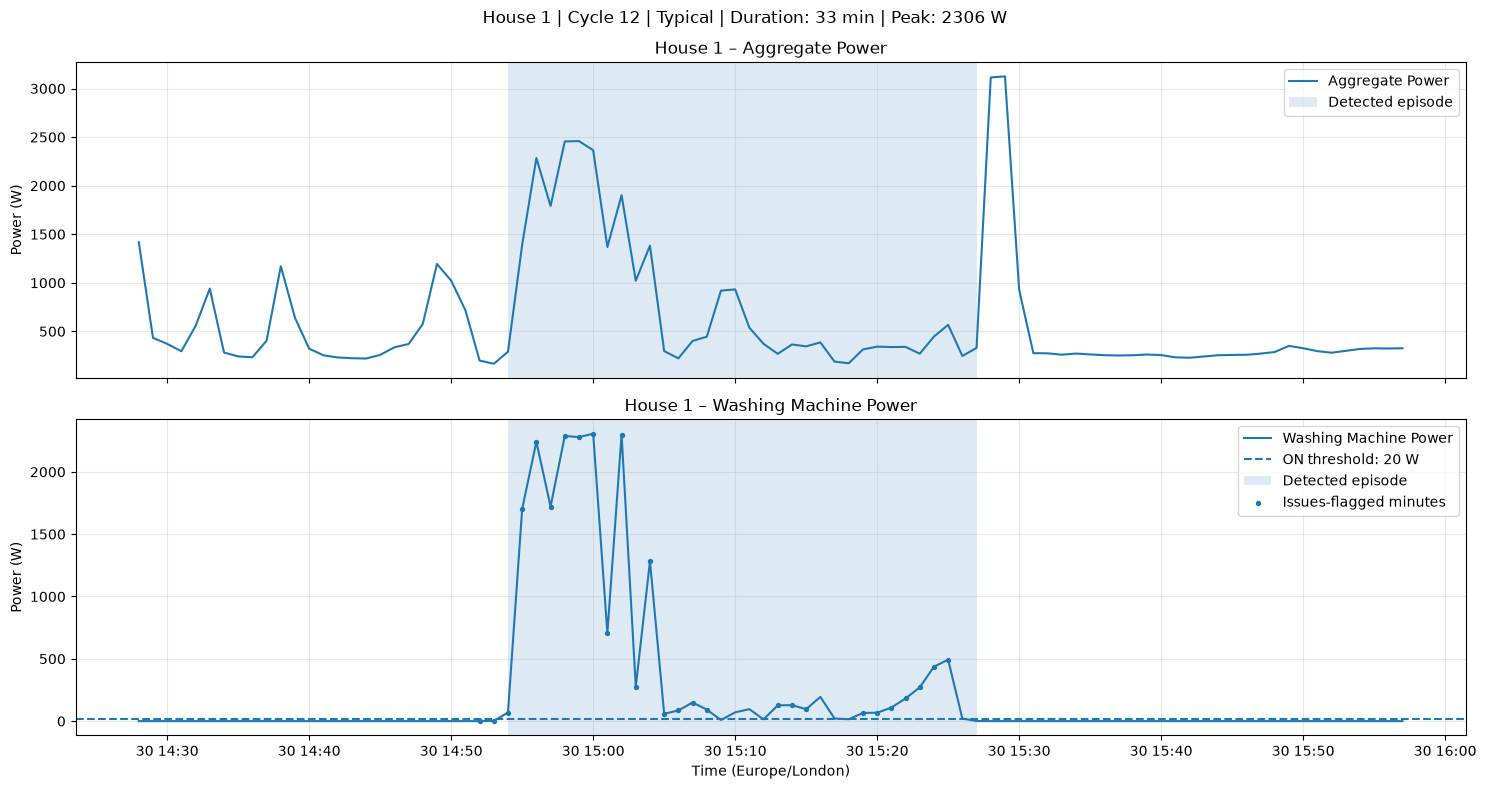


House 1 | Lowest_Issues


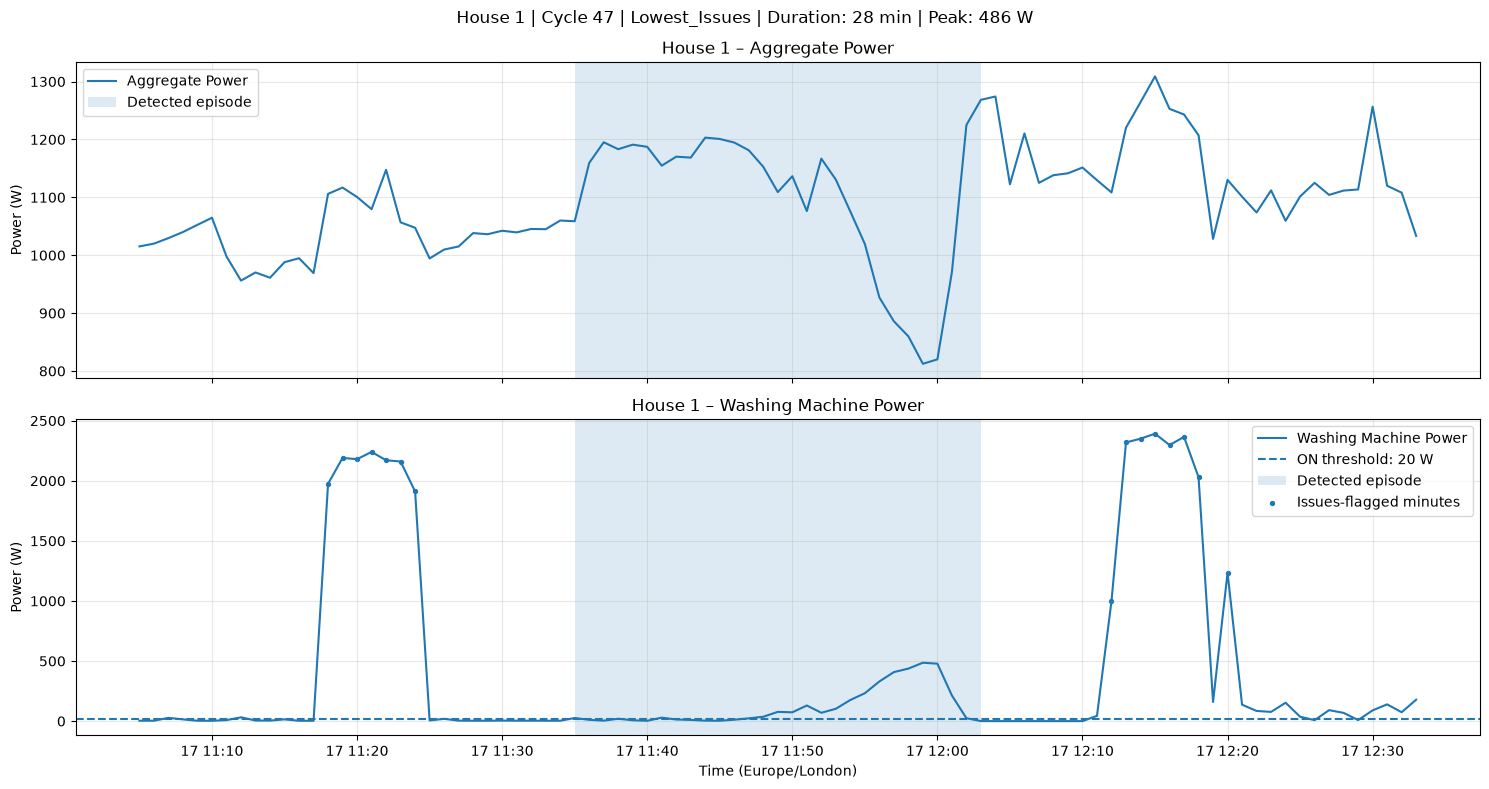


House 1 | Highest_Issues


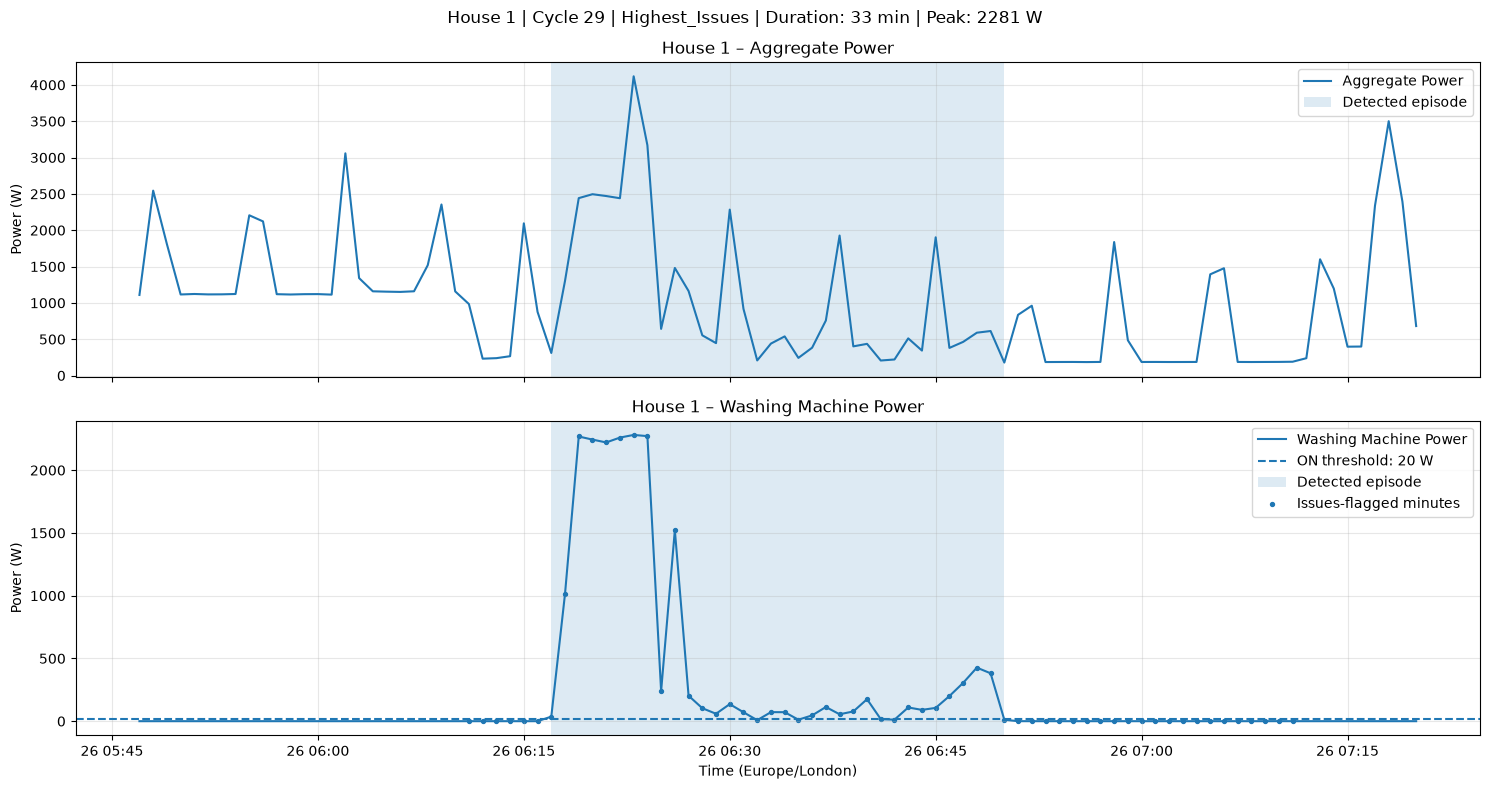


House 2 | Typical


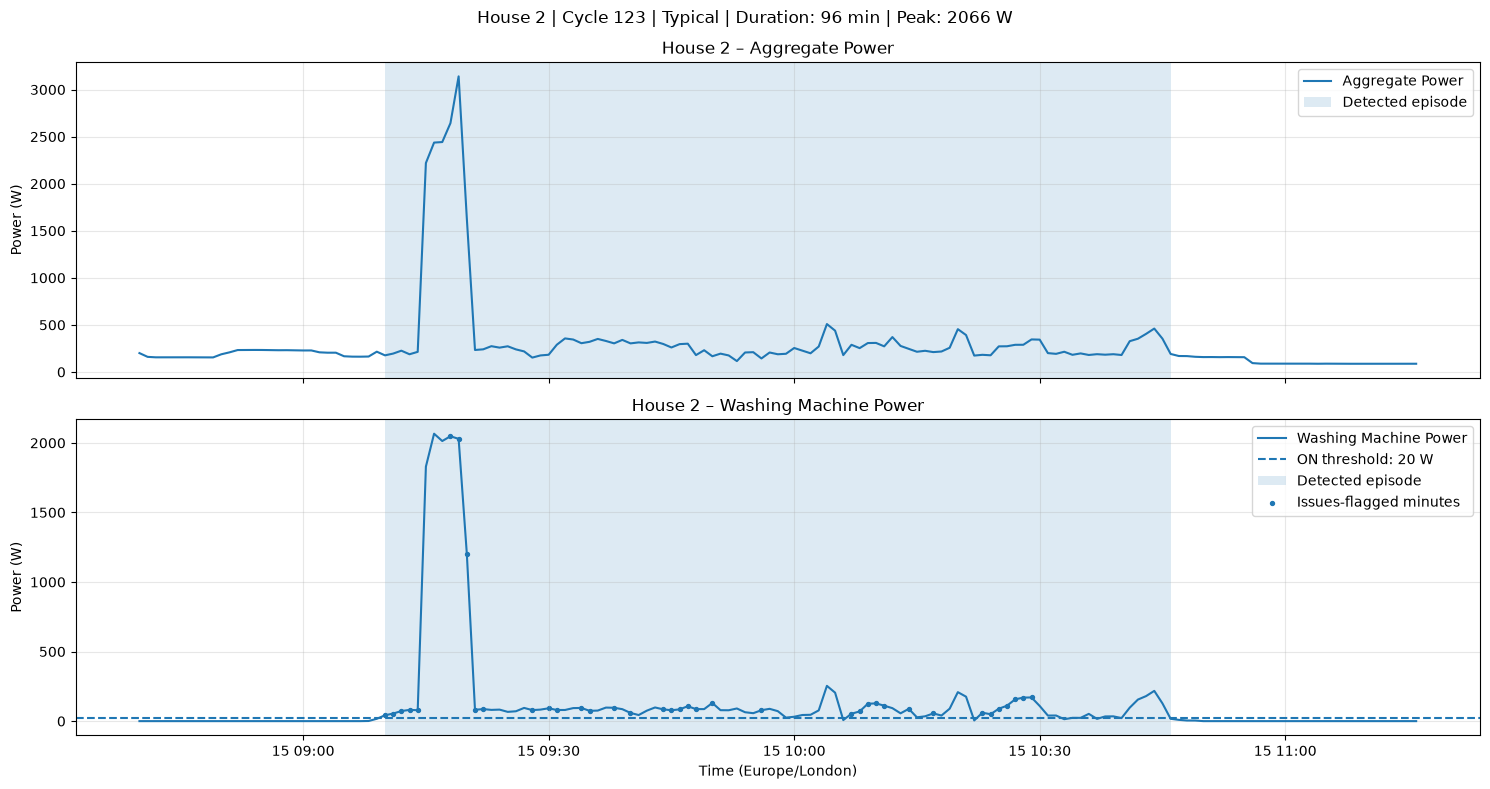


House 2 | Lowest_Issues


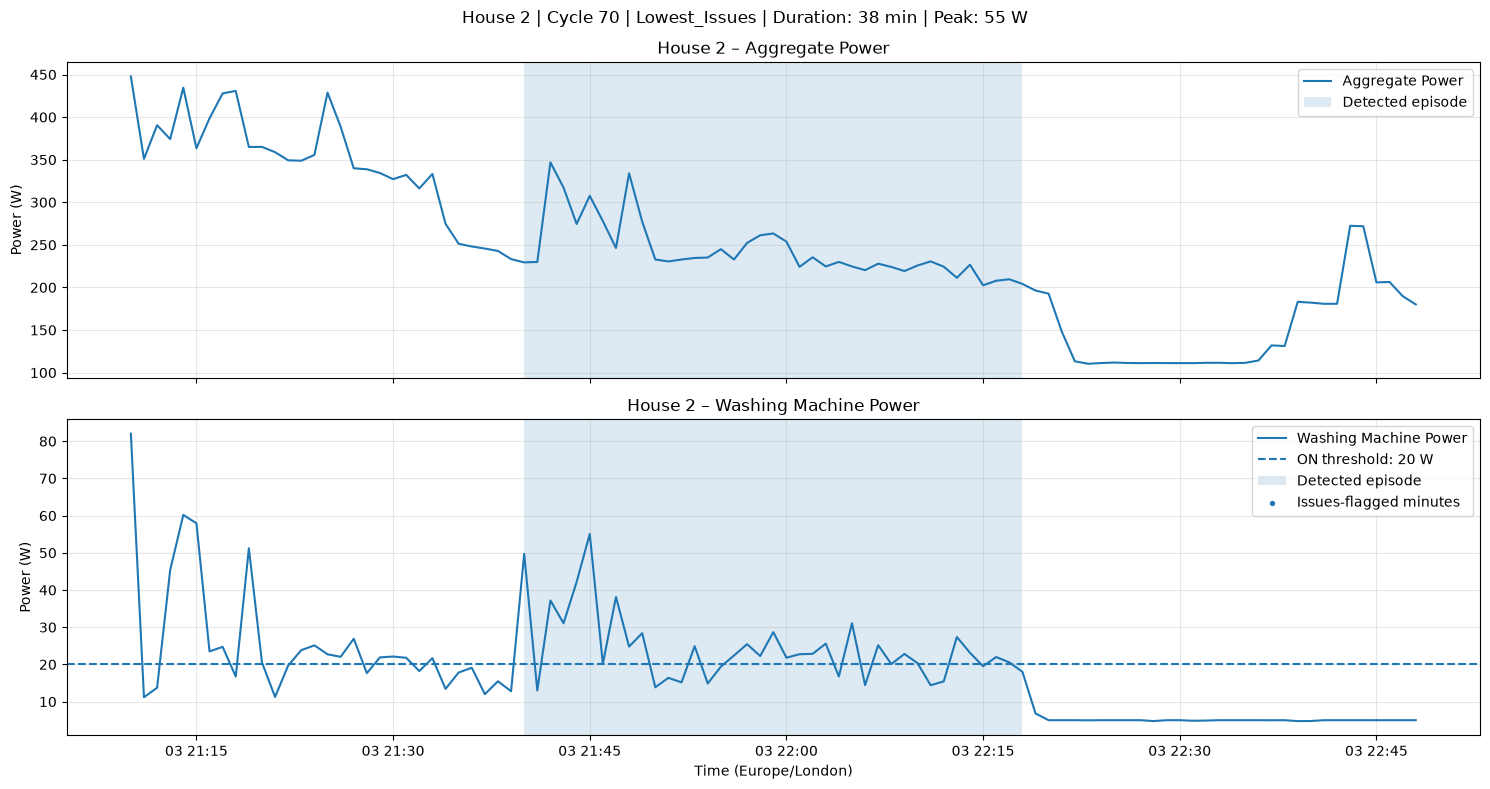


House 2 | Highest_Issues


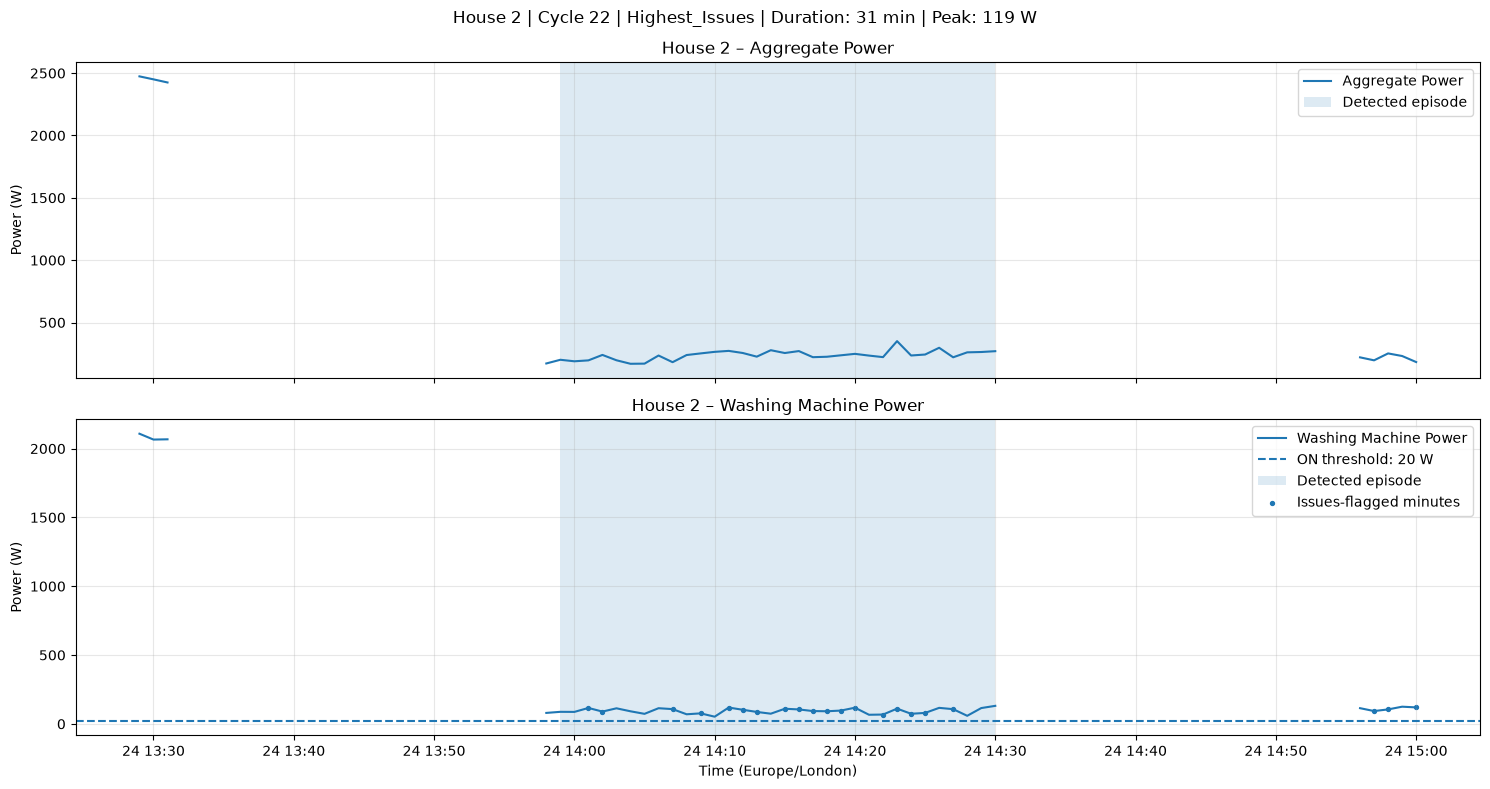


House 6 | Typical


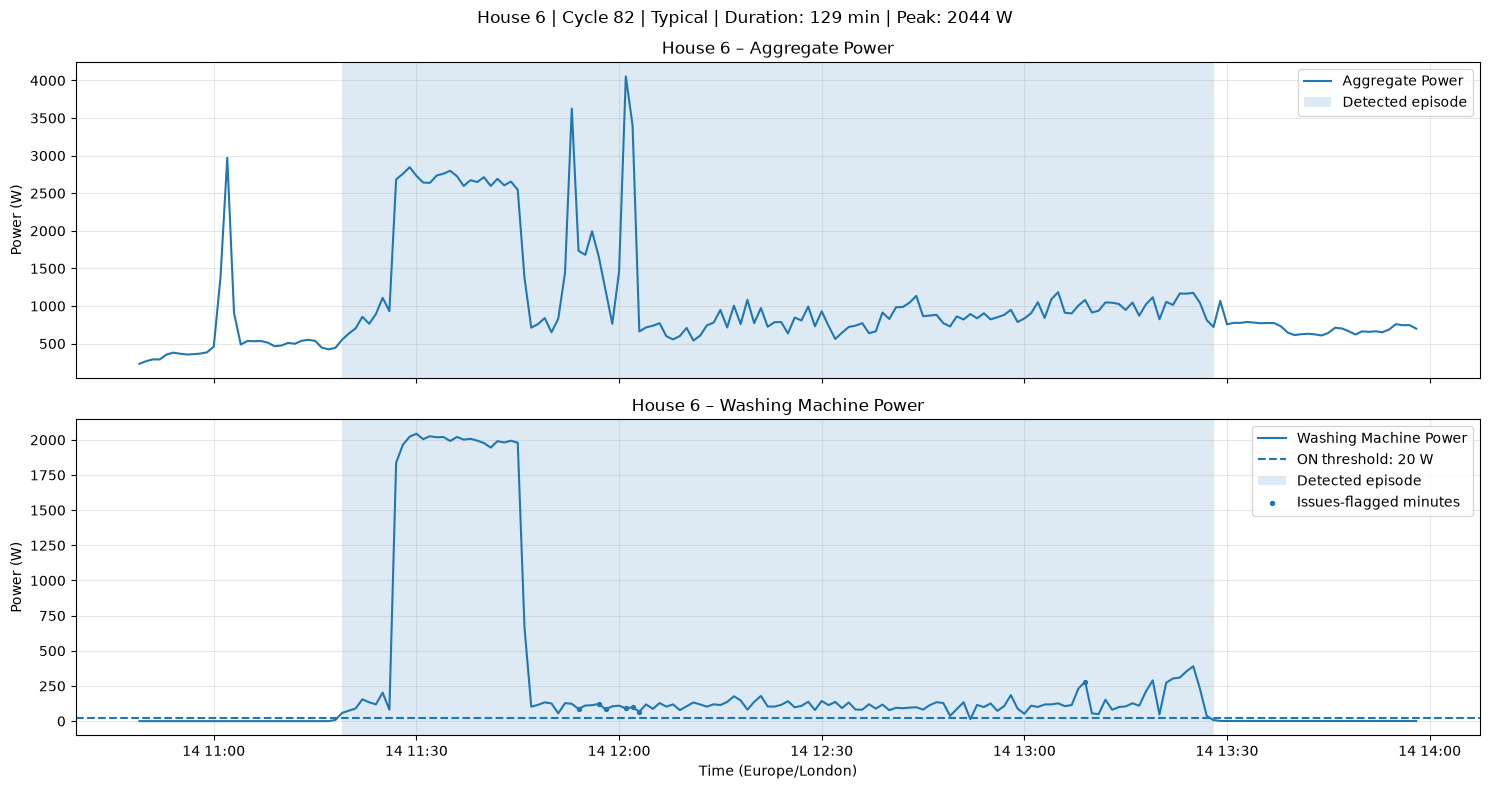


House 6 | Lowest_Issues


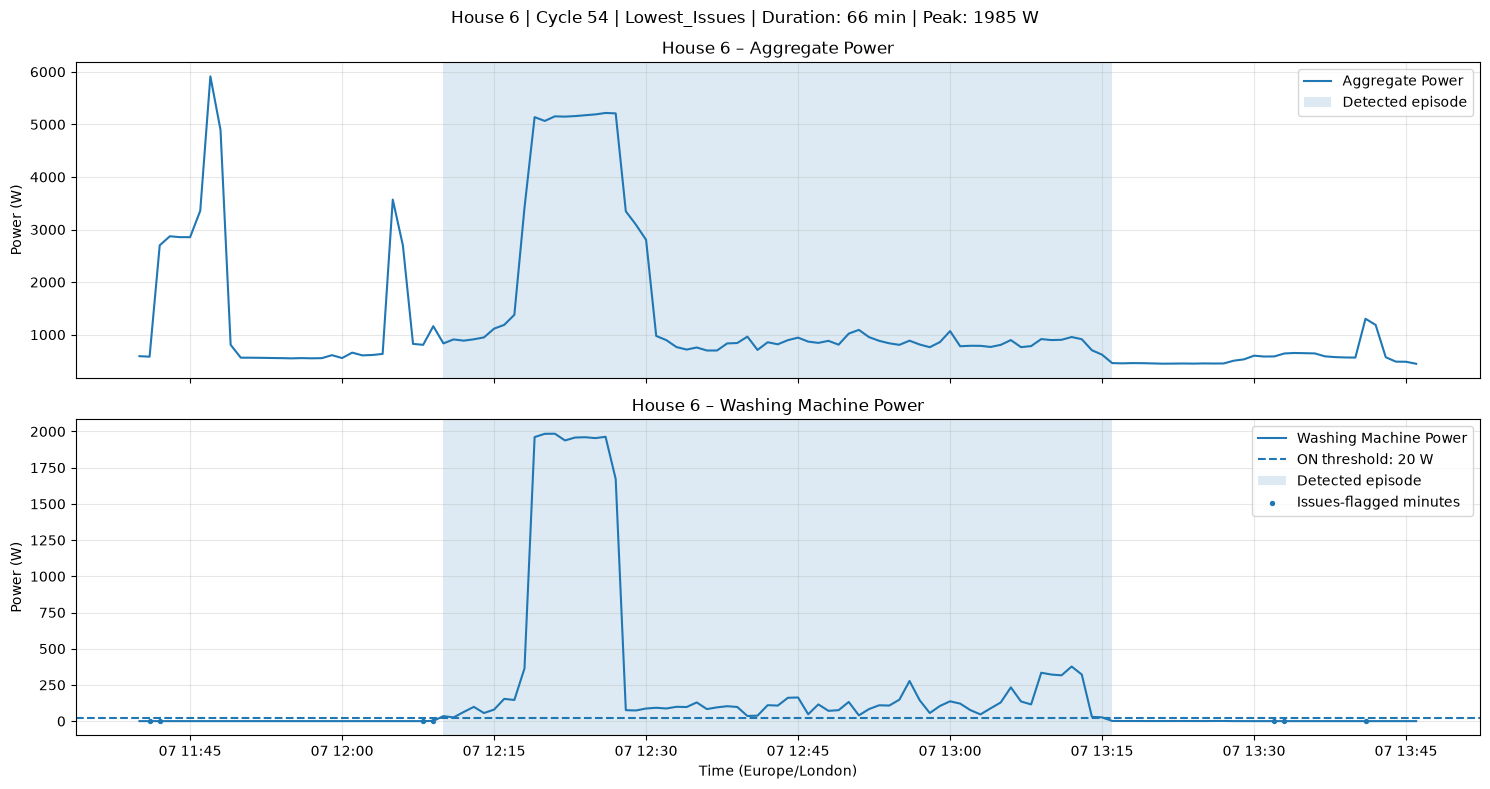


House 6 | Highest_Issues


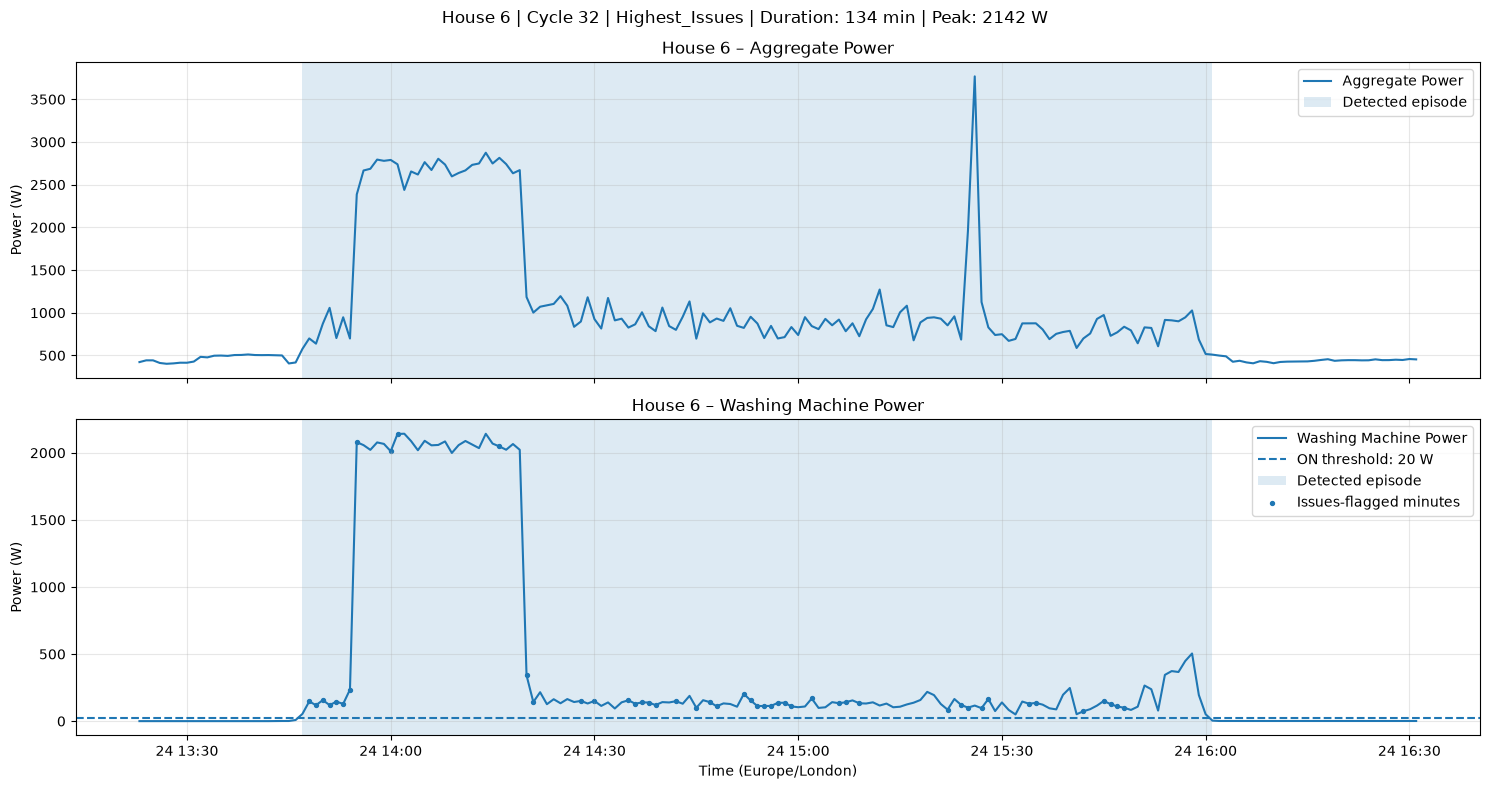


House 7 | Typical


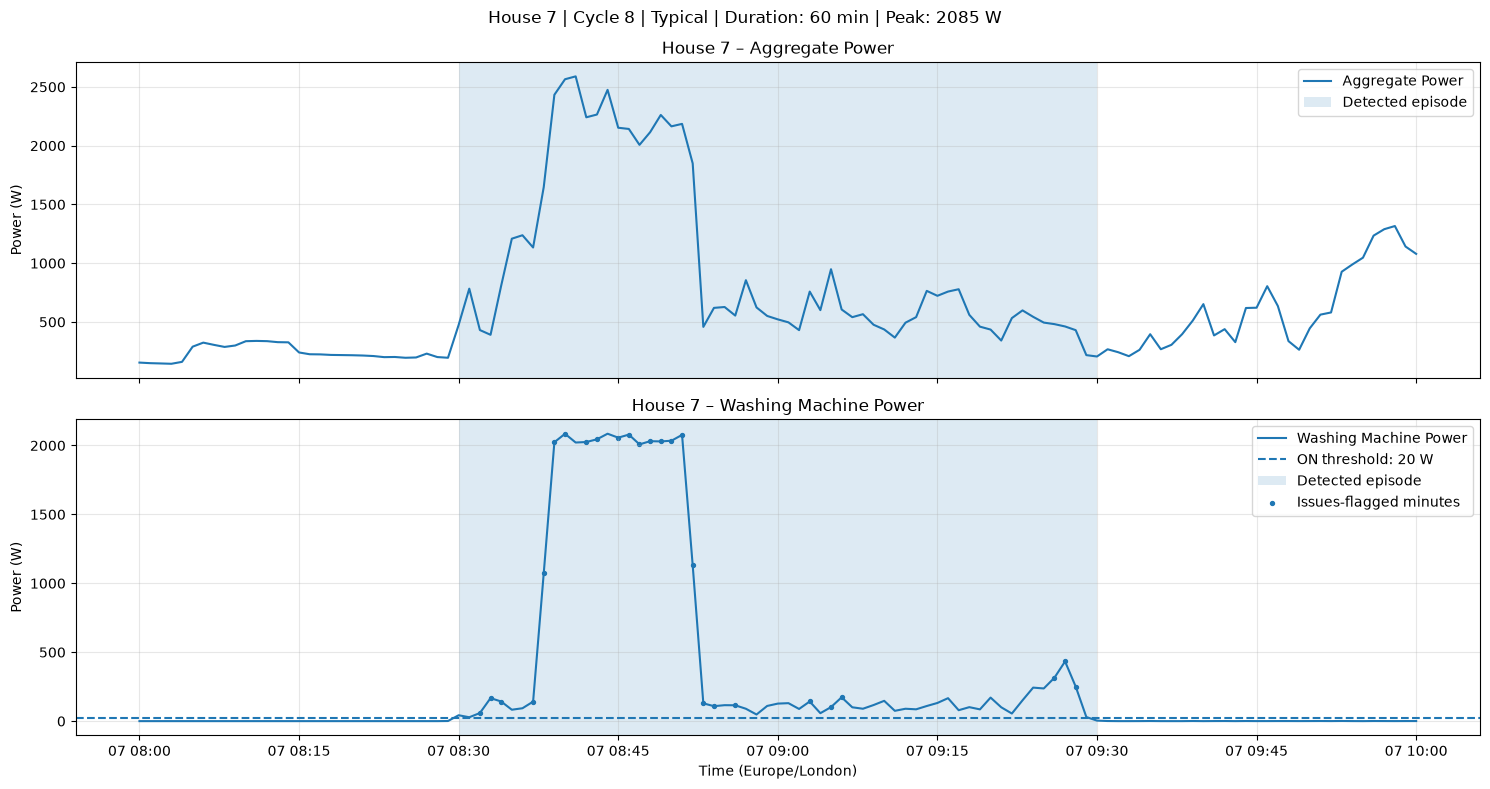


House 7 | Lowest_Issues


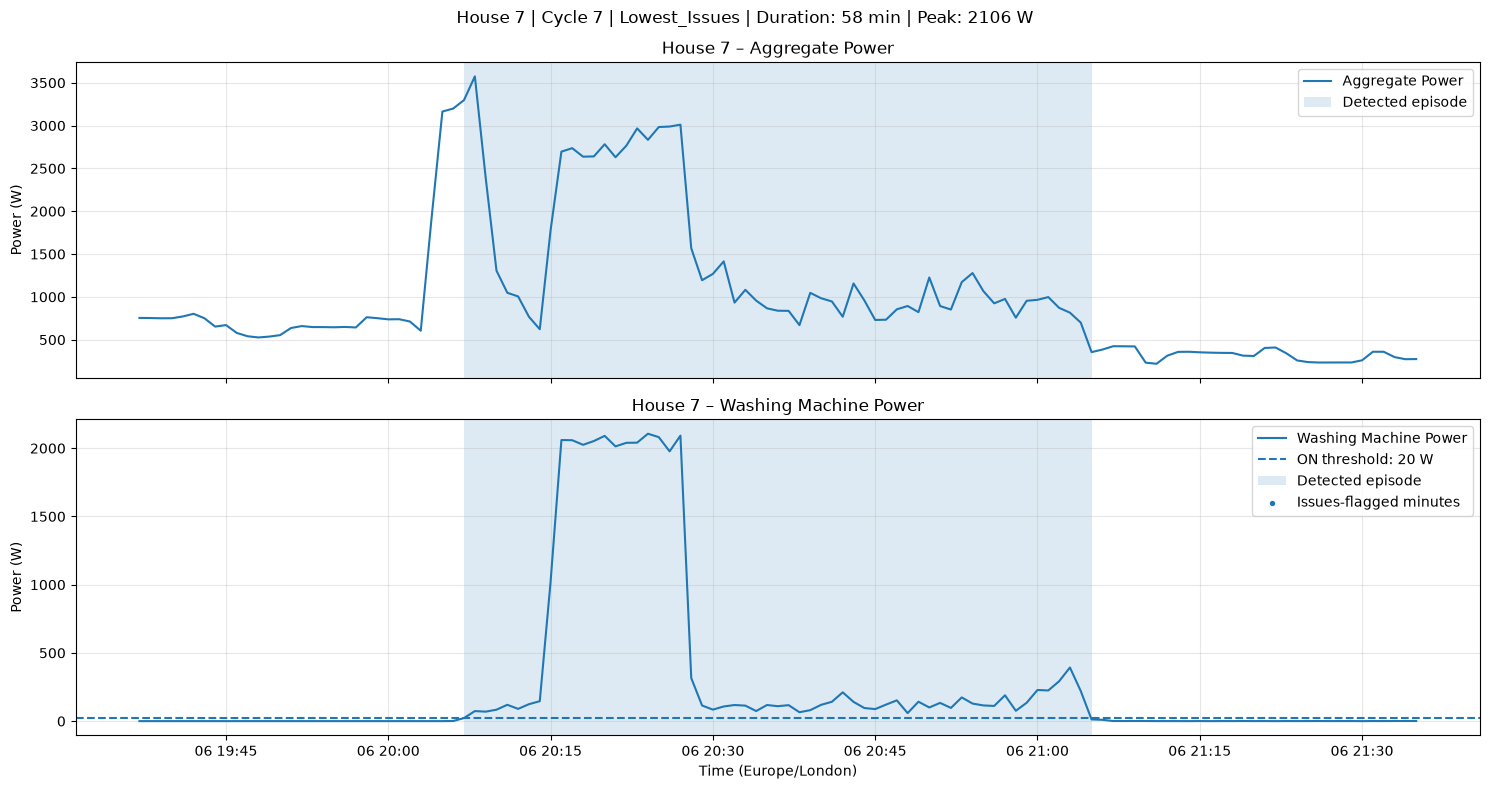


House 7 | Highest_Issues


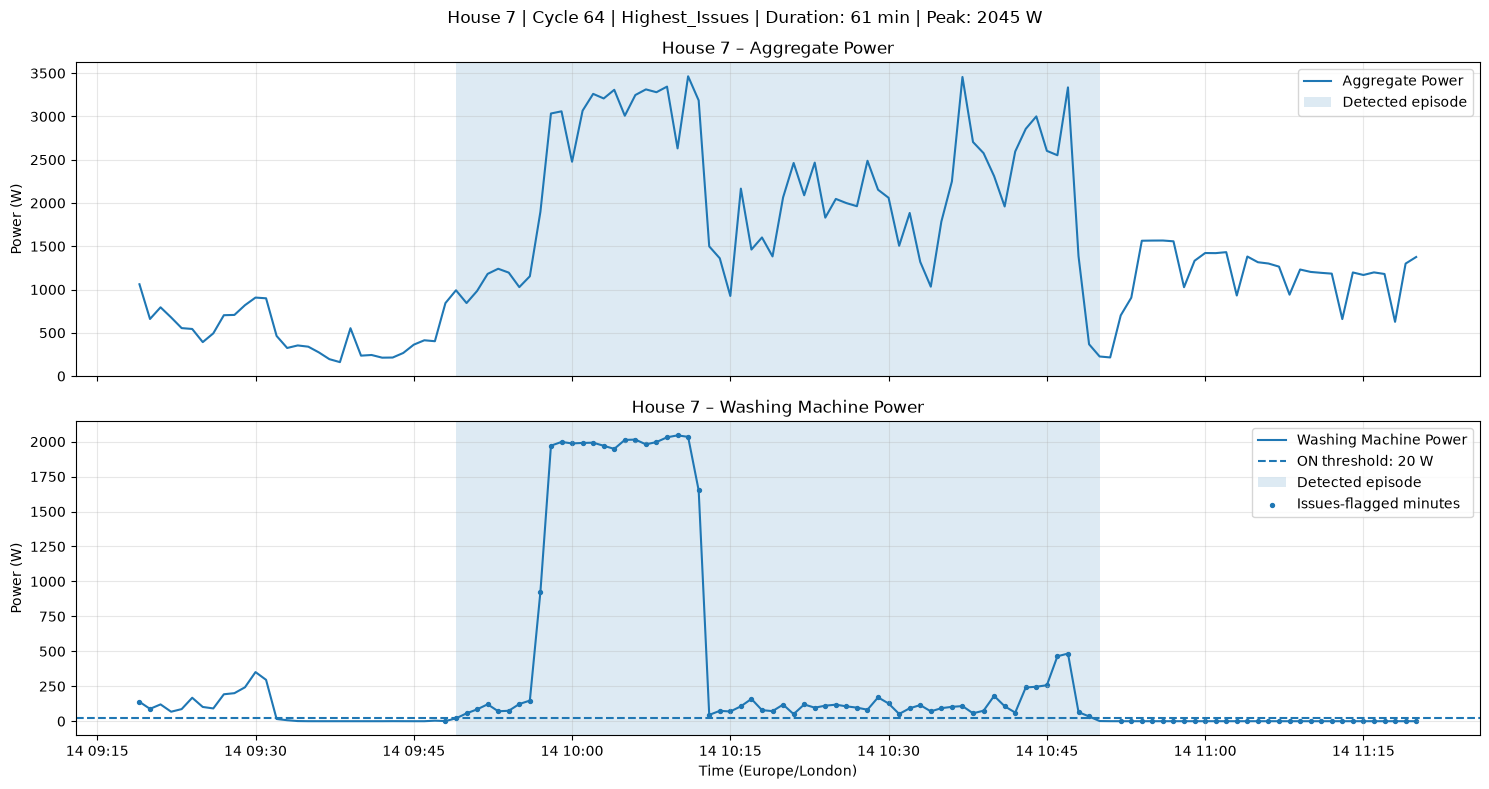

In [55]:
for _, event in representative_event_df.iterrows():

    print(
        f"\nHouse {int(event['House'])} | "
        f"{event['Validation_Type']}"
    )

    plot_detected_episode(
        house=int(event["House"]),
        cycle_id=int(event["Cycle_ID"]),
        validation_type=event["Validation_Type"]
    )

### Run the Representative Episode Validation Plots

**Cell purpose:** Calculate episode-level signatures such as active fraction, peak power and energy for the detected episodes.

In [56]:
episode_signature_results = []

for house in PRIMARY_HOUSES:

    df = pd.read_parquet(
        resampled_paths[house],
        columns=[
            "observed_seconds",
            "Washing_Machine_W",
            "Issues_Time_Pct"
        ]
    )

    episodes = duration_episode_store[(house, 27)]

    for _, event in episodes.iterrows():

        segment = df.loc[
            (df.index >= event["Start_UTC"])
            & (df.index < event["End_UTC"])
        ]

        power = segment["Washing_Machine_W"]

        valid = segment["observed_seconds"] == 60
        power = power[valid]

        active = power[power > 20]

        duration = len(power)

        if duration == 0:
            continue

        episode_signature_results.append({

            "House": house,

            "Cycle_ID": event["Cycle_ID"],

            "Duration_Min": duration,

            "Active_Minutes": len(active),

            "Active_Fraction_Pct": (
                len(active) / duration * 100
            ),

            "Peak_Power_W": power.max(),

            "P95_Power_W": power.quantile(0.95),

            "Minutes_Above_100W": (
                (power > 100).sum()
            ),

            "Minutes_Above_500W": (
                (power > 500).sum()
            ),

            "Minutes_Above_1000W": (
                (power > 1000).sum()
            ),

            "Issues_Minutes_Pct": (
                event["Issues_Minutes_Pct"]
            )
        })

    del df


episode_signature_df = pd.DataFrame(
    episode_signature_results
)

display(
    episode_signature_df.head(20).round(2)
)

,House,Cycle_ID,Duration_Min,Active_Minutes,Active_Fraction_Pct,Peak_Power_W,P95_Power_W,Minutes_Above_100W,Minutes_Above_500W,Minutes_Above_1000W,Issues_Minutes_Pct
0,1,1,34,29,85.29,2337.00,2262.68,19,7,5,26.47
1,1,2,36,32,88.89,2374.70,2313.94,21,7,6,5.56
2,1,3,32,29,90.62,2346.63,2337.57,21,6,6,31.25
3,1,4,34,31,91.18,2406.48,2311.52,23,8,6,32.35
4,1,5,32,29,90.62,2377.05,2341.70,18,6,6,18.75
5,1,6,35,31,88.57,2254.78,2252.88,22,6,6,28.57
6,1,7,32,28,87.50,2285.95,2244.64,16,6,6,31.25
7,1,8,35,32,91.43,2380.65,2343.26,22,6,6,37.14
8,1,9,32,29,90.62,2357.98,2344.59,18,8,6,43.75
9,1,10,41,34,82.93,2340.92,2265.77,25,10,10,46.34


**Cell purpose:** Aggregate the episode signatures by household to compare typical activation characteristics.

In [57]:
episode_signature_summary = (
    episode_signature_df
    .groupby("House")
    .agg(
        Total_Episodes=("Cycle_ID", "count"),

        Median_Duration=("Duration_Min", "median"),

        Median_Active_Fraction=(
            "Active_Fraction_Pct", "median"
        ),

        Median_Peak_Power=("Peak_Power_W", "median"),

        Episodes_Without_100W=(
            "Minutes_Above_100W",
            lambda x: (x == 0).mean() * 100
        ),

        Episodes_With_500W=(
            "Minutes_Above_500W",
            lambda x: (x > 0).mean() * 100
        ),

        Episodes_With_1000W=(
            "Minutes_Above_1000W",
            lambda x: (x > 0).mean() * 100
        )
    )
    .round(2)
)

display(episode_signature_summary)

,Total_Episodes,Median_Duration,Median_Active_Fraction,Median_Peak_Power,Episodes_Without_100W,Episodes_With_500W,Episodes_With_1000W
House,,,,,,,
1,395,33.0,90.91,2321.87,0.25,99.49,98.99
2,338,96.0,95.00,2088.90,0.59,95.27,95.27
6,121,129.0,100.00,2049.18,0.00,90.91,90.08
7,878,60.0,100.00,2080.82,0.00,99.54,99.54


**Cell purpose:** Summarize the distribution of detected episode durations using percentiles and counts of unusually long events.

In [58]:
duration_validation = (
    episode_signature_df
    .groupby("House")
    .agg(

        Total_Episodes=("Cycle_ID", "count"),

        P10_Duration=(
            "Duration_Min",
            lambda x: x.quantile(0.10)
        ),

        P25_Duration=(
            "Duration_Min",
            lambda x: x.quantile(0.25)
        ),

        Median_Duration=(
            "Duration_Min",
            "median"
        ),

        P75_Duration=(
            "Duration_Min",
            lambda x: x.quantile(0.75)
        ),

        P90_Duration=(
            "Duration_Min",
            lambda x: x.quantile(0.90)
        ),

        P95_Duration=(
            "Duration_Min",
            lambda x: x.quantile(0.95)
        ),

        Maximum_Duration=(
            "Duration_Min",
            "max"
        ),

        Episodes_Above_180_Min=(
            "Duration_Min",
            lambda x: (x > 180).sum()
        ),

        Episodes_Above_240_Min=(
            "Duration_Min",
            lambda x: (x > 240).sum()
        ),

        Median_Active_Fraction=(
            "Active_Fraction_Pct",
            "median"
        ),

        Episodes_Issues_Above_50_Pct=(
            "Issues_Minutes_Pct",
            lambda x: (x > 50).sum()
        )
    )
    .round(2)
)

display(duration_validation)

,Total_Episodes,P10_Duration,P25_Duration,Median_Duration,P75_Duration,P90_Duration,P95_Duration,Maximum_Duration,Episodes_Above_180_Min,Episodes_Above_240_Min,Median_Active_Fraction,Episodes_Issues_Above_50_Pct
House,,,,,,,,,,,,
1,395,32.0,32.0,33.0,35.0,64.6,73.00,189,1,0,90.91,23
2,338,69.0,88.0,96.0,104.0,131.2,159.00,204,3,0,95.00,2
6,121,57.0,75.0,129.0,132.0,139.0,148.00,266,2,2,100.00,0
7,878,54.7,57.0,60.0,103.0,111.0,114.15,229,4,0,100.00,100


### Review Unusually Long and Potentially Unreliable Episodes

**Cell purpose:** Identify detected episodes longer than the chosen review duration for additional quality inspection.

In [59]:
long_episode_reviews = []

for house in PRIMARY_HOUSES:

    episodes = duration_episode_store[(house, 27)]

    long_episodes = episodes[
        episodes["Duration_Min"] > 180
    ]

    for _, event in long_episodes.iterrows():

        long_episode_reviews.append({

            "House": house,

            "Cycle_ID": event["Cycle_ID"],

            "Start_UTC": event["Start_UTC"],

            "End_UTC": event["End_UTC"],

            "Duration_Min": event["Duration_Min"],

            "Active_Minutes": event["Active_Minutes"],

            "Peak_Power_W": event["Peak_Power_W"],

            "Energy_Wh": event["Energy_Wh"],

            "Issues_Minutes_Pct": (
                event["Issues_Minutes_Pct"]
            )
        })


long_episode_review_df = pd.DataFrame(
    long_episode_reviews
)

display(
    long_episode_review_df.round(2)
)

/var/folders/4y/wyg1yj8s6171ybbm1q81x0m00000gn/T/ipykernel_3174/1642129121.py:42: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  long_episode_review_df.round(2)


,House,Cycle_ID,Start_UTC,End_UTC,Duration_Min,Active_Minutes,Peak_Power_W,Energy_Wh,Issues_Minutes_Pct
0,1,117,2014-05-04 08:41:00+00:00,2014-05-04 11:50:00+00:00,189,164,2359.23,1367.99,30.16
1,2,142,2014-08-11 06:44:00+00:00,2014-08-11 09:46:00+00:00,182,169,2096.87,863.52,20.88
2,2,287,2015-03-04 16:13:00+00:00,2015-03-04 19:15:00+00:00,182,179,2055.35,771.94,6.04
3,2,320,2015-04-23 12:59:00+00:00,2015-04-23 16:23:00+00:00,204,188,2118.48,1317.24,31.37
4,6,7,2013-12-28 12:55:00+00:00,2013-12-28 17:21:00+00:00,266,260,2060.55,1565.94,16.92
5,6,30,2014-04-18 09:56:00+00:00,2014-04-18 14:21:00+00:00,265,258,2149.90,1262.06,7.17
6,7,194,2014-04-22 17:21:00+00:00,2014-04-22 21:00:00+00:00,219,217,2117.25,1225.09,17.35
7,7,195,2014-04-23 06:49:00+00:00,2014-04-23 10:31:00+00:00,222,217,2124.37,1237.55,53.60
8,7,196,2014-04-23 11:31:00+00:00,2014-04-23 14:50:00+00:00,199,197,2153.80,932.88,25.63
9,7,717,2015-03-27 18:12:00+00:00,2015-03-27 22:01:00+00:00,229,224,2096.70,1217.90,4.80


**Cell purpose:** Identify episodes with high proportions of Issues-affected minutes for additional quality inspection.

In [60]:
high_issue_reviews = []

for house in PRIMARY_HOUSES:

    episodes = duration_episode_store[(house, 27)]

    suspicious = episodes[
        episodes["Issues_Minutes_Pct"] > 50
    ]

    # Pick the two most suspicious episodes per household
    selected = suspicious.nlargest(
        2,
        "Issues_Minutes_Pct"
    )

    for _, event in selected.iterrows():

        high_issue_reviews.append({

            "House": house,

            "Cycle_ID": event["Cycle_ID"],

            "Duration_Min": event["Duration_Min"],

            "Peak_Power_W": event["Peak_Power_W"],

            "Energy_Wh": event["Energy_Wh"],

            "Issues_Minutes_Pct": (
                event["Issues_Minutes_Pct"]
            )
        })


high_issue_review_df = pd.DataFrame(
    high_issue_reviews
)

display(
    high_issue_review_df.round(2)
)

,House,Cycle_ID,Duration_Min,Peak_Power_W,Energy_Wh,Issues_Minutes_Pct
0,1,29,33,2280.75,320.12,100.00
1,1,210,100,514.00,848.10,100.00
2,2,22,31,118.62,47.79,58.06
3,2,26,155,2074.53,804.13,54.84
4,7,64,61,2044.92,599.31,100.00
5,7,35,62,2097.07,595.53,98.39


**Cell purpose:** Plot the long-duration episodes selected for manual review.

House 1 | Cycle 117 | 189 minutes


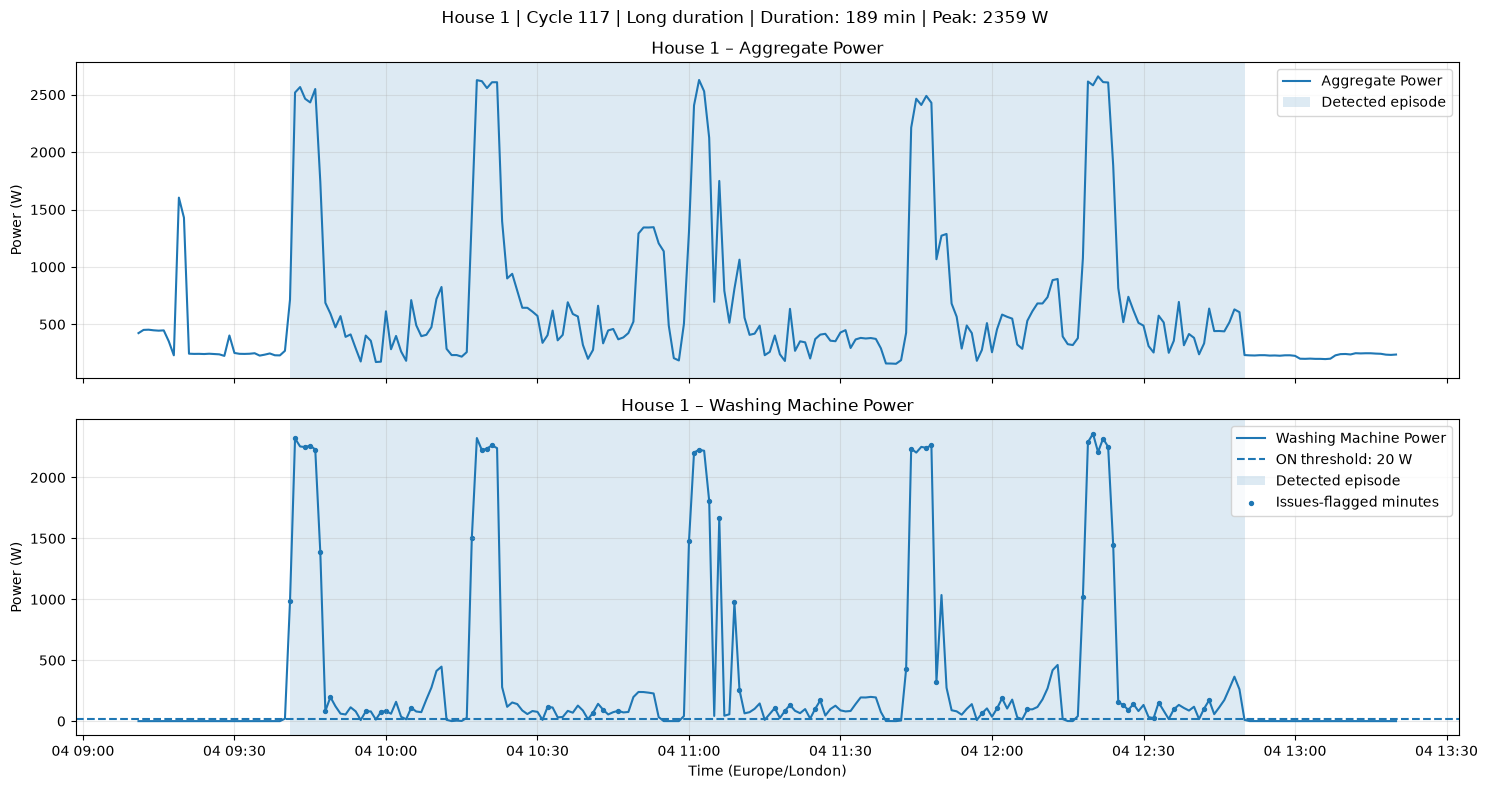

House 2 | Cycle 142 | 182 minutes


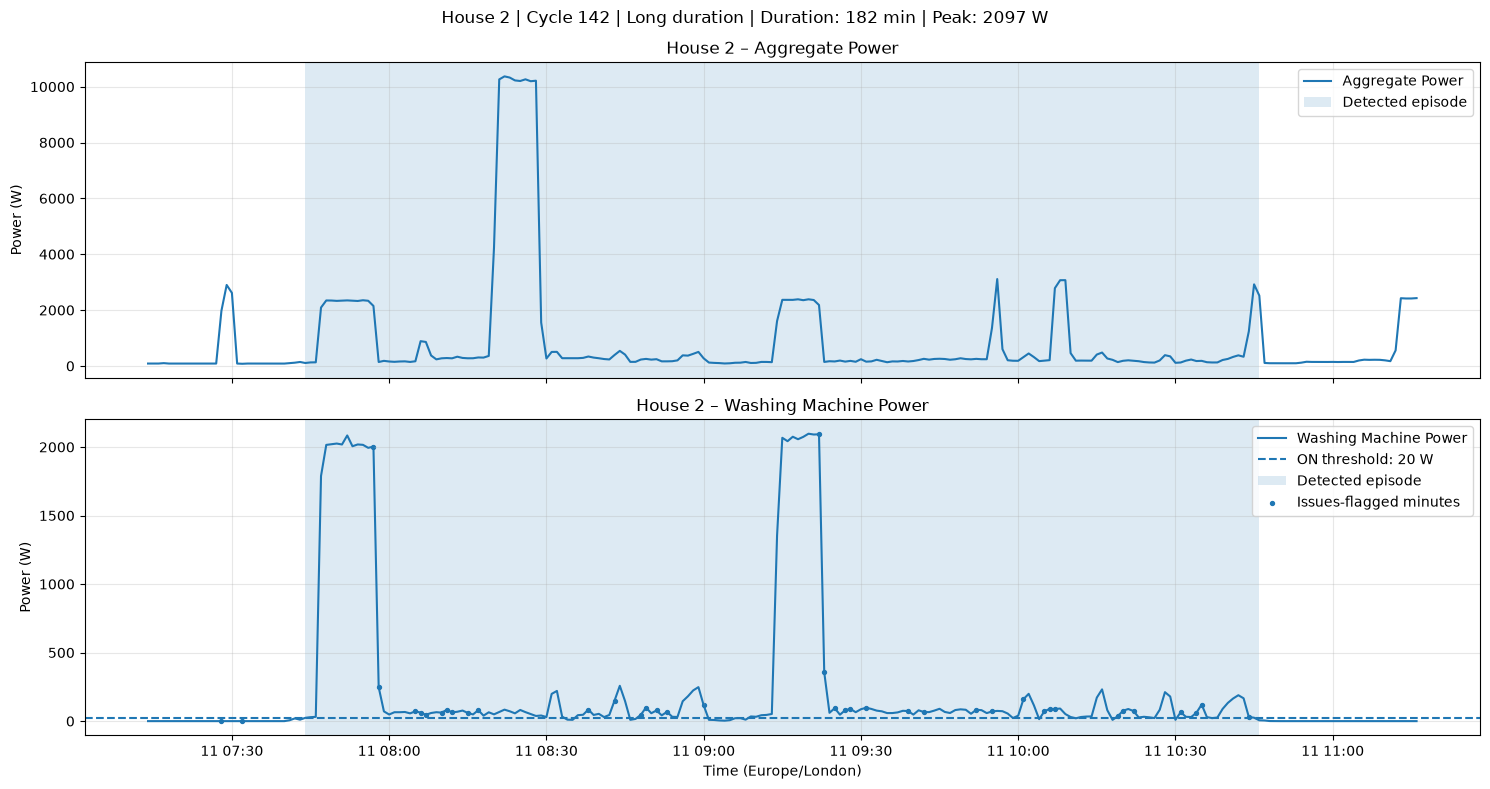

House 2 | Cycle 287 | 182 minutes


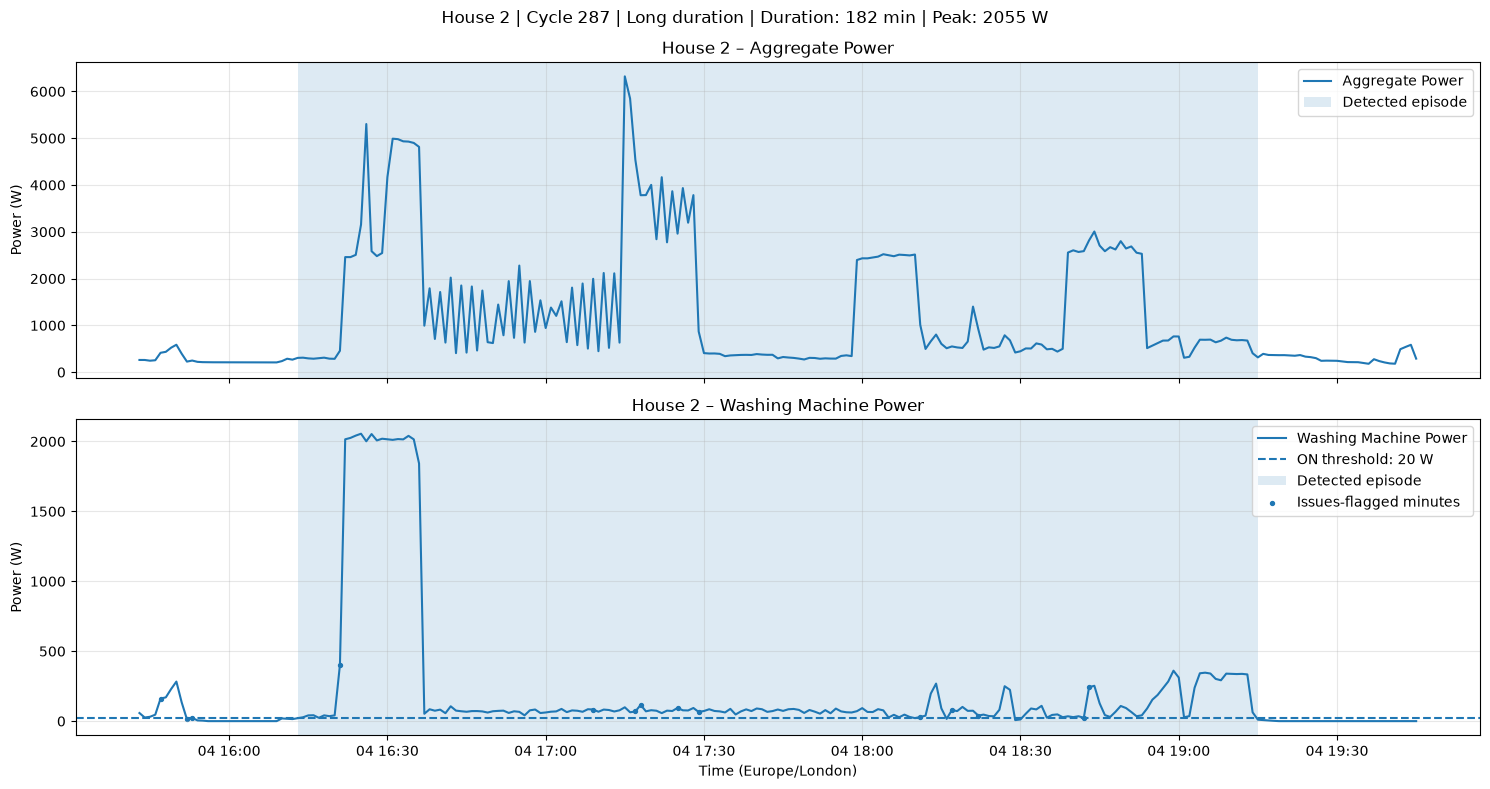

House 2 | Cycle 320 | 204 minutes


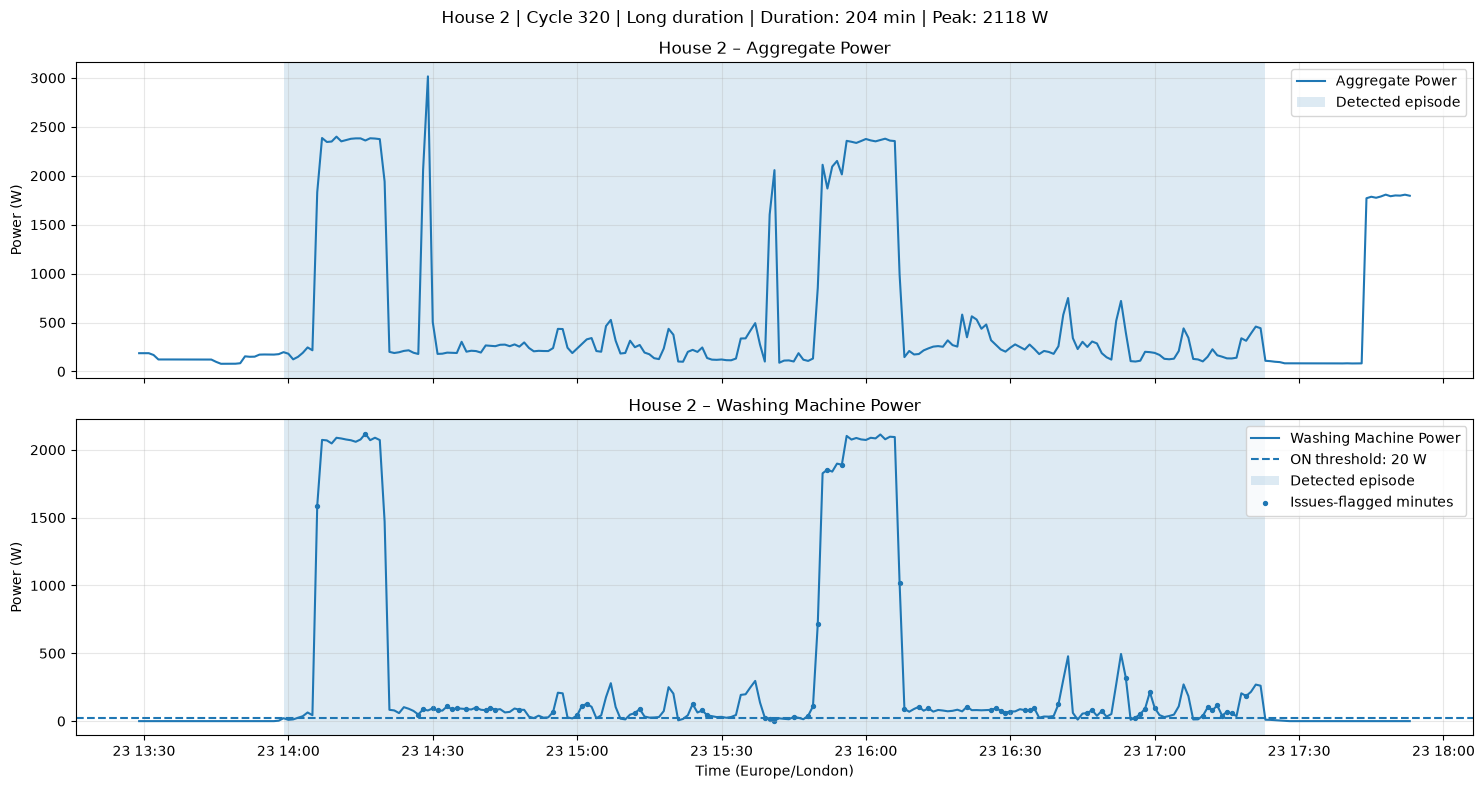

House 6 | Cycle 7 | 266 minutes


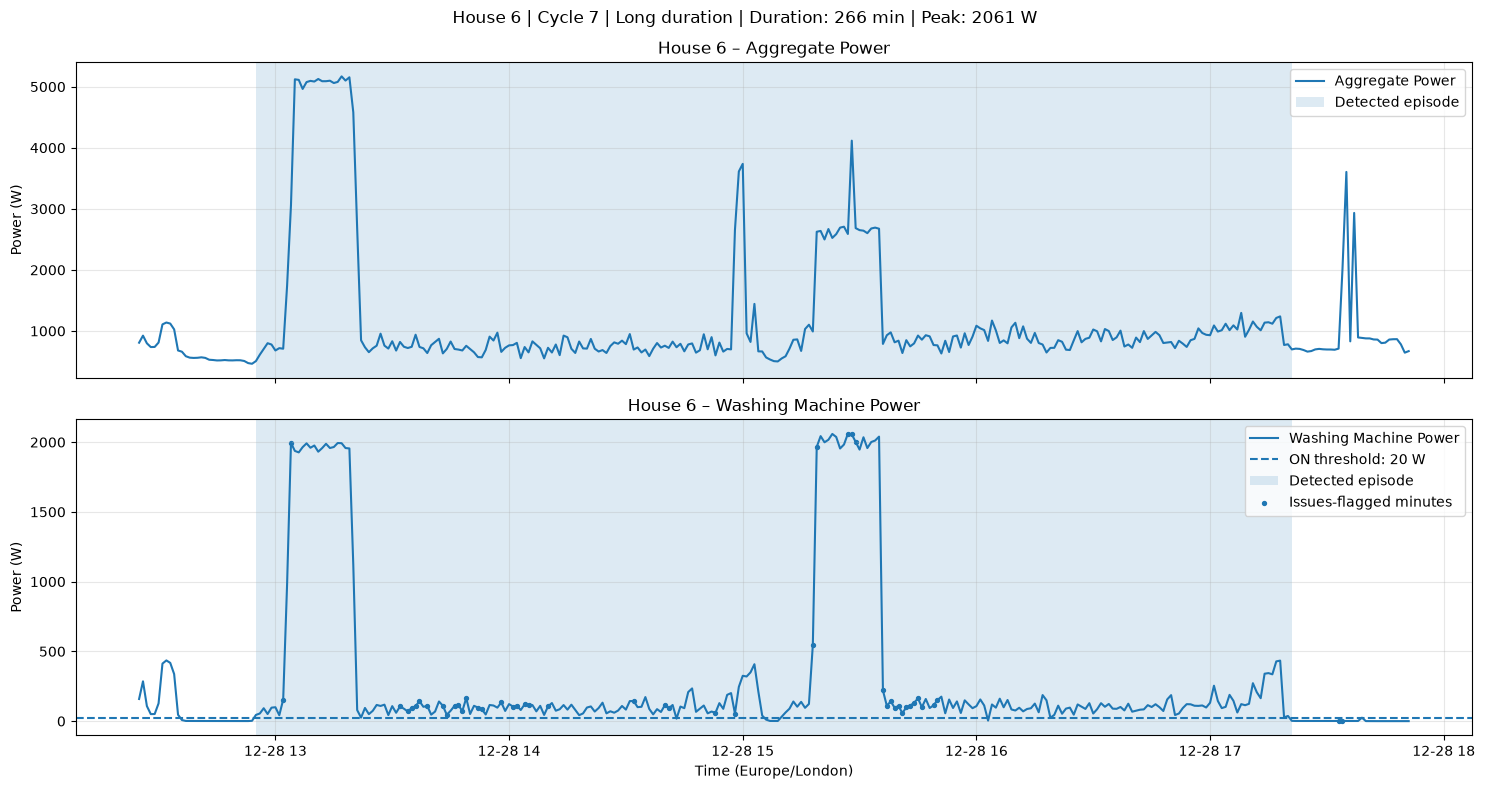

House 6 | Cycle 30 | 265 minutes


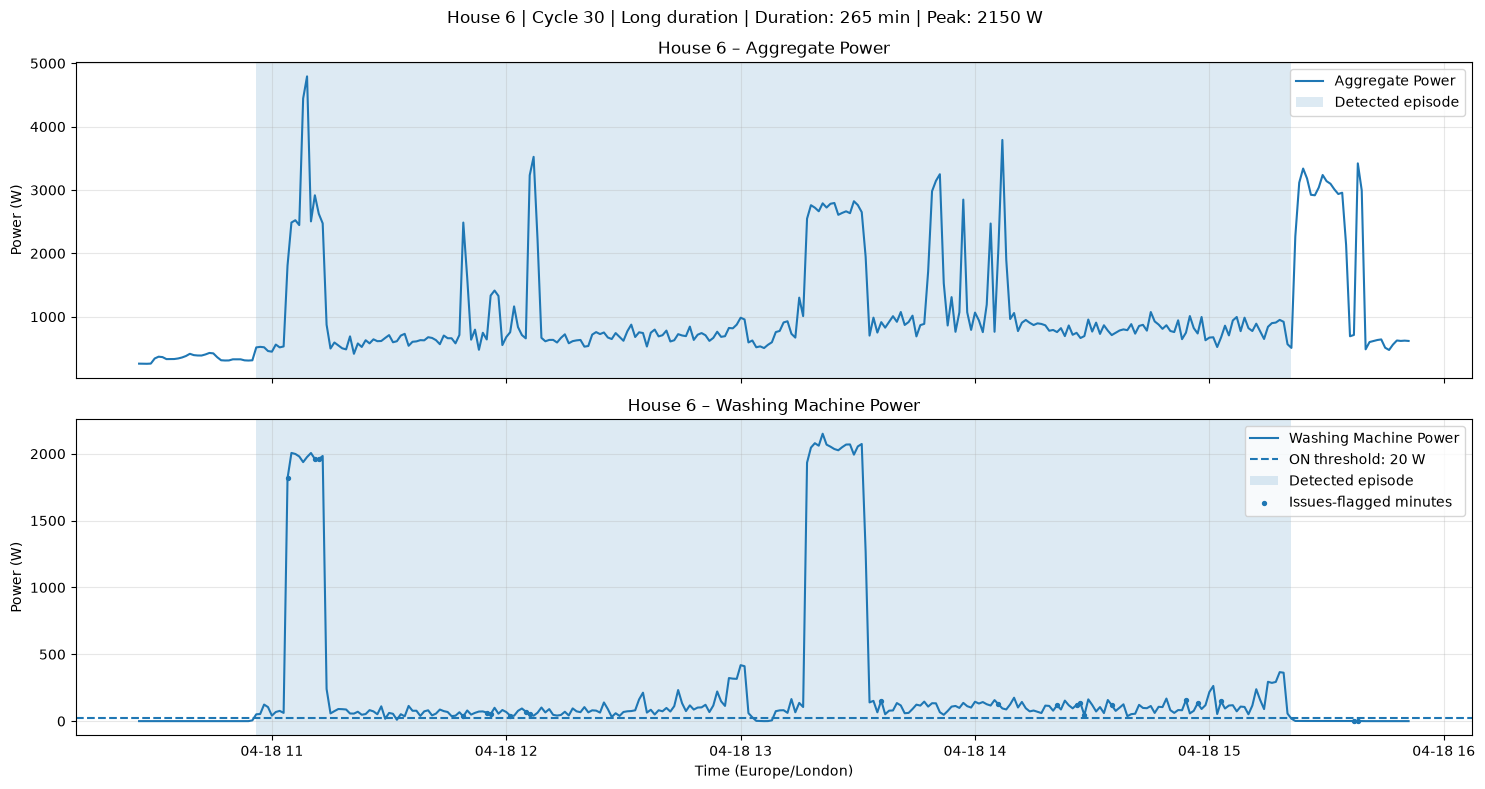

House 7 | Cycle 194 | 219 minutes


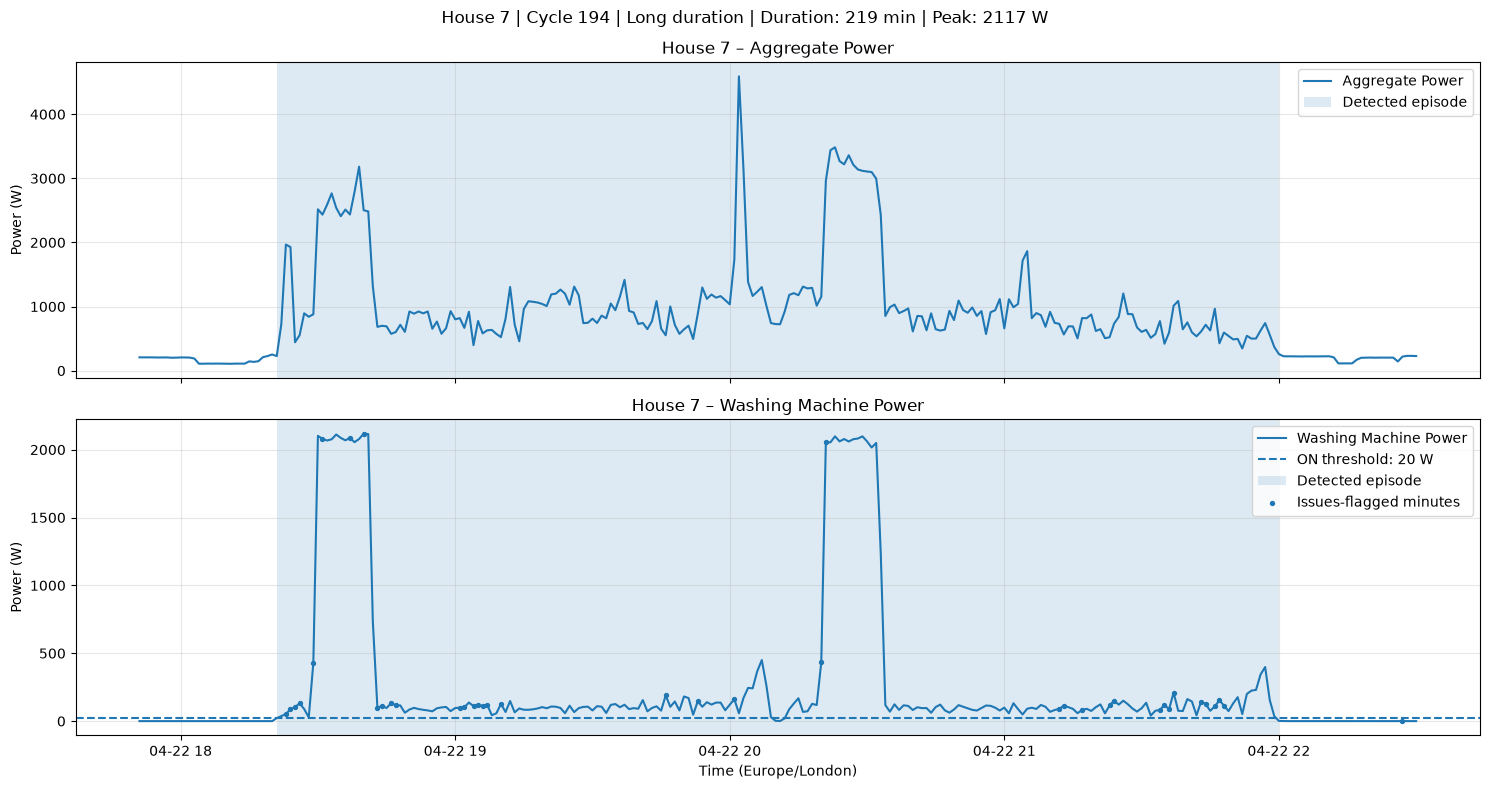

House 7 | Cycle 195 | 222 minutes


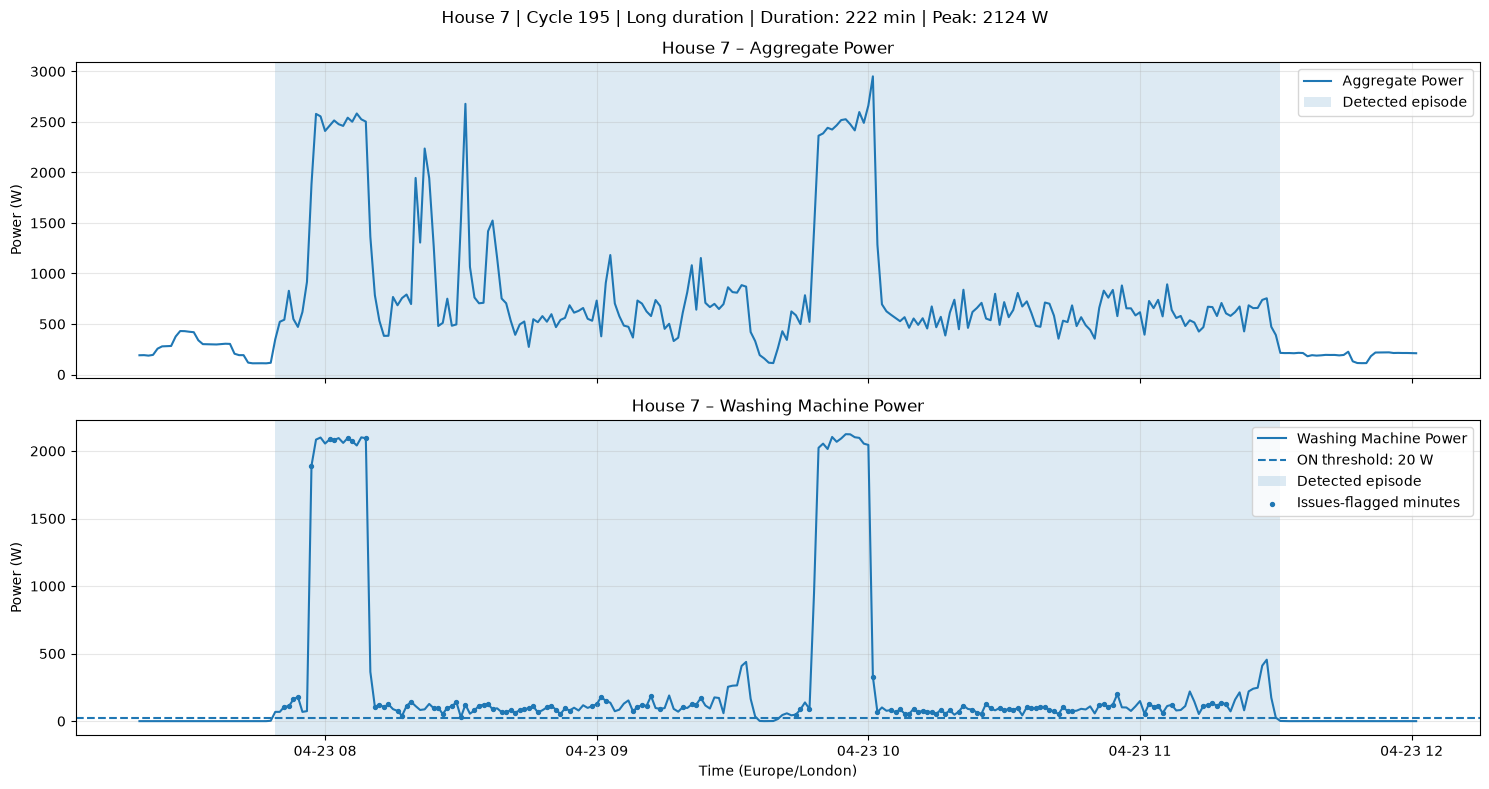

House 7 | Cycle 196 | 199 minutes


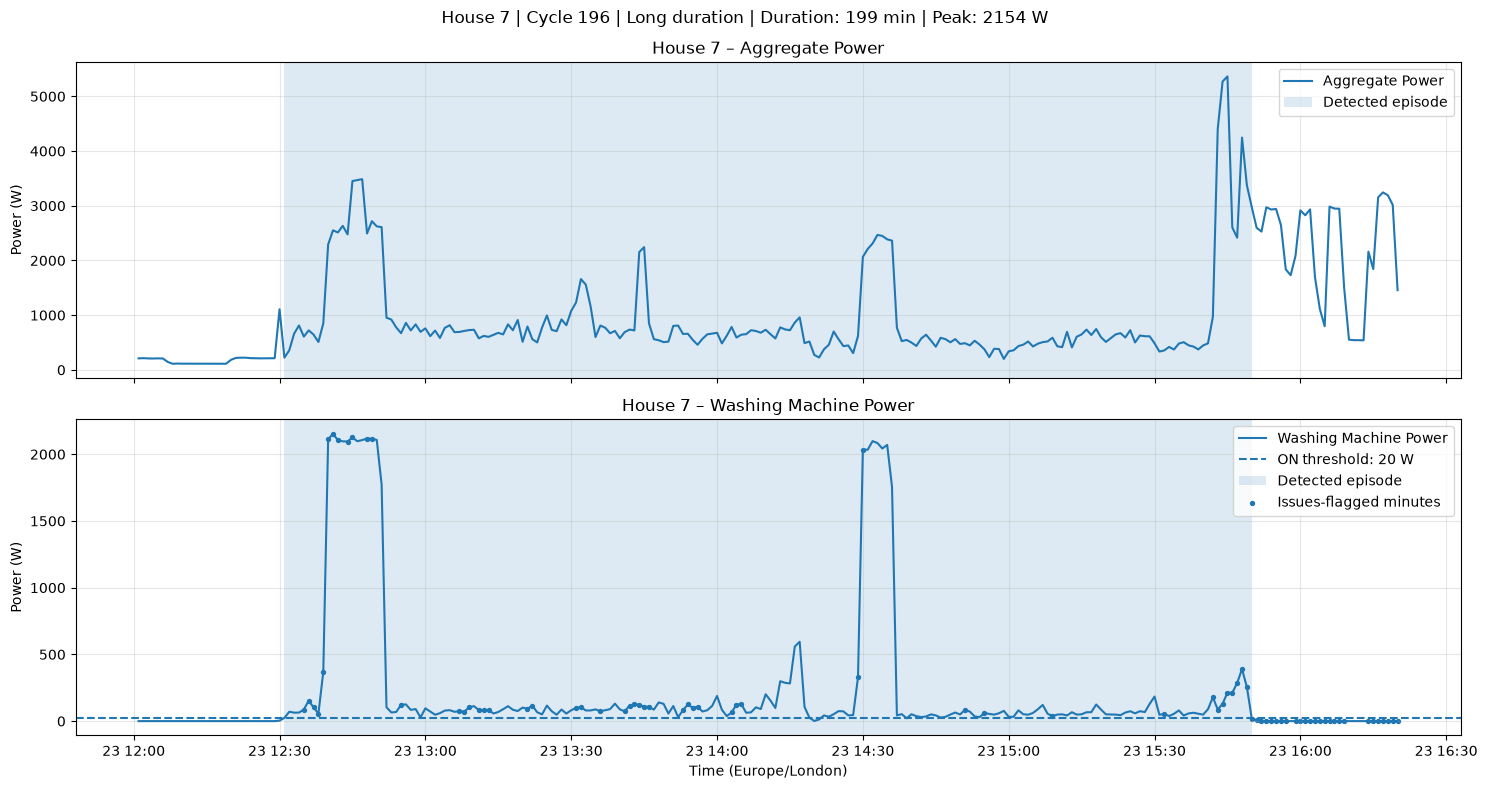

House 7 | Cycle 717 | 229 minutes


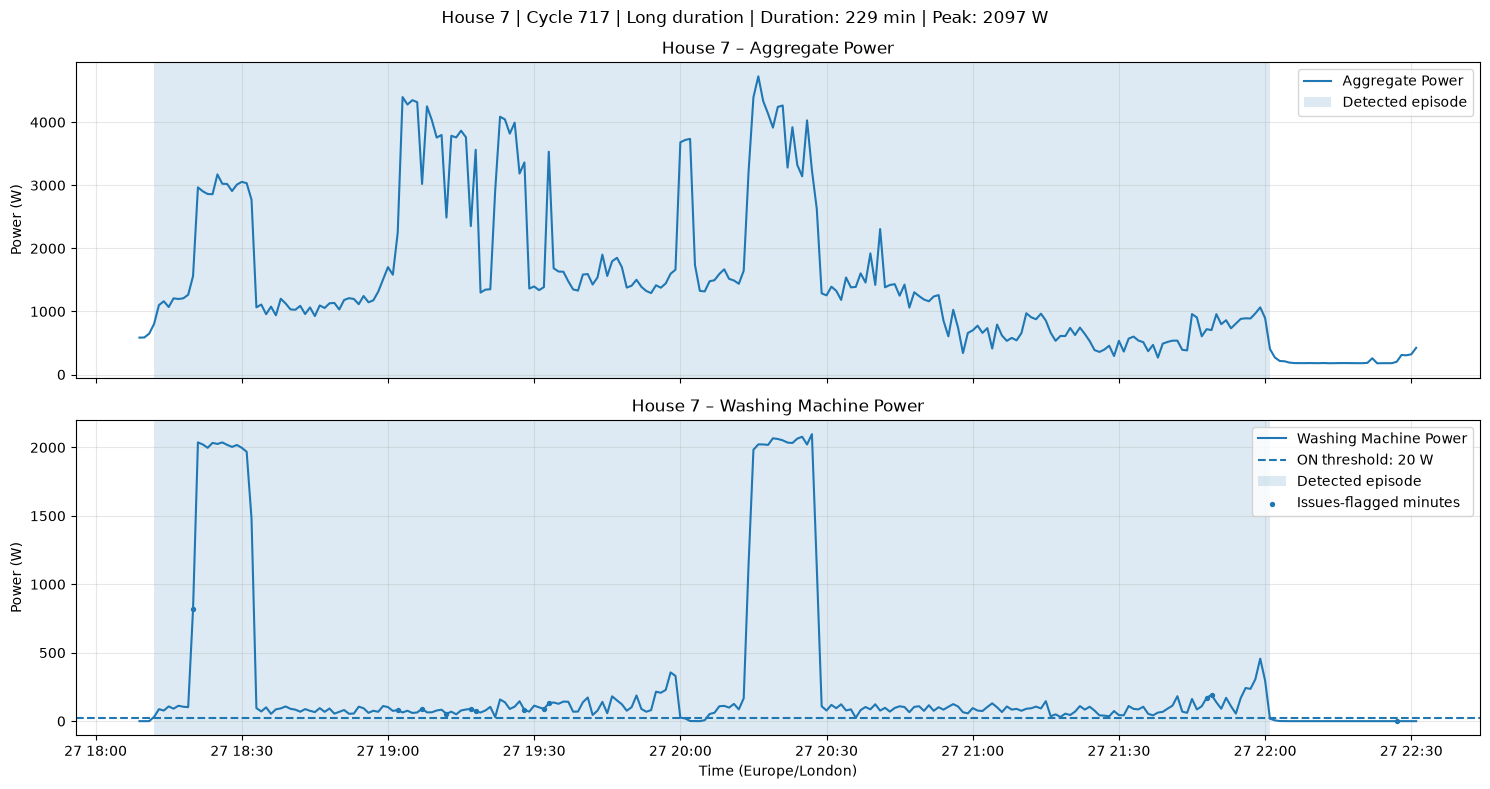

In [61]:
for _, event in long_episode_review_df.iterrows():

    print(
        f"House {int(event['House'])} | "
        f"Cycle {int(event['Cycle_ID'])} | "
        f"{event['Duration_Min']:.0f} minutes"
    )

    plot_detected_episode(
        house=int(event["House"]),
        cycle_id=int(event["Cycle_ID"]),
        validation_type="Long duration"
    )

**Cell purpose:** Plot selected high-Issues or otherwise suspicious episodes to inspect their signal behaviour.


House 1 | Cycle 117 | Long duration


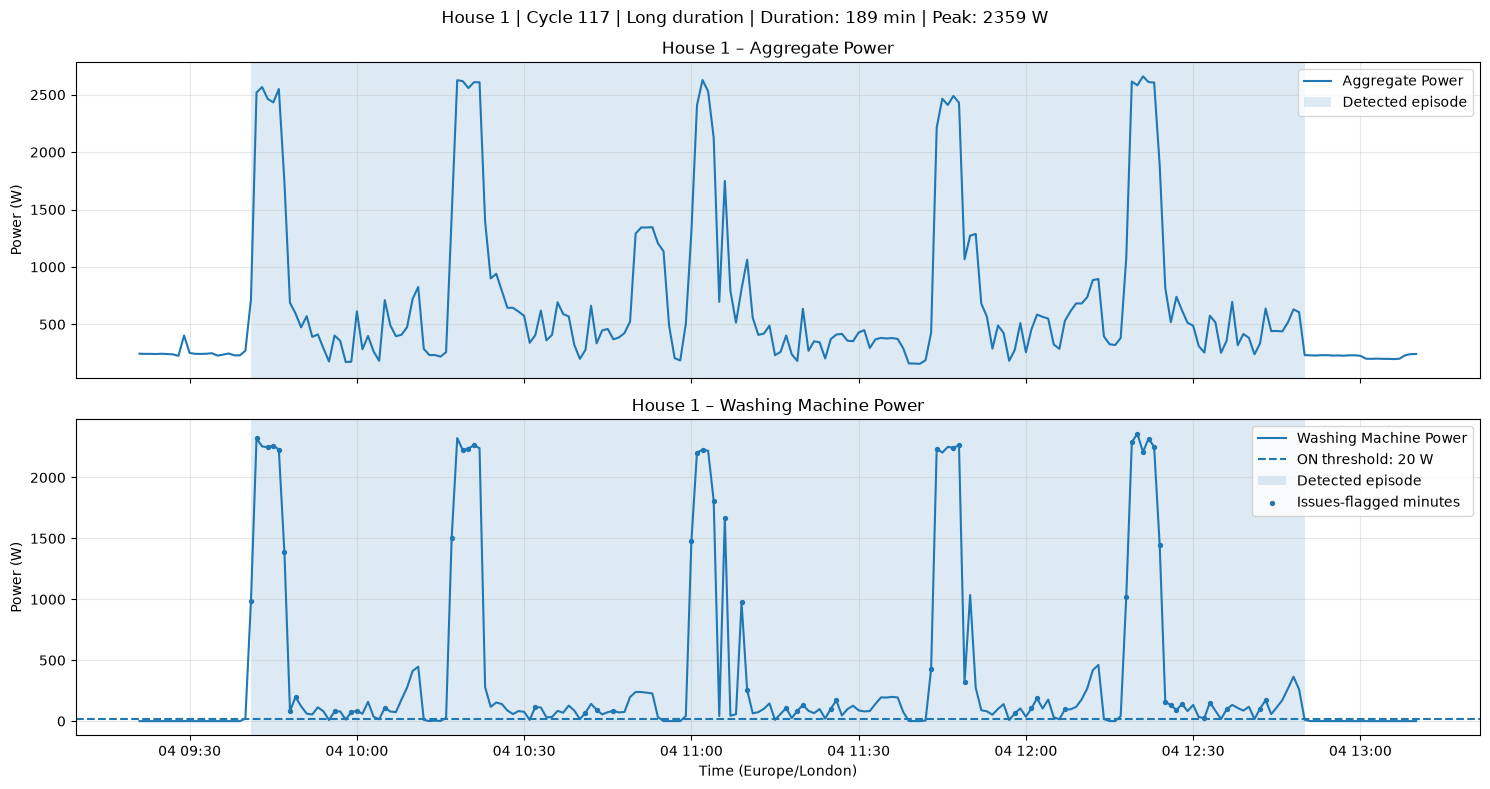


House 1 | Cycle 210 | 100% Issues


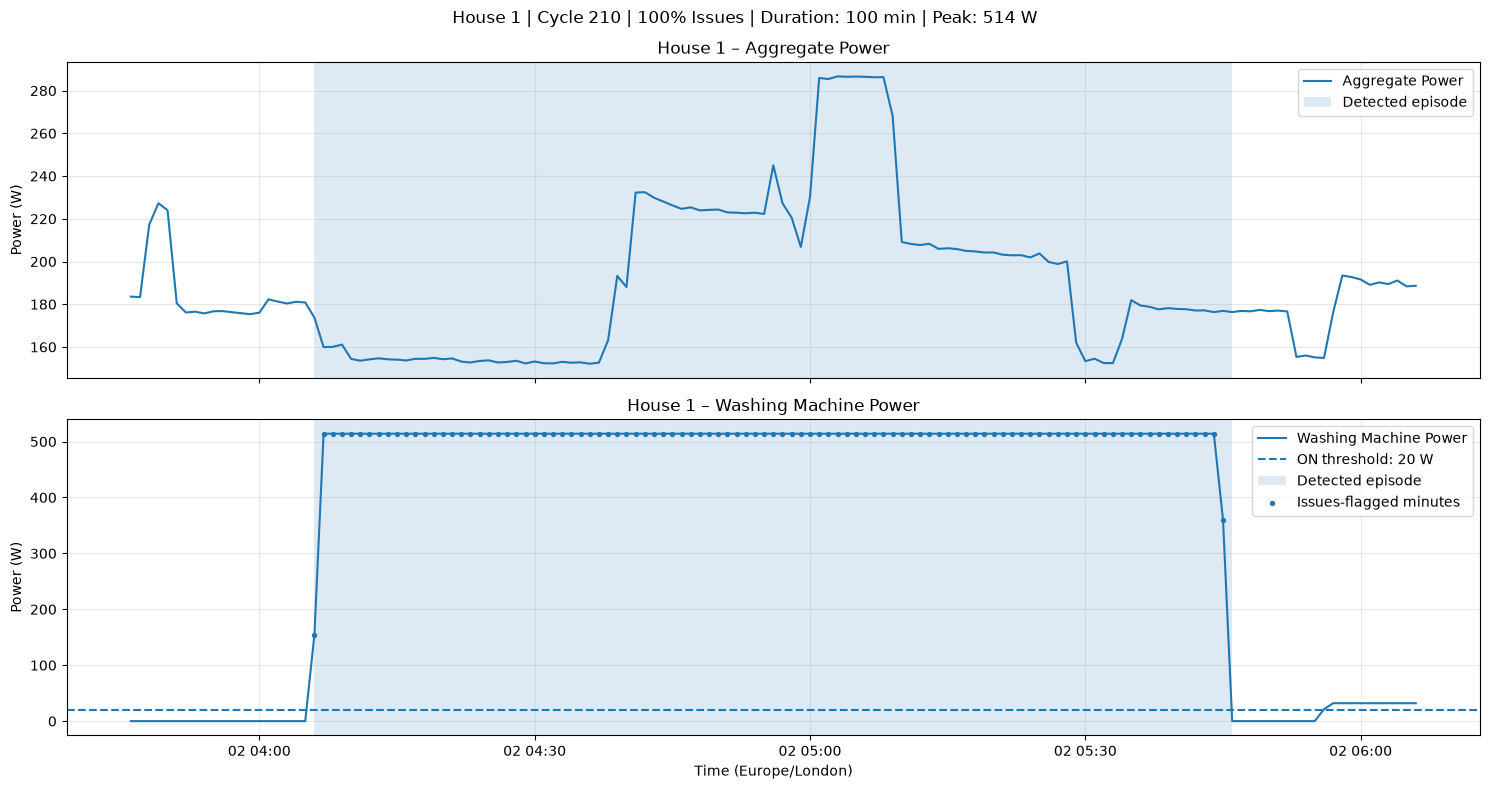


House 2 | Cycle 320 | Long duration + Issues


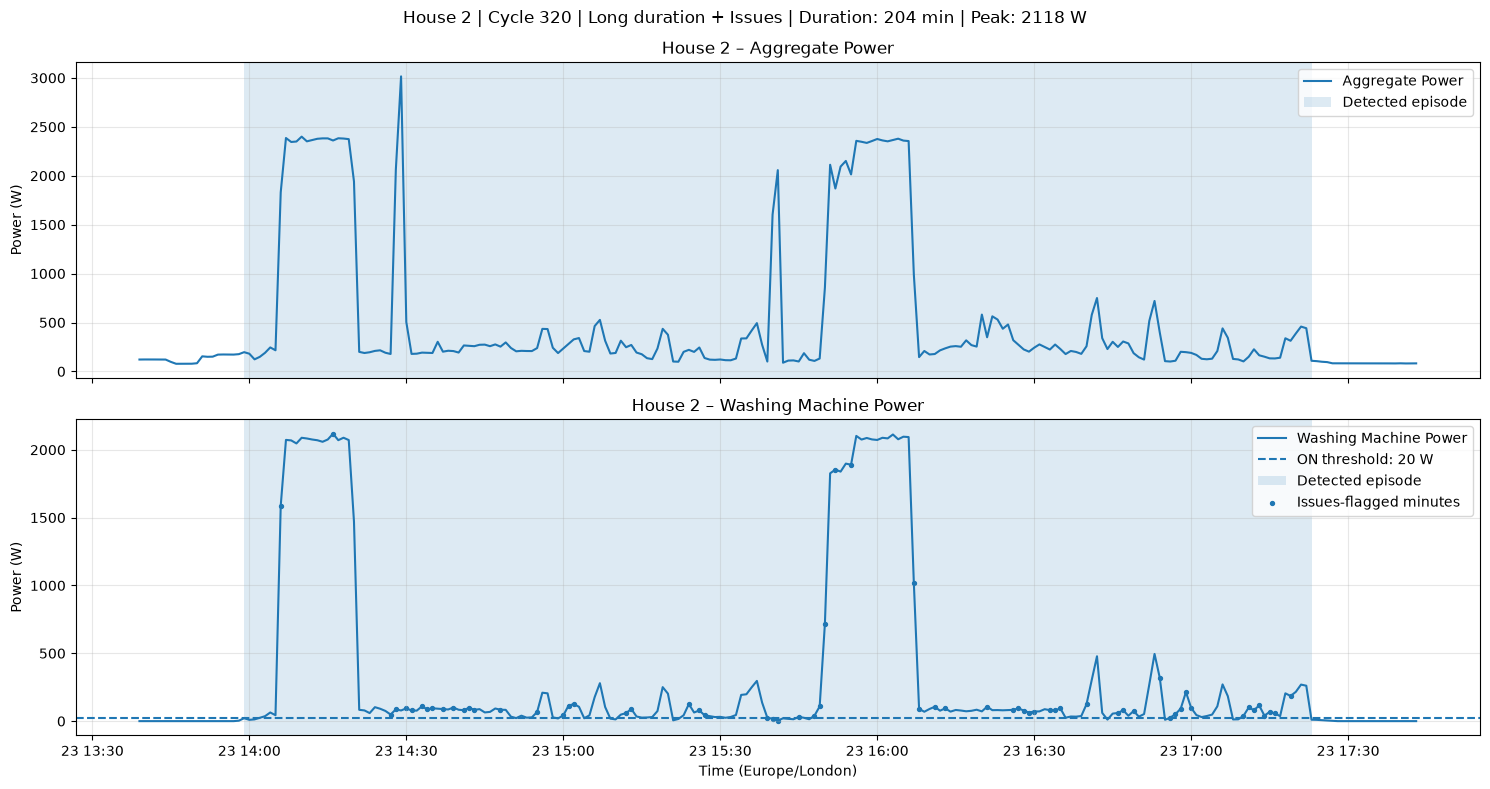


House 2 | Cycle 22 | Low peak + Issues


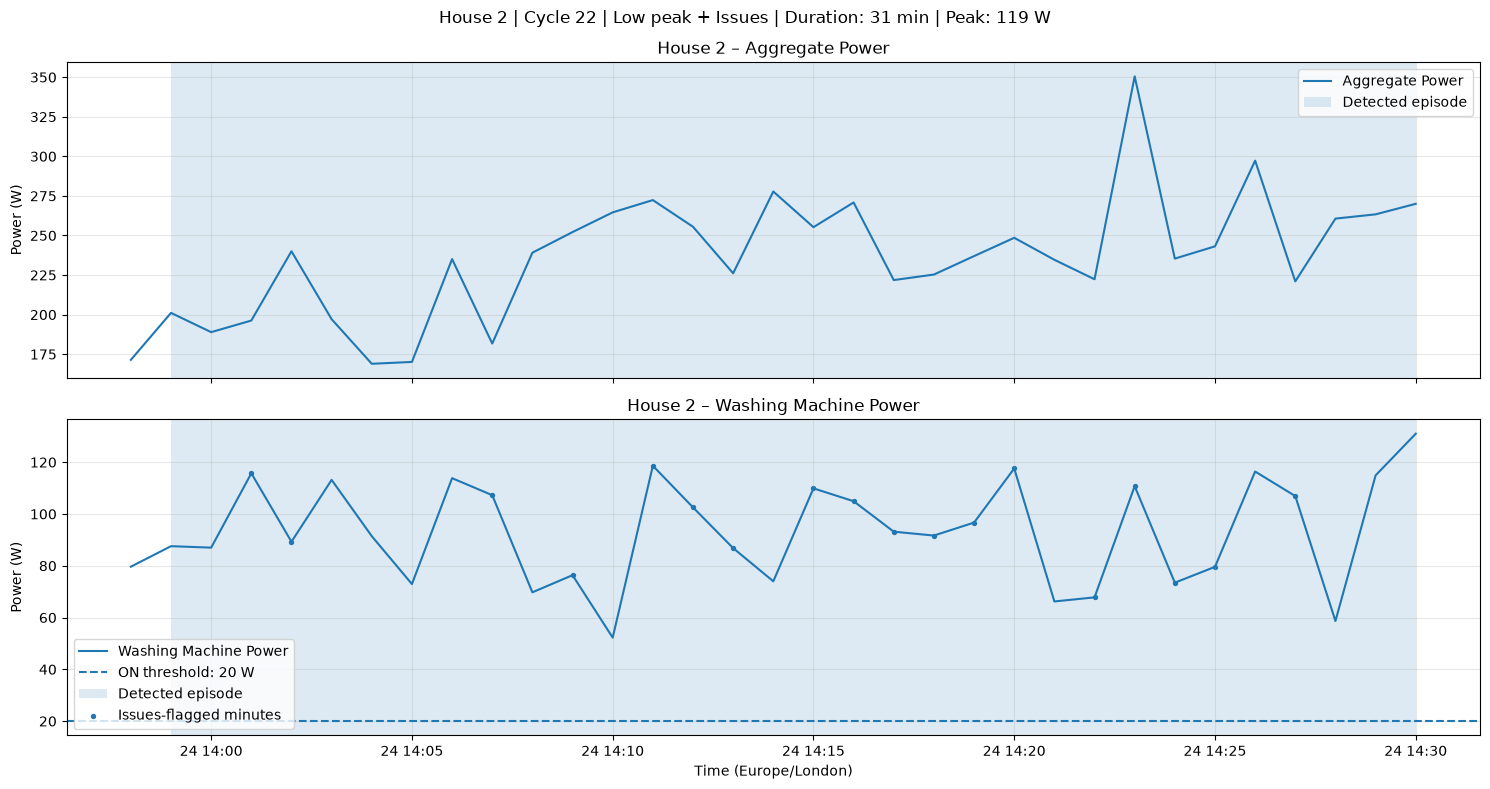


House 6 | Cycle 7 | Long duration


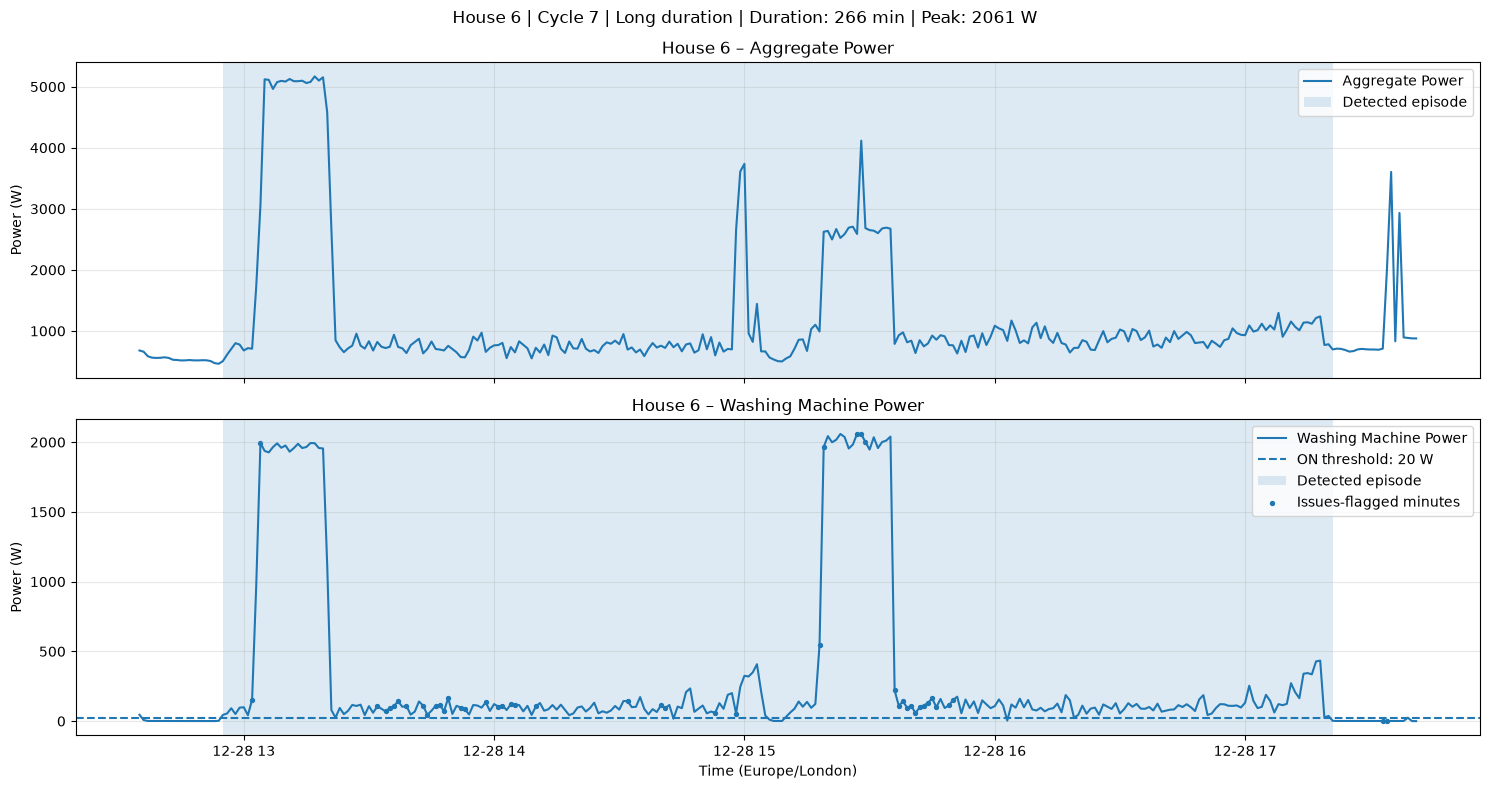


House 6 | Cycle 30 | Long duration


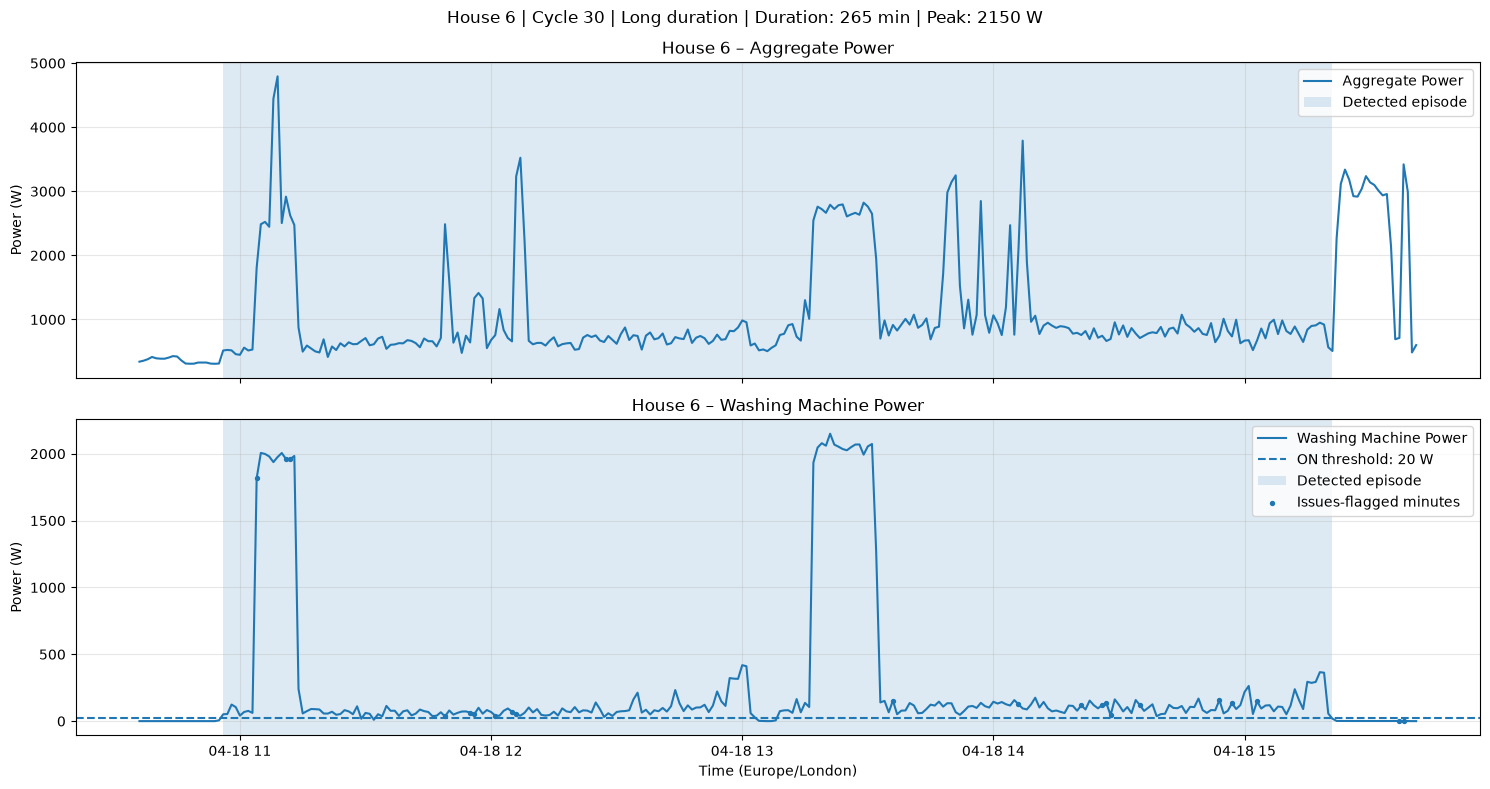


House 7 | Cycle 195 | Long duration + Issues


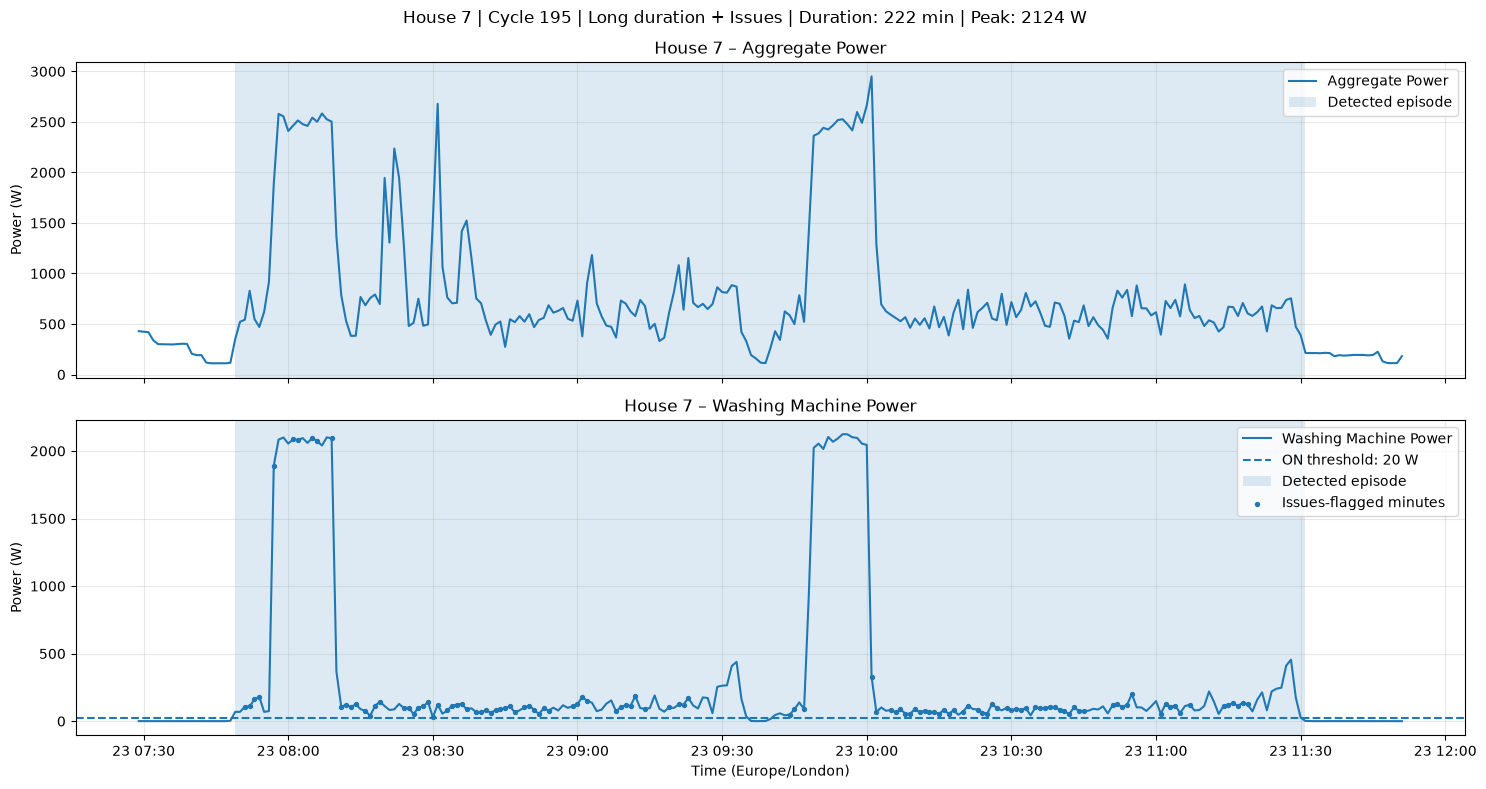


House 7 | Cycle 64 | 100% Issues


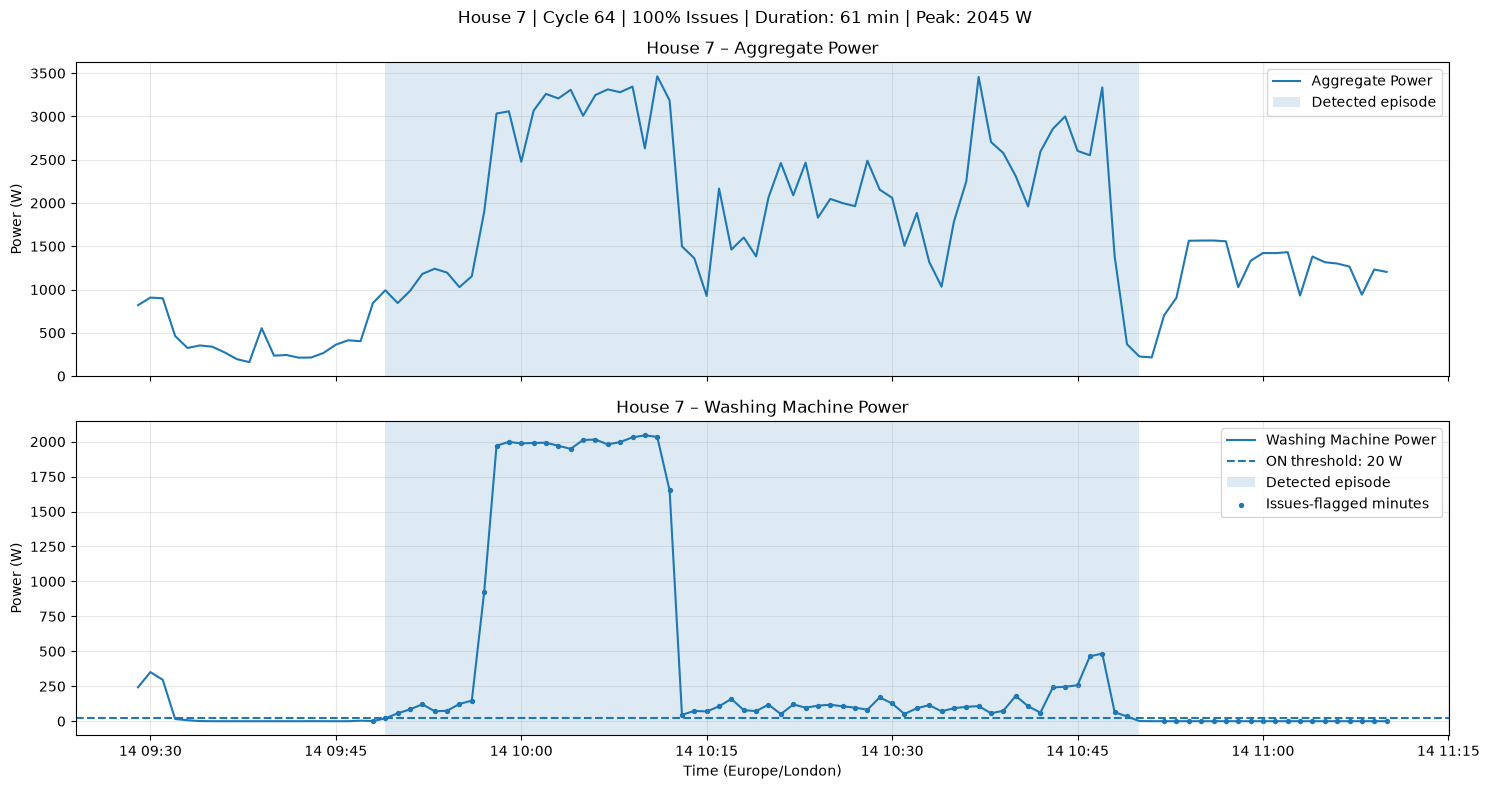


House 7 | Cycle 717 | Long duration, low Issues


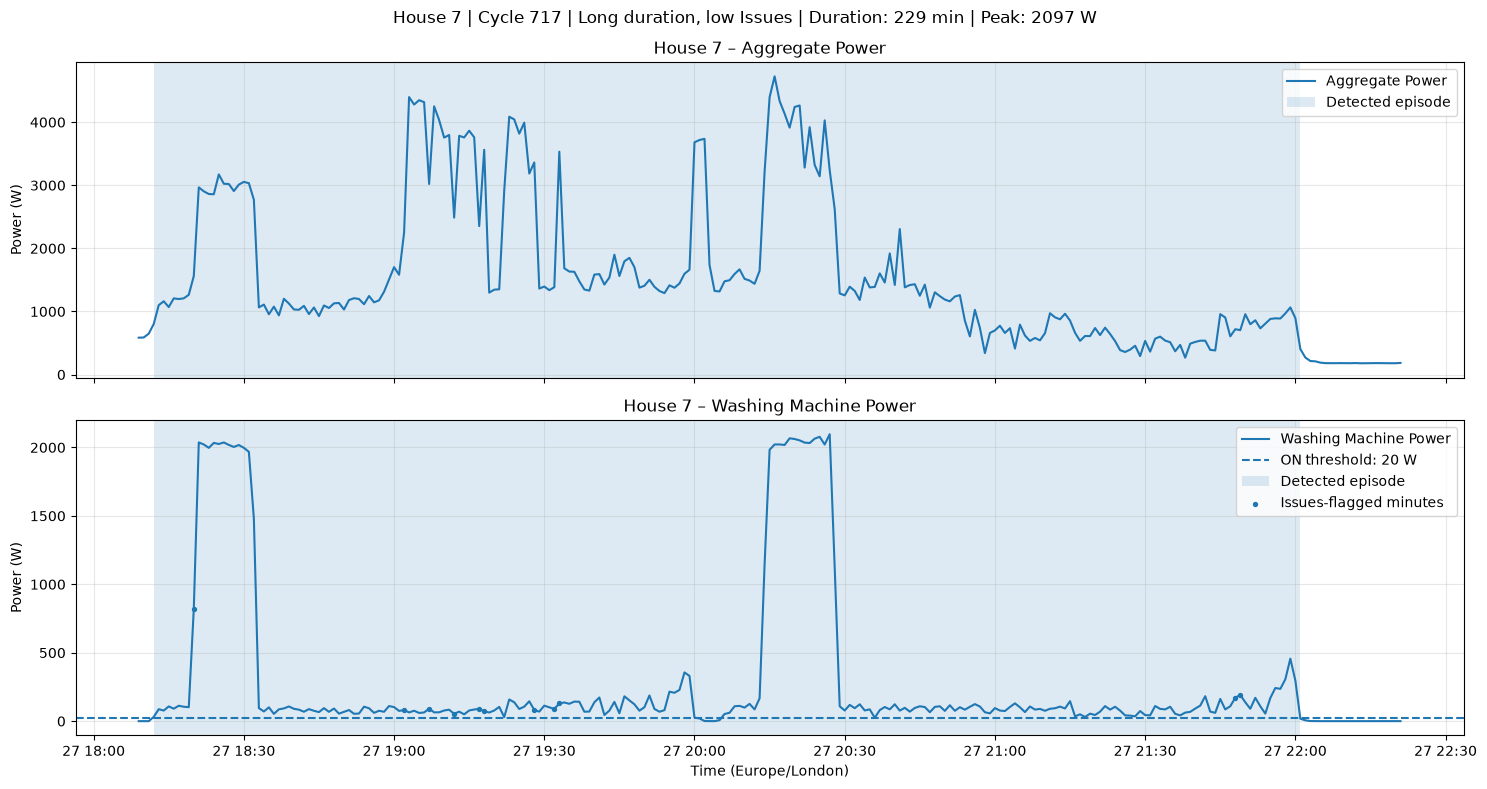

In [62]:
selected_review_events = [

    (1, 117, "Long duration"),
    (1, 210, "100% Issues"),

    (2, 320, "Long duration + Issues"),
    (2, 22, "Low peak + Issues"),

    (6, 7, "Long duration"),
    (6, 30, "Long duration"),

    (7, 195, "Long duration + Issues"),
    (7, 64, "100% Issues"),
    (7, 717, "Long duration, low Issues")

]

for house, cycle_id, reason in selected_review_events:

    print(
        f"\nHouse {house} | "
        f"Cycle {cycle_id} | {reason}"
    )

    plot_detected_episode(
        house=house,
        cycle_id=cycle_id,
        validation_type=reason,
        padding_minutes=20
    )

## Step 13 — Finalize the Activation Rule and Build the Episode Table

### Final Detection Configuration


### Generate the Final Activation Table

**Cell purpose:** Build the final activation table using the selected detection settings, add local timestamps and episode metrics, and save it.

In [63]:
# Final activation table using the frozen configuration

final_episode_tables = []

for house in PRIMARY_HOUSES:

    episodes = duration_episode_store[
        (house, 27)
    ].copy()

    if episodes.empty:
        continue

    episodes["House"] = house

    # Convert timestamps to proper UTC and UK local time
    episodes["Start_UTC"] = pd.to_datetime(
        episodes["Start_UTC"],
        utc=True
    )

    episodes["End_UTC"] = pd.to_datetime(
        episodes["End_UTC"],
        utc=True
    )

    episodes["Start_London"] = (
        episodes["Start_UTC"].dt.tz_convert("Europe/London")
    )

    episodes["End_London"] = (
        episodes["End_UTC"].dt.tz_convert("Europe/London")
    )

    # Additional features
    episodes["Active_Fraction_Pct"] = (
        episodes["Active_Minutes"]
        / episodes["Duration_Min"] * 100
    )

    episodes["Energy_kWh"] = (
        episodes["Energy_Wh"] / 1000
    )

    episodes["Issues_Affected"] = (
        episodes["Issues_Minutes_Pct"] > 0
    )

    # Record detection parameters
    episodes["Threshold_W"] = 20
    episodes["Gap_Tolerance_Min"] = 5
    episodes["Minimum_Duration_Min"] = 27

    final_episode_tables.append(episodes)


# Combine all households
final_activations = pd.concat(
    final_episode_tables,
    ignore_index=True
)

final_activations = final_activations.sort_values(
    ["House", "Start_UTC"]
).reset_index(drop=True)

# Save output
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"

TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

output_file = (
    TABLE_DIR / "detected_activations.csv"
)

final_activations.to_csv(
    output_file,
    index=False
)

print("Final activation table generated.")

print("Total episodes:", len(final_activations))

print("Saved at:", output_file)

display(
    final_activations.head(10).round(2)
)

Final activation table generated.
Total episodes: 1732
Saved at: /Users/rehaanraza/Desktop/assessmentFlock/refit-nilm/outputs/tables/detected_activations.csv


/var/folders/4y/wyg1yj8s6171ybbm1q81x0m00000gn/T/ipykernel_3174/2812166658.py:91: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  final_activations.head(10).round(2)


,Cycle_ID,Start_UTC,End_UTC,Duration_Min,Active_Minutes,Bridged_OFF_Minutes,Mean_Active_Power_W,Peak_Power_W,Energy_Wh,Active_Energy_Wh,...,Issues_Time_Pct,House,Start_London,End_London,Active_Fraction_Pct,Energy_kWh,Issues_Affected,Threshold_W,Gap_Tolerance_Min,Minimum_Duration_Min
0,1,2013-10-23 05:59:00+00:00,2013-10-23 06:33:00+00:00,34,29,5,520.68,2337.00,252.84,251.66,...,5.54,1,2013-10-23 06:59:00+01:00,2013-10-23 07:33:00+01:00,85.29,0.25,True,20,5,27
1,2,2013-10-23 06:40:00+00:00,2013-10-23 07:16:00+00:00,36,32,4,527.57,2374.70,282.33,281.37,...,2.04,1,2013-10-23 07:40:00+01:00,2013-10-23 08:16:00+01:00,88.89,0.28,True,20,5,27
2,3,2013-10-23 13:05:00+00:00,2013-10-23 13:37:00+00:00,32,29,3,572.11,2346.63,277.15,276.52,...,23.07,1,2013-10-23 14:05:00+01:00,2013-10-23 14:37:00+01:00,90.62,0.28,True,20,5,27
3,4,2013-10-23 14:06:00+00:00,2013-10-23 14:40:00+00:00,34,31,3,538.24,2406.48,278.75,278.09,...,19.26,1,2013-10-23 15:06:00+01:00,2013-10-23 15:40:00+01:00,91.18,0.28,True,20,5,27
4,5,2013-10-24 10:11:00+00:00,2013-10-24 10:43:00+00:00,32,29,3,546.76,2377.05,264.90,264.27,...,17.24,1,2013-10-24 11:11:00+01:00,2013-10-24 11:43:00+01:00,90.62,0.26,True,20,5,27
5,6,2013-10-26 11:34:00+00:00,2013-10-26 12:09:00+00:00,35,31,4,553.89,2254.78,287.16,286.18,...,22.14,1,2013-10-26 12:34:00+01:00,2013-10-26 13:09:00+01:00,88.57,0.29,True,20,5,27
6,7,2013-10-27 10:06:00+00:00,2013-10-27 10:38:00+00:00,32,28,4,563.42,2285.95,263.90,262.93,...,22.66,1,2013-10-27 10:06:00+00:00,2013-10-27 10:38:00+00:00,87.50,0.26,True,20,5,27
7,8,2013-10-27 10:45:00+00:00,2013-10-27 11:20:00+00:00,35,32,3,502.31,2380.65,268.53,267.90,...,21.52,1,2013-10-27 10:45:00+00:00,2013-10-27 11:20:00+00:00,91.43,0.27,True,20,5,27
8,9,2013-10-28 13:30:00+00:00,2013-10-28 14:02:00+00:00,32,29,3,557.10,2357.98,269.83,269.27,...,22.14,1,2013-10-28 13:30:00+00:00,2013-10-28 14:02:00+00:00,90.62,0.27,True,20,5,27
9,10,2013-10-29 10:55:00+00:00,2013-10-29 11:36:00+00:00,41,34,7,660.19,2340.92,374.92,374.11,...,22.80,1,2013-10-29 10:55:00+00:00,2013-10-29 11:36:00+00:00,82.93,0.37,True,20,5,27


### Summarize Detected Episodes by Household

**Cell purpose:** Calculate household-level summaries of the final detected activation episodes, including duration and estimated energy.

In [64]:
final_cycle_summary = (
    final_activations
    .groupby("House")
    .agg(

        Total_Episodes=("Cycle_ID", "count"),

        Median_Duration_Min=("Duration_Min", "median"),

        Mean_Duration_Min=("Duration_Min", "mean"),

        Median_Active_Minutes=("Active_Minutes", "median"),

        Median_Peak_Power_W=("Peak_Power_W", "median"),

        Median_Energy_Wh=("Energy_Wh", "median"),

        Mean_Energy_Wh=("Energy_Wh", "mean"),

        Issues_Affected_Episodes_Pct=(
            "Issues_Affected",
            lambda x: x.mean() * 100
        )
    )
    .round(2)
    .reset_index()
)

display(final_cycle_summary)

final_cycle_summary.to_csv(
    TABLE_DIR / "cycle_summary_by_house.csv",
    index=False
)

,House,Total_Episodes,Median_Duration_Min,Mean_Duration_Min,Median_Active_Minutes,Median_Peak_Power_W,Median_Energy_Wh,Mean_Energy_Wh,Issues_Affected_Episodes_Pct
0,1,395,33.0,40.45,31.0,2321.87,312.79,355.95,98.99
1,2,338,96.0,97.60,91.5,2088.90,607.21,587.51,96.75
2,6,121,129.0,105.71,128.0,2049.18,674.99,656.30,97.52
3,7,878,60.0,73.53,60.0,2080.82,529.82,553.08,93.62


## Step 14 — Analyse Temporal Washing-Machine Usage Patterns


### Temporal Analysis and Exposure Normalization

**Cell purpose:** Analyse episode start times by hour and weekday, normalize counts by valid monitoring exposure, and save the temporal plots and tables.

Households available: [1, 2, 6, 7]


/var/folders/4y/wyg1yj8s6171ybbm1q81x0m00000gn/T/ipykernel_3174/4148176947.py:151: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  .groupby(valid_times.dayofweek)
/var/folders/4y/wyg1yj8s6171ybbm1q81x0m00000gn/T/ipykernel_3174/4148176947.py:156: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  event_day = house_events["Start_Local"].dt.dayofweek
/var/folders/4y/wyg1yj8s6171ybbm1q81x0m00000gn/T/ipykernel_3174/4148176947.py:187: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  is_weekend = valid_times.dayofweek >= 5
/var/folders/4y/wyg1yj8s6171ybbm1q81x0m00000gn/T/ipykernel_3174/4148176947.py:193: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  (house_events["

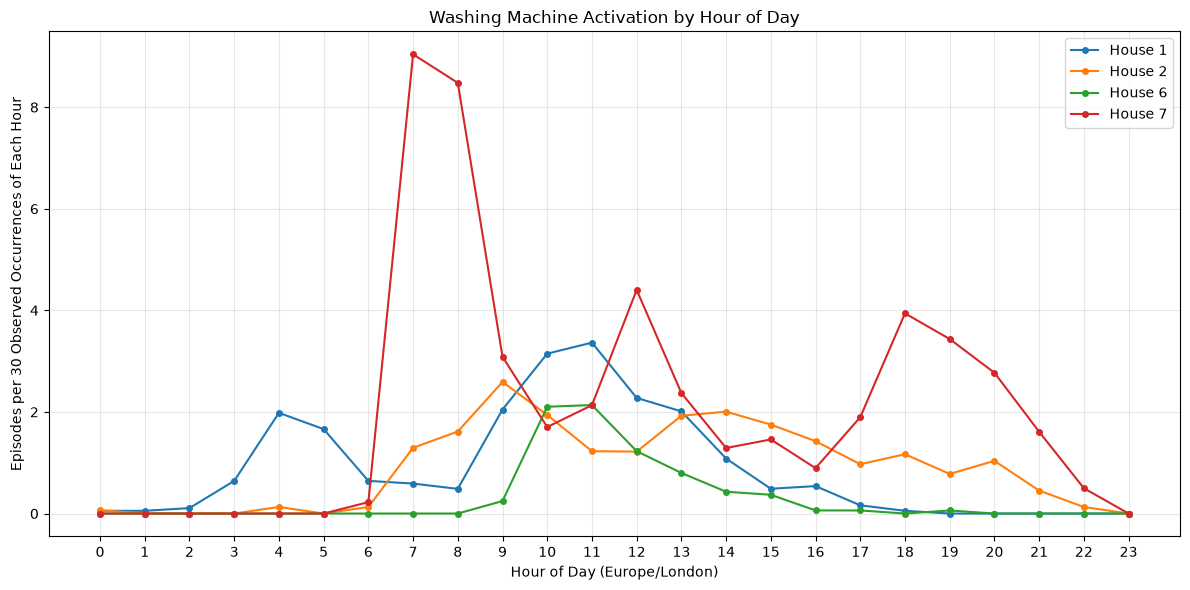

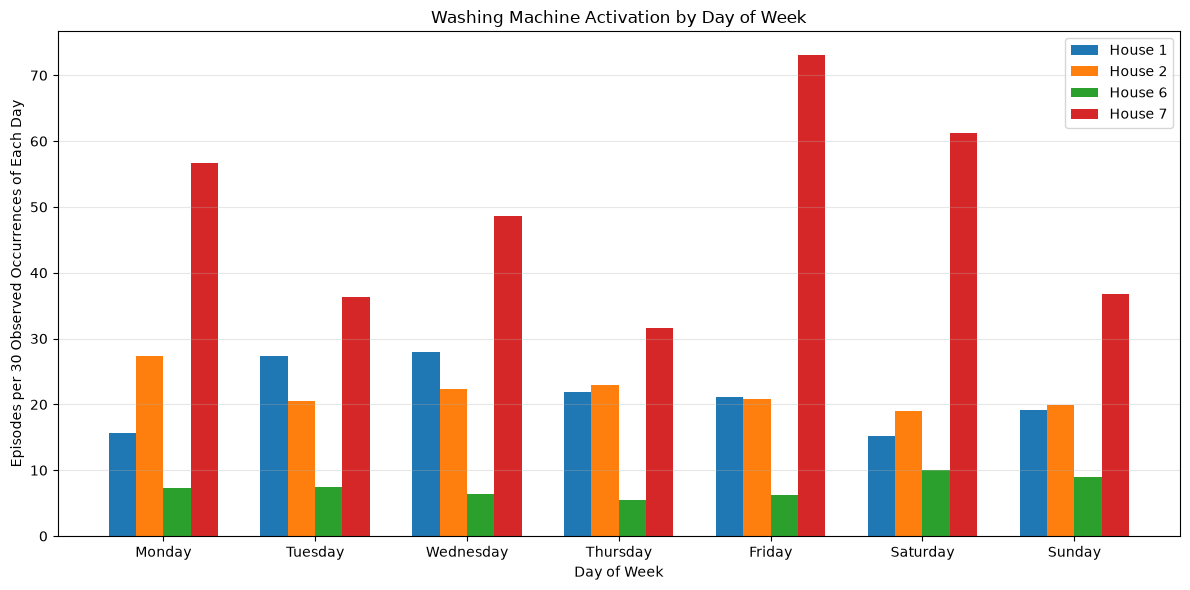

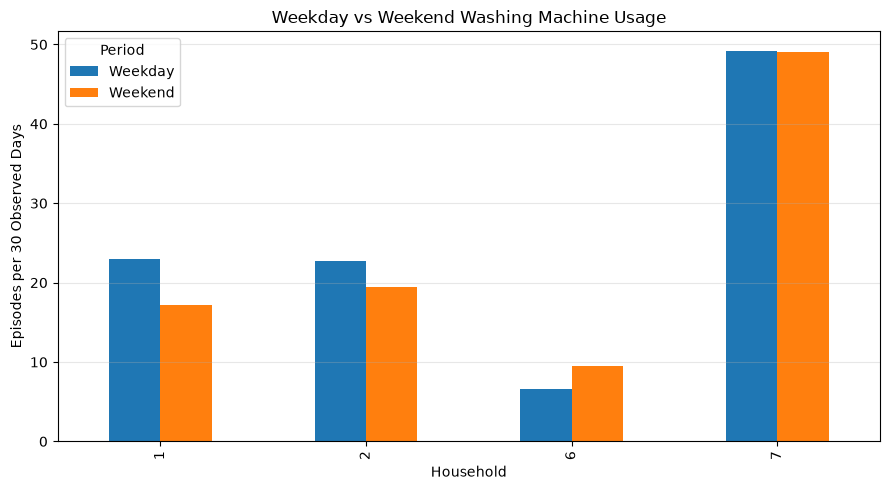

Temporal analysis completed.


In [65]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

FIG_DIR = Path("outputs/figures")
TABLE_DIR = Path("outputs/tables")

FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

HOUSES = [1, 2, 6, 7]
LOCAL_TZ = "Europe/London"

# --------------------------------------------------
# 1. Prepare household data
# --------------------------------------------------

house_frames = {}

for key, frame in analysis_data.items():
    match = re.search(r"\d+", str(key))

    if match:
        house_no = int(match.group())

        if house_no in HOUSES:
            house_frames[house_no] = frame.copy()

print("Households available:", sorted(house_frames.keys()))

# --------------------------------------------------
# 2. Prepare detected activation episodes
# --------------------------------------------------

events = final_activations.copy()

house_col = next(
    col for col in ["House", "House_ID", "House_Number"]
    if col in events.columns
)

start_col = next(
    col for col in ["Start_London", "Start_UTC"]
    if col in events.columns
)

events["House_No"] = (
    events[house_col]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
    .astype(int)
)

# Convert event start times to Europe/London
events["Start_Local"] = pd.to_datetime(
    events[start_col],
    utc=True
).dt.tz_convert(LOCAL_TZ)

events = events[events["House_No"].isin(HOUSES)].copy()

# --------------------------------------------------
# 3. Calculate exposure-normalized hourly usage
# --------------------------------------------------

hourly_rows = []
weekday_rows = []
weekend_rows = []

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

for house_no, df in house_frames.items():

    # Use only complete one-minute WM observations
    wm_col = (
        "Primary_WM_W"
        if "Primary_WM_W" in df.columns
        else "Washing_Machine_W"
    )

    valid = df[wm_col].notna()

    if "observed_seconds" in df.columns:
        valid &= df["observed_seconds"].eq(60)

    # Convert index to local time
    local_index = pd.DatetimeIndex(df.index)

    if local_index.tz is None:
        local_index = local_index.tz_localize("UTC")
    else:
        local_index = local_index.tz_convert("UTC")

    local_index = local_index.tz_convert(LOCAL_TZ)

    valid_times = local_index[valid]

    house_events = events[
        events["House_No"] == house_no
    ].copy()

    # ------------------------------
    # Hour of day
    # ------------------------------

    available_minutes = (
        pd.Series(1, index=valid_times)
        .groupby(valid_times.hour)
        .sum()
        .reindex(range(24), fill_value=0)
    )

    starts_by_hour = (
        house_events["Start_Local"]
        .dt.hour
        .value_counts()
        .reindex(range(24), fill_value=0)
    )

    # Number of equivalent monitored occurrences of each hour
    exposure_hours = available_minutes / 60

    # Episodes per 30 equivalent monitored occurrences
    hourly_rate = np.divide(
        starts_by_hour * 30,
        exposure_hours,
        out=np.zeros(24, dtype=float),
        where=exposure_hours > 0
    )

    for hour in range(24):
        hourly_rows.append({
            "House": house_no,
            "Hour": hour,
            "Episodes": int(starts_by_hour.loc[hour]),
            "Exposure_Hours": exposure_hours.loc[hour],
            "Episodes_per_30_Observed_Hours": hourly_rate[hour]
        })

    # ------------------------------
    # Day of week
    # ------------------------------

    available_by_day = (
        pd.Series(1, index=valid_times)
        .groupby(valid_times.dayofweek)
        .sum()
        .reindex(range(7), fill_value=0)
    )

    event_day = house_events["Start_Local"].dt.dayofweek

    starts_by_day = (
        event_day
        .value_counts()
        .reindex(range(7), fill_value=0)
    )

    # Equivalent fully monitored days for each weekday
    exposure_days = available_by_day / 1440

    weekday_rate = np.divide(
        starts_by_day * 30,
        exposure_days,
        out=np.zeros(7, dtype=float),
        where=exposure_days > 0
    )

    for day in range(7):
        weekday_rows.append({
            "House": house_no,
            "Day": weekday_order[day],
            "Episodes": int(starts_by_day.loc[day]),
            "Exposure_Days": exposure_days.loc[day],
            "Episodes_per_30_Observed_Days": weekday_rate[day]
        })

    # ------------------------------
    # Weekday versus weekend
    # ------------------------------

    is_weekend = valid_times.dayofweek >= 5

    weekend_minutes = int(is_weekend.sum())
    weekday_minutes = int((~is_weekend).sum())

    weekend_events = int(
        (house_events["Start_Local"].dt.dayofweek >= 5).sum()
    )

    weekday_events = int(
        (house_events["Start_Local"].dt.dayofweek < 5).sum()
    )

    weekday_exposure = weekday_minutes / 1440
    weekend_exposure = weekend_minutes / 1440

    weekday_rows_total = np.divide(
        weekday_events * 30,
        weekday_exposure
    ) if weekday_exposure > 0 else np.nan

    weekend_rows_total = np.divide(
        weekend_events * 30,
        weekend_exposure
    ) if weekend_exposure > 0 else np.nan

    weekend_rows.extend([
        {
            "House": house_no,
            "Period": "Weekday",
            "Episodes": weekday_events,
            "Exposure_Days": weekday_exposure,
            "Episodes_per_30_Observed_Days": weekday_rows_total
        },
        {
            "House": house_no,
            "Period": "Weekend",
            "Episodes": weekend_events,
            "Exposure_Days": weekend_exposure,
            "Episodes_per_30_Observed_Days": weekend_rows_total
        }
    ])

# --------------------------------------------------
# 4. Create output tables
# --------------------------------------------------

hourly_df = pd.DataFrame(hourly_rows)
weekday_df = pd.DataFrame(weekday_rows)
weekend_df = pd.DataFrame(weekend_rows)

hourly_df.to_csv(
    TABLE_DIR / "hourly_usage_patterns.csv",
    index=False
)

weekday_df.to_csv(
    TABLE_DIR / "weekday_usage_patterns.csv",
    index=False
)

weekend_df.to_csv(
    TABLE_DIR / "weekday_weekend_comparison.csv",
    index=False
)

# --------------------------------------------------
# 5. Plot hourly usage patterns
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

for house_no in HOUSES:
    subset = hourly_df[hourly_df["House"] == house_no]

    ax.plot(
        subset["Hour"],
        subset["Episodes_per_30_Observed_Hours"],
        marker="o",
        markersize=4,
        label=f"House {house_no}"
    )

ax.set(
    title="Washing Machine Activation by Hour of Day",
    xlabel="Hour of Day (Europe/London)",
    ylabel="Episodes per 30 Observed Occurrences of Each Hour"
)

ax.set_xticks(range(24))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()

plt.savefig(
    FIG_DIR / "hourly_usage_patterns.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 6. Plot weekday usage patterns
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(7)
width = 0.18

for i, house_no in enumerate(HOUSES):

    subset = (
        weekday_df[weekday_df["House"] == house_no]
        .set_index("Day")
        .reindex(weekday_order)
    )

    ax.bar(
        x + (i - 1.5) * width,
        subset["Episodes_per_30_Observed_Days"],
        width=width,
        label=f"House {house_no}"
    )

ax.set(
    title="Washing Machine Activation by Day of Week",
    xlabel="Day of Week",
    ylabel="Episodes per 30 Observed Occurrences of Each Day"
)

ax.set_xticks(x)
ax.set_xticklabels(weekday_order)
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()

plt.savefig(
    FIG_DIR / "weekday_usage_patterns.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 7. Plot weekday vs weekend
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

weekend_pivot = weekend_df.pivot(
    index="House",
    columns="Period",
    values="Episodes_per_30_Observed_Days"
)

weekend_pivot.plot(
    kind="bar",
    ax=ax
)

ax.set(
    title="Weekday vs Weekend Washing Machine Usage",
    xlabel="Household",
    ylabel="Episodes per 30 Observed Days"
)

ax.grid(axis="y", alpha=0.3)
ax.legend(title="Period")
plt.tight_layout()

plt.savefig(
    FIG_DIR / "weekday_vs_weekend_usage.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Temporal analysis completed.")

## Step 15 — Create the Required EDA Visual Deliverables

### Representative 24-Hour Household Trace

**Cell purpose:** Select a representative household-day with strong monitoring coverage and a detected activation, then prepare its 24-hour trace.

Selected household: 2
Selected local date: 2014-10-26
Valid observed minutes: 1500
WM active minutes: 194


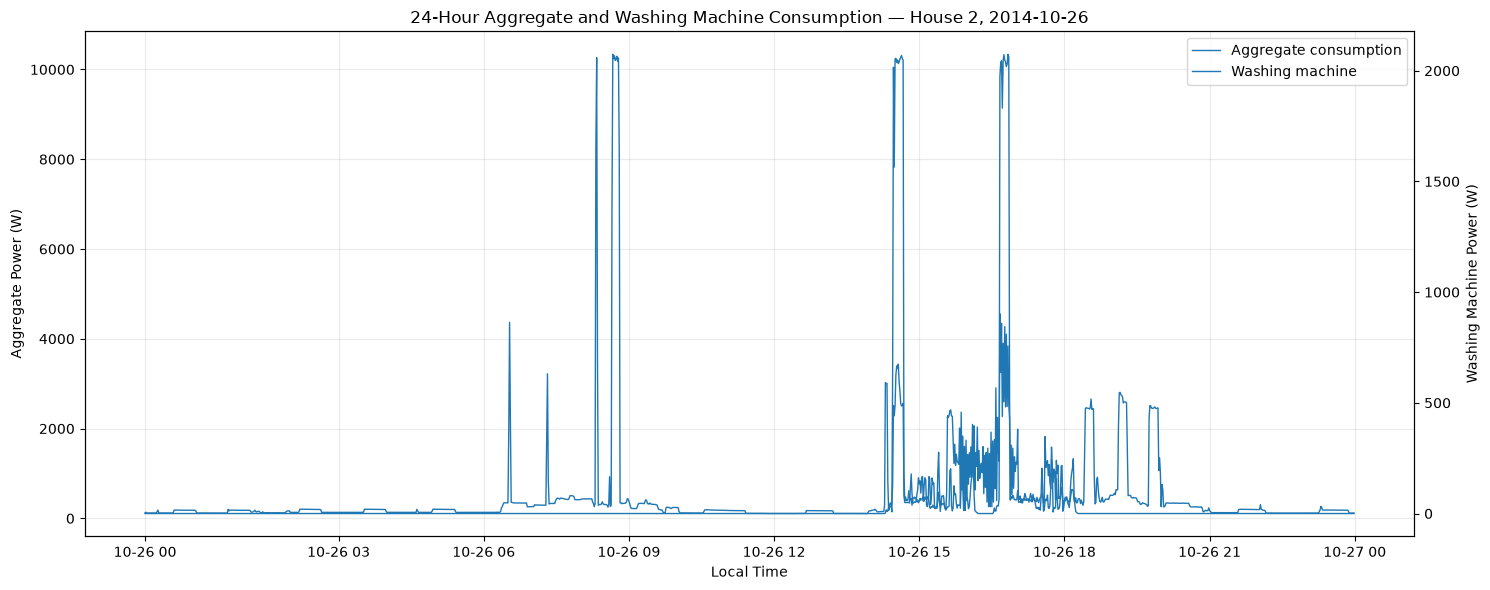

In [66]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

FIG_DIR = Path("outputs/figures")
TABLE_DIR = Path("outputs/tables")

FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

HOUSES = [1, 2, 6, 7]
LOCAL_TZ = "Europe/London"


def get_house_data(house_no):
    for key, frame in analysis_data.items():
        match = re.search(r"\d+", str(key))

        if match and int(match.group()) == house_no:
            return frame.copy()

    raise KeyError(f"House {house_no} not found in analysis_data")


def find_column(df, candidates):
    for col in candidates:
        if col in df.columns:
            return col

    raise KeyError(f"None of these columns found: {candidates}")


# Prepare activation table
events = final_activations.copy()

house_col = find_column(
    events, ["House", "House_ID", "House_Number", "House_No"]
)

start_col = find_column(
    events, ["Start_London", "Start_UTC"]
)

duration_col = find_column(
    events, ["Duration_Minutes", "Duration_Min", "Duration"]
)

events["House_No"] = (
    events[house_col]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
    .astype(int)
)

events["Start_Local"] = pd.to_datetime(
    events[start_col], utc=True
).dt.tz_convert(LOCAL_TZ)

# Search for a suitable 24-hour period
candidates = []

for house_no in HOUSES:

    df = get_house_data(house_no)

    wm_col = find_column(
        df, ["Primary_WM_W", "Washing_Machine_W"]
    )

    aggregate_col = find_column(
        df, ["Primary_Aggregate_W", "Aggregate_W", "Aggregate"]
    )

    local_index = pd.DatetimeIndex(df.index)

    if local_index.tz is None:
        local_index = local_index.tz_localize("UTC")
    else:
        local_index = local_index.tz_convert("UTC")

    local_index = local_index.tz_convert(LOCAL_TZ)

    valid = (
        df[wm_col].notna()
        & df[aggregate_col].notna()
    )

    if "observed_seconds" in df.columns:
        valid &= df["observed_seconds"].eq(60)

    daily = pd.DataFrame({
        "Valid": valid.to_numpy(),
        "WM_Active": (
            valid & (pd.to_numeric(df[wm_col], errors="coerce") > 20)
        ).to_numpy()
    }, index=local_index)

    daily["Local_Date"] = daily.index.date

    daily_summary = daily.groupby("Local_Date").agg(
        Valid_Minutes=("Valid", "sum"),
        Active_Minutes=("WM_Active", "sum")
    )

    house_events = events[events["House_No"] == house_no]

    event_dates = set(house_events["Start_Local"].dt.date)

    daily_summary["Has_Event"] = daily_summary.index.map(
        lambda date: date in event_dates
    )

    daily_summary["House"] = house_no

    candidates.append(daily_summary.reset_index())

candidate_df = pd.concat(candidates, ignore_index=True)

# Prefer a day with an event and high monitoring coverage
candidate_df = candidate_df.sort_values(
    ["Has_Event", "Valid_Minutes", "Active_Minutes"],
    ascending=[False, False, False]
)

selected_day = candidate_df.iloc[0]

selected_house = int(selected_day["House"])
selected_date = selected_day["Local_Date"]

print("Selected household:", selected_house)
print("Selected local date:", selected_date)
print("Valid observed minutes:", int(selected_day["Valid_Minutes"]))
print("WM active minutes:", int(selected_day["Active_Minutes"]))

# Extract the selected day
df = get_house_data(selected_house)

wm_col = find_column(
    df, ["Primary_WM_W", "Washing_Machine_W"]
)

aggregate_col = find_column(
    df, ["Primary_Aggregate_W", "Aggregate_W", "Aggregate"]
)

local_index = pd.DatetimeIndex(df.index)

if local_index.tz is None:
    local_index = local_index.tz_localize("UTC")
else:
    local_index = local_index.tz_convert("UTC")

local_index = local_index.tz_convert(LOCAL_TZ)

valid = (
    df[wm_col].notna()
    & df[aggregate_col].notna()
)

if "observed_seconds" in df.columns:
    valid &= df["observed_seconds"].eq(60)

trace = pd.DataFrame({
    "Aggregate_W": pd.to_numeric(
        df[aggregate_col], errors="coerce"
    ),
    "Washing_Machine_W": pd.to_numeric(
        df[wm_col], errors="coerce"
    )
}, index=local_index)

trace.loc[~valid, :] = np.nan
trace = trace[trace.index.date == selected_date]

# Plot
fig, ax1 = plt.subplots(figsize=(15, 6))

ax1.plot(
    trace.index,
    trace["Aggregate_W"],
    label="Aggregate consumption",
    linewidth=1
)

ax1.set_xlabel("Local Time")
ax1.set_ylabel("Aggregate Power (W)")
ax1.set_title(
    f"24-Hour Aggregate and Washing Machine Consumption "
    f"— House {selected_house}, {selected_date}"
)

ax2 = ax1.twinx()

ax2.plot(
    trace.index,
    trace["Washing_Machine_W"],
    label="Washing machine",
    linewidth=1
)

ax2.set_ylabel("Washing Machine Power (W)")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")
ax1.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "representative_24h_trace.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

### Produce a Representative Detected-Activation Plot

**Cell purpose:** Plot one representative detected activation episode with aggregate context and the selected 20 W threshold.

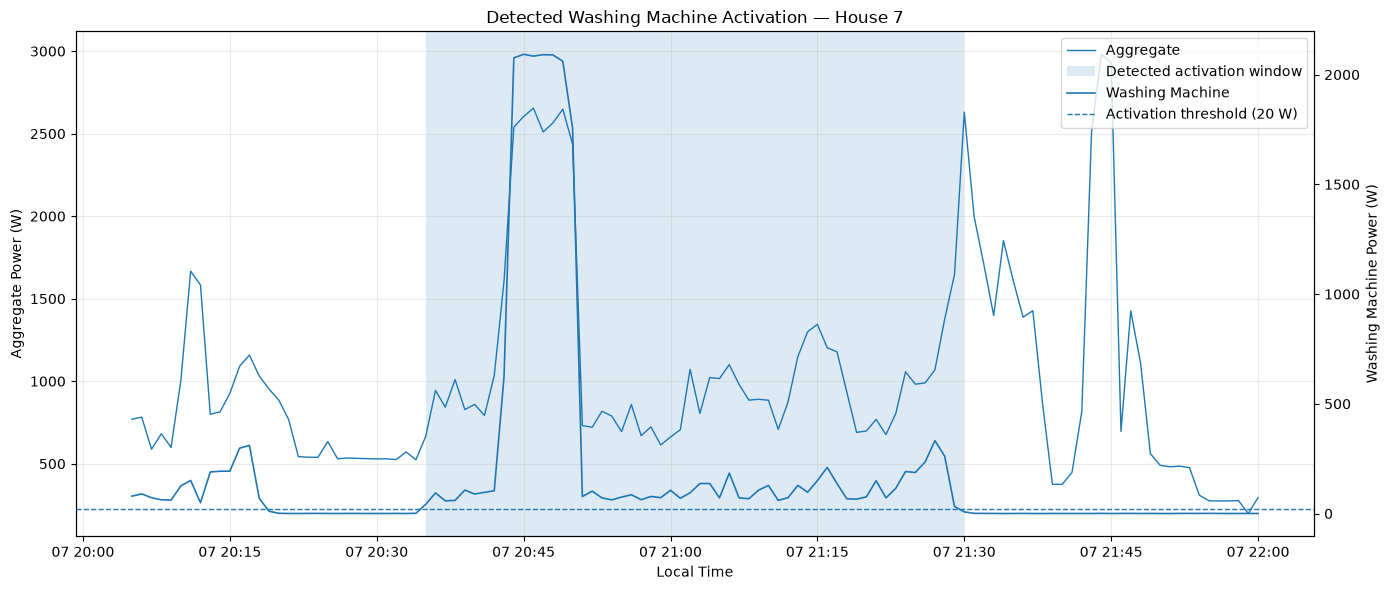

House: 7
Start: 2015-07-07 20:35:00+01:00
End: 2015-07-07 21:30:00+01:00
Duration: 55.0 minutes


In [67]:
# Select a relatively clean activation episode
episode_candidates = events[
    events["Duration_Minutes" if "Duration_Minutes" in events.columns
           else duration_col].between(27, 180)
].copy()

issue_col = next(
    (c for c in ["Issues_Minutes_Pct", "Issues_Time_Pct"]
     if c in episode_candidates.columns),
    None
)

if issue_col is not None and not episode_candidates.empty:
    selected_event = episode_candidates.sort_values(issue_col).iloc[0]
else:
    selected_event = episode_candidates.iloc[0]

selected_house = int(selected_event["House_No"])
start = selected_event["Start_Local"]

duration = float(selected_event[duration_col])
end = start + pd.Timedelta(minutes=duration)

df = get_house_data(selected_house)

wm_col = find_column(
    df, ["Primary_WM_W", "Washing_Machine_W"]
)

aggregate_col = find_column(
    df, ["Primary_Aggregate_W", "Aggregate_W", "Aggregate"]
)

local_index = pd.DatetimeIndex(df.index)

if local_index.tz is None:
    local_index = local_index.tz_localize("UTC")
else:
    local_index = local_index.tz_convert("UTC")

local_index = local_index.tz_convert(LOCAL_TZ)

trace = pd.DataFrame({
    "Aggregate_W": pd.to_numeric(
        df[aggregate_col], errors="coerce"
    ),
    "Washing_Machine_W": pd.to_numeric(
        df[wm_col], errors="coerce"
    )
}, index=local_index)

valid = trace["Washing_Machine_W"].notna() & trace["Aggregate_W"].notna()

if "observed_seconds" in df.columns:
    valid &= df["observed_seconds"].eq(60)

trace.loc[~valid, :] = np.nan

window_start = start - pd.Timedelta(minutes=30)
window_end = end + pd.Timedelta(minutes=30)

episode_trace = trace.loc[
    (trace.index >= window_start)
    & (trace.index <= window_end)
]

fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.plot(
    episode_trace.index,
    episode_trace["Aggregate_W"],
    label="Aggregate",
    linewidth=1
)

ax2 = ax1.twinx()

ax2.plot(
    episode_trace.index,
    episode_trace["Washing_Machine_W"],
    label="Washing Machine",
    linewidth=1.2
)

ax2.axhline(
    20,
    linestyle="--",
    linewidth=1,
    label="Activation threshold (20 W)"
)

ax1.axvspan(
    start,
    end,
    alpha=0.15,
    label="Detected activation window"
)

ax1.set_title(
    f"Detected Washing Machine Activation — House {selected_house}"
)

ax1.set_xlabel("Local Time")
ax1.set_ylabel("Aggregate Power (W)")
ax2.set_ylabel("Washing Machine Power (W)")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")
ax1.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "representative_activation_episode.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("House:", selected_house)
print("Start:", start)
print("End:", end)
print("Duration:", duration, "minutes")

### Compare Activation Duration and Estimated Energy Across Households

**Cell purpose:** Compare activation duration and estimated episode energy across the four households and save the comparison plots and table.

,House_No,Number_of_Episodes,Median_Duration_Min,Mean_Duration_Min,P25_Duration_Min,P75_Duration_Min,Median_Energy_Wh,Mean_Energy_Wh,Median_Peak_Power_W
0,1,395,33.0,40.453165,32.0,35.0,312.793889,355.951716,2321.866667
1,2,338,96.0,97.600592,88.0,104.0,607.205694,587.510659,2088.900000
2,6,121,129.0,105.710744,75.0,132.0,674.994167,656.299901,2049.183333
3,7,878,60.0,73.533030,57.0,103.0,529.816806,553.082960,2080.825000


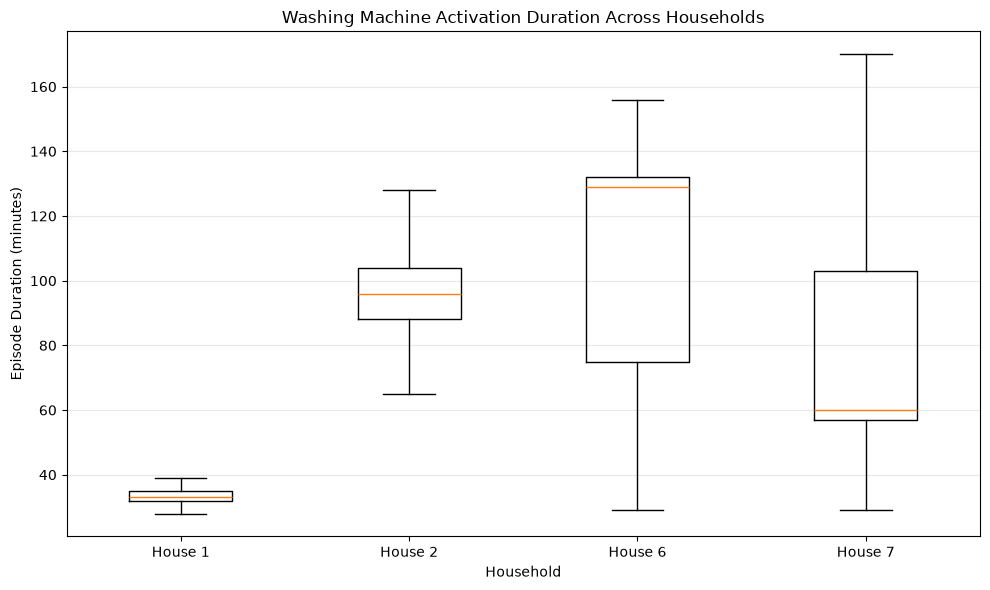

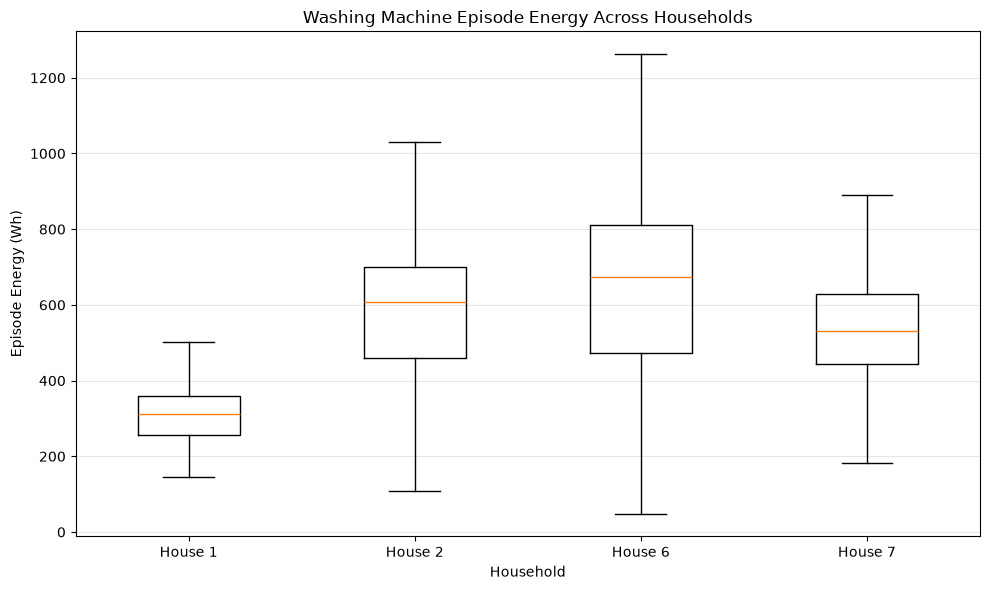

In [69]:
# Prepare comparison data
comparison = events.copy()

comparison["Duration_Minutes"] = pd.to_numeric(
    comparison[duration_col], errors="coerce"
)

energy_col = find_column(
    comparison, ["Energy_Wh", "Total_Energy_Wh"]
)

peak_col = find_column(
    comparison, ["Peak_Power_W", "Peak_W"]
)

comparison["Energy_Wh"] = pd.to_numeric(
    comparison[energy_col], errors="coerce"
)

comparison["Peak_Power_W"] = pd.to_numeric(
    comparison[peak_col], errors="coerce"
)

comparison = comparison[
    comparison["House_No"].isin(HOUSES)
]

# Summary table
cycle_summary = comparison.groupby("House_No").agg(
    Number_of_Episodes=("Duration_Minutes", "count"),
    Median_Duration_Min=("Duration_Minutes", "median"),
    Mean_Duration_Min=("Duration_Minutes", "mean"),
    P25_Duration_Min=("Duration_Minutes", lambda x: x.quantile(0.25)),
    P75_Duration_Min=("Duration_Minutes", lambda x: x.quantile(0.75)),
    Median_Energy_Wh=("Energy_Wh", "median"),
    Mean_Energy_Wh=("Energy_Wh", "mean"),
    Median_Peak_Power_W=("Peak_Power_W", "median")
).reset_index()

cycle_summary.to_csv(
    TABLE_DIR / "cross_house_cycle_summary.csv",
    index=False
)

display(cycle_summary)

# Duration comparison
duration_data = [
    comparison.loc[
        comparison["House_No"] == h,
        "Duration_Minutes"
    ].dropna()
    for h in HOUSES
]

fig, ax = plt.subplots(figsize=(10, 6))

ax.boxplot(
    duration_data,
    tick_labels=[f"House {h}" for h in HOUSES],
    showfliers=False
)

ax.set_title("Washing Machine Activation Duration Across Households")
ax.set_ylabel("Episode Duration (minutes)")
ax.set_xlabel("Household")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "cross_house_duration_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Energy comparison
energy_data = [
    comparison.loc[
        comparison["House_No"] == h,
        "Energy_Wh"
    ].dropna()
    for h in HOUSES
]

fig, ax = plt.subplots(figsize=(10, 6))

ax.boxplot(
    energy_data,
    tick_labels=[f"House {h}" for h in HOUSES],
    showfliers=False
)

ax.set_title("Washing Machine Episode Energy Across Households")
ax.set_ylabel("Episode Energy (Wh)")
ax.set_xlabel("Household")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "cross_house_energy_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

**Cell purpose:** Check that the required figures and principal CSV result tables have been written to the expected output folders.

In [70]:
from pathlib import Path

required_outputs = [
    "outputs/figures/hourly_usage_patterns.png",
    "outputs/figures/weekday_usage_patterns.png",
    "outputs/figures/weekday_vs_weekend_usage.png",
    "outputs/figures/representative_24h_trace.png",
    "outputs/figures/representative_activation_episode.png",
    "outputs/figures/cross_house_duration_comparison.png",
    "outputs/figures/cross_house_energy_comparison.png",
    "outputs/tables/cross_house_cycle_summary.csv",
    "outputs/tables/detected_activations.csv",
]

for file in required_outputs:
    status = "FOUND" if Path(file).exists() else "MISSING"
    print(f"{status}: {file}")

FOUND: outputs/figures/hourly_usage_patterns.png
FOUND: outputs/figures/weekday_usage_patterns.png
FOUND: outputs/figures/weekday_vs_weekend_usage.png
FOUND: outputs/figures/representative_24h_trace.png
FOUND: outputs/figures/representative_activation_episode.png
FOUND: outputs/figures/cross_house_duration_comparison.png
FOUND: outputs/figures/cross_house_energy_comparison.png
FOUND: outputs/tables/cross_house_cycle_summary.csv
MISSING: outputs/tables/detected_activations.csv


### Verify the Representative-Day Coverage and Duration

**Cell purpose:** Verify the selected representative day's expected local-calendar duration and count its valid complete minutes.

In [71]:
# Check B: Verify the representative 24-hour trace

import pandas as pd
import numpy as np

LOCAL_TZ = "Europe/London"

# Fetch the selected household data
df = get_house_data(selected_house)

wm_col = find_column(
    df, ["Primary_WM_W", "Washing_Machine_W"]
)

aggregate_col = find_column(
    df, ["Primary_Aggregate_W", "Aggregate_W", "Aggregate"]
)

# Convert index to London local time
local_index = pd.DatetimeIndex(df.index)

if local_index.tz is None:
    local_index = local_index.tz_localize("UTC")
else:
    local_index = local_index.tz_convert("UTC")

local_index = local_index.tz_convert(LOCAL_TZ)

df = df.copy()
df.index = local_index
df = df[~df.index.duplicated(keep="first")].sort_index()

# Define complete local calendar day
day_start = pd.Timestamp(selected_date).tz_localize(LOCAL_TZ)

day_end = (
    pd.Timestamp(selected_date) + pd.Timedelta(days=1)
).tz_localize(LOCAL_TZ)

# Expected one-minute timestamps for the day
expected_index = pd.date_range(
    start=day_start,
    end=day_end,
    freq="min",
    inclusive="left"
)

# Extract the selected day
day = df.loc[
    (df.index >= day_start) & (df.index < day_end)
].copy()

# Reindex to include missing minutes
day = day.reindex(expected_index)

# Check valid aggregate and washing-machine readings
valid = (
    day[wm_col].notna()
    & day[aggregate_col].notna()
)

if "observed_seconds" in day.columns:
    valid &= day["observed_seconds"].eq(60)

expected_minutes = len(expected_index)
valid_minutes = int(valid.sum())
missing_minutes = expected_minutes - valid_minutes

coverage = (
    valid_minutes / expected_minutes * 100
    if expected_minutes else 0
)

print("House:", selected_house)
print("Selected date:", selected_date)
print("Day starts:", day_start)
print("Day ends:", day_end)

print("\nExpected minutes:", expected_minutes)
print("Valid minutes:", valid_minutes)
print("Missing/invalid minutes:", missing_minutes)
print(f"Data coverage: {coverage:.2f}%")

House: 7
Selected date: 2014-10-26
Day starts: 2014-10-26 00:00:00+01:00
Day ends: 2014-10-27 00:00:00+00:00

Expected minutes: 1500
Valid minutes: 1500
Missing/invalid minutes: 0
Data coverage: 100.00%


### Plot the Full Local Calendar Day

**Cell purpose:** Plot the selected local calendar day on its full-day time axis while leaving unavailable observations as gaps.

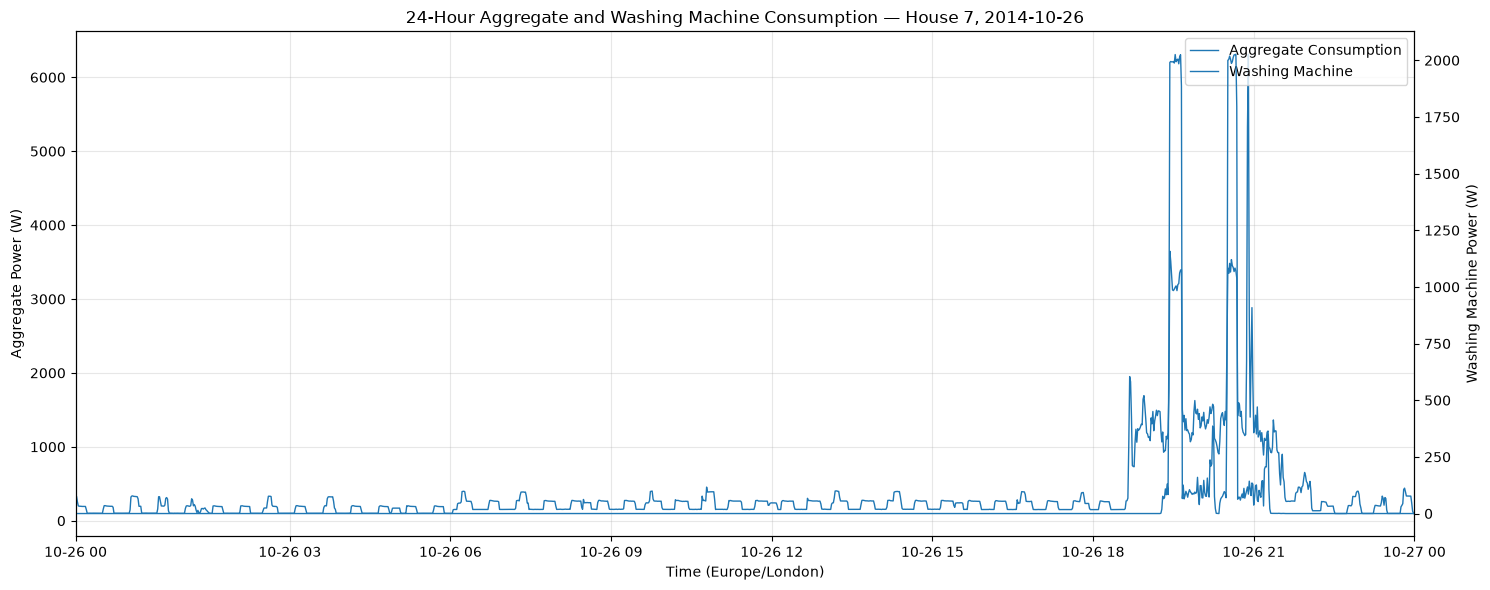

In [72]:
# Prepare full-day plotting data

plot_data = pd.DataFrame(index=expected_index)

plot_data["Aggregate_W"] = pd.to_numeric(
    day[aggregate_col], errors="coerce"
)

plot_data["Washing_Machine_W"] = pd.to_numeric(
    day[wm_col], errors="coerce"
)

plot_valid = (
    plot_data["Aggregate_W"].notna()
    & plot_data["Washing_Machine_W"].notna()
)

if "observed_seconds" in day.columns:
    plot_valid &= day["observed_seconds"].eq(60)

plot_data.loc[~plot_valid, :] = np.nan

# Plot complete calendar day
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(15, 6))

ax1.plot(
    plot_data.index,
    plot_data["Aggregate_W"],
    label="Aggregate Consumption",
    linewidth=1
)

ax2 = ax1.twinx()

ax2.plot(
    plot_data.index,
    plot_data["Washing_Machine_W"],
    label="Washing Machine",
    linewidth=1
)

ax1.set_xlim(day_start, day_end)

ax1.set_title(
    f"24-Hour Aggregate and Washing Machine Consumption "
    f"— House {selected_house}, {selected_date}"
)

ax1.set_xlabel("Time (Europe/London)")
ax1.set_ylabel("Aggregate Power (W)")
ax2.set_ylabel("Washing Machine Power (W)")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper right"
)

ax1.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "outputs/figures/representative_24h_trace.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

**Cell purpose:** Choose a normal 1,440-minute local day, excluding daylight-saving transition dates, for the representative 24-hour figure.

In [73]:
# Select a normal 24-hour day (exclude DST transition days)

candidate_df = candidate_df.copy()

def get_expected_minutes(date):
    start = pd.Timestamp(date).tz_localize("Europe/London")
    end = (
        pd.Timestamp(date) + pd.Timedelta(days=1)
    ).tz_localize("Europe/London")

    return len(pd.date_range(
        start=start,
        end=end,
        freq="min",
        inclusive="left"
    ))

candidate_df["Expected_Minutes"] = (
    candidate_df["Local_Date"].apply(get_expected_minutes)
)

# Keep only normal 24-hour days
normal_days = candidate_df[
    candidate_df["Expected_Minutes"] == 1440
].copy()

if normal_days.empty:
    raise ValueError("No normal 24-hour day found.")

normal_days = normal_days.sort_values(
    ["Valid_Minutes", "Has_Event", "Active_Minutes"],
    ascending=False
)

selected_day = normal_days.iloc[0]

selected_house = int(selected_day["House"])
selected_date = selected_day["Local_Date"]

print("Selected House:", selected_house)
print("Selected Date:", selected_date)
print("Expected Minutes:", selected_day["Expected_Minutes"])
print("Valid Minutes:", selected_day["Valid_Minutes"])
print("Coverage:",
      round(selected_day["Valid_Minutes"] / 1440 * 100, 2), "%")

Selected House: 7
Selected Date: 2014-10-17
Expected Minutes: 1440
Valid Minutes: 1440
Coverage: 100.0 %


**Cell purpose:** Regenerate and save the representative trace for the selected normal 24-hour day.

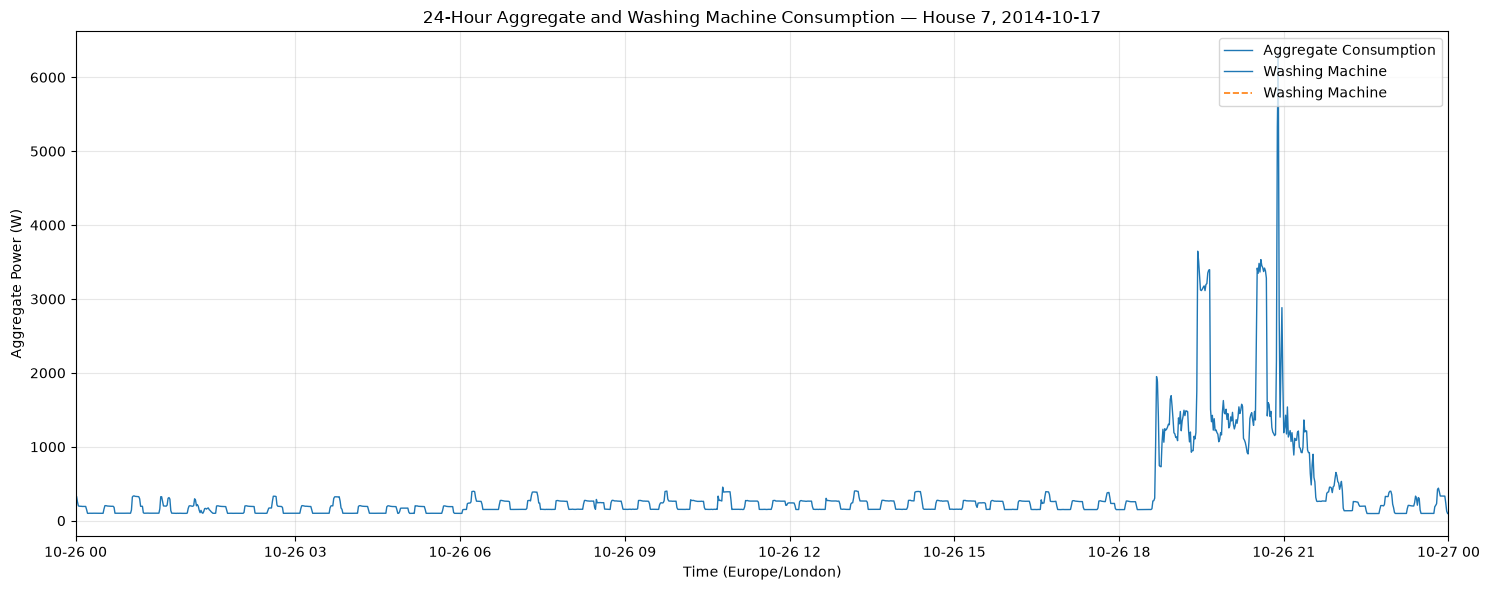

In [74]:
# Prepare full-day plotting data

plot_data = pd.DataFrame(index=expected_index)

plot_data["Aggregate_W"] = pd.to_numeric(
    day[aggregate_col], errors="coerce"
)

plot_data["Washing_Machine_W"] = pd.to_numeric(
    day[wm_col], errors="coerce"
)

plot_valid = (
    plot_data["Aggregate_W"].notna()
    & plot_data["Washing_Machine_W"].notna()
)

if "observed_seconds" in day.columns:
    plot_valid &= day["observed_seconds"].eq(60)

plot_data.loc[~plot_valid, :] = np.nan

# Plot complete calendar day
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(15, 6))

# Aggregate line
ax1.plot(
    plot_data.index,
    plot_data["Aggregate_W"],
    label="Aggregate Consumption",
    linewidth=1,
    linestyle="-"
)

# Washing-machine line
ax2.plot(
    plot_data.index,
    plot_data["Washing_Machine_W"],
    label="Washing Machine",
    linewidth=1.2,
    linestyle="--"
)

ax1.set_xlim(day_start, day_end)

ax1.set_title(
    f"24-Hour Aggregate and Washing Machine Consumption "
    f"— House {selected_house}, {selected_date}"
)

ax1.set_xlabel("Time (Europe/London)")
ax1.set_ylabel("Aggregate Power (W)")
ax2.set_ylabel("Washing Machine Power (W)")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper right"
)

ax1.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "outputs/figures/representative_24h_trace.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

### Save the Final Detected-Activation CSV

**Cell purpose:** Save the final detected activation table as a standalone CSV and confirm that the file exists.

In [75]:
from pathlib import Path

table_dir = Path("outputs/tables")
table_dir.mkdir(parents=True, exist_ok=True)

output_file = table_dir / "detected_activations.csv"

final_activations.to_csv(output_file, index=False)

print("Saved:", output_file)
print("Total detected episodes:", len(final_activations))
print("File exists:", output_file.exists())

Saved: outputs/tables/detected_activations.csv
Total detected episodes: 1732
File exists: True


## Step 16 — Consolidate and Verify Final EDA Outputs


### Final Output Consolidation and Reproducibility Checks


### Build the Consolidated EDA Summary Tables

**Cell purpose:** Build consolidated data-quality, episode and temporal summary tables and export them for reporting.

In [77]:

import numpy as np
import re
from pathlib import Path

HOUSES = [1, 2, 6, 7]

OUTPUT_DIR = Path("outputs/tables")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def get_house_frame(house_no):
    for key, frame in analysis_data.items():
        match = re.search(r"\d+", str(key))

        if match and int(match.group()) == house_no:
            return frame.copy()

    raise KeyError(f"House {house_no} not found")


# ------------------------------------------------
# A. Household data-quality summary
# ------------------------------------------------

quality_rows = []

for house_no in HOUSES:

    df = get_house_frame(house_no)

    wm_col = (
        "Primary_WM_W"
        if "Primary_WM_W" in df.columns
        else "Washing_Machine_W"
    )

    wm = pd.to_numeric(df[wm_col], errors="coerce")

    valid = wm.notna()

    if "observed_seconds" in df.columns:
        valid &= df["observed_seconds"].eq(60)

    valid_count = int(valid.sum())
    total_bins = len(df)

    zero_pct = (
        (wm[valid] == 0).mean() * 100
        if valid_count else np.nan
    )

    below_threshold_pct = (
        (wm[valid] <= 20).mean() * 100
        if valid_count else np.nan
    )

    active_pct = (
        (wm[valid] > 20).mean() * 100
        if valid_count else np.nan
    )

    if "Issues_Flag" in df.columns:
        issues = df["Issues_Flag"].fillna(False).astype(bool)
        issues_pct = (
            issues[valid].mean() * 100
            if valid_count else np.nan
        )

    elif "Issues_Time_Pct" in df.columns:
        issues_pct = (
            (df.loc[valid, "Issues_Time_Pct"] > 0).mean() * 100
            if valid_count else np.nan
        )

    else:
        issues_pct = np.nan

    quality_rows.append({
        "House": house_no,
        "Total_1min_Bins": total_bins,
        "Valid_Complete_Minutes": valid_count,
        "Invalid_or_Missing_Minutes": total_bins - valid_count,
        "Coverage_Pct": (
            valid_count / total_bins * 100
            if total_bins else np.nan
        ),
        "Zero_Power_Pct": zero_pct,
        "At_or_Below_20W_Pct": below_threshold_pct,
        "Above_20W_Pct": active_pct,
        "Issues_Affected_Minutes_Pct": issues_pct
    })

quality_summary = pd.DataFrame(quality_rows)

quality_summary.to_csv(
    OUTPUT_DIR / "final_data_quality_summary.csv",
    index=False
)


# ------------------------------------------------
# B. Activation episode summary
# ------------------------------------------------

episode_data = final_activations.copy()

house_col = next(
    c for c in ["House", "House_ID", "House_Number", "House_No"]
    if c in episode_data.columns
)

duration_col = next(
    c for c in ["Duration_Minutes", "Duration_Min", "Duration"]
    if c in episode_data.columns
)

episode_data["House_No"] = (
    episode_data[house_col]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
    .astype(int)
)

episode_data["Duration_Minutes"] = pd.to_numeric(
    episode_data[duration_col],
    errors="coerce"
)

summary_aggregations = {
    "Detected_Episodes": ("Duration_Minutes", "count"),
    "Median_Duration_Min": ("Duration_Minutes", "median"),
    "Mean_Duration_Min": ("Duration_Minutes", "mean"),
    "P90_Duration_Min": (
        "Duration_Minutes",
        lambda x: x.quantile(0.90)
    )
}

if "Energy_Wh" in episode_data.columns:
    episode_data["Energy_Wh"] = pd.to_numeric(
        episode_data["Energy_Wh"],
        errors="coerce"
    )
    summary_aggregations["Median_Energy_Wh"] = (
        "Energy_Wh", "median"
    )

if "Peak_Power_W" in episode_data.columns:
    episode_data["Peak_Power_W"] = pd.to_numeric(
        episode_data["Peak_Power_W"],
        errors="coerce"
    )
    summary_aggregations["Median_Peak_Power_W"] = (
        "Peak_Power_W", "median"
    )

episode_summary = (
    episode_data[episode_data["House_No"].isin(HOUSES)]
    .groupby("House_No")
    .agg(**summary_aggregations)
    .reset_index()
    .rename(columns={"House_No": "House"})
)

episode_summary.to_csv(
    OUTPUT_DIR / "final_episode_summary.csv",
    index=False
)


# ------------------------------------------------
# C. Temporal pattern summary
# ------------------------------------------------

hourly_peak = (
    hourly_df.loc[
        hourly_df.groupby("House")[
            "Episodes_per_30_Observed_Hours"
        ].idxmax()
    ][[
        "House",
        "Hour",
        "Episodes_per_30_Observed_Hours"
    ]]
    .rename(columns={
        "Hour": "Peak_Usage_Hour",
        "Episodes_per_30_Observed_Hours":
            "Peak_Hour_Rate"
    })
)

weekday_peak = (
    weekday_df.loc[
        weekday_df.groupby("House")[
            "Episodes_per_30_Observed_Days"
        ].idxmax()
    ][[
        "House",
        "Day",
        "Episodes_per_30_Observed_Days"
    ]]
    .rename(columns={
        "Day": "Peak_Usage_Weekday",
        "Episodes_per_30_Observed_Days":
            "Peak_Weekday_Rate"
    })
)

temporal_summary = hourly_peak.merge(
    weekday_peak,
    on="House"
)

temporal_summary.to_csv(
    OUTPUT_DIR / "final_temporal_summary.csv",
    index=False
)


# ------------------------------------------------
# D. Display all three final tables
# ------------------------------------------------

print("DATA QUALITY SUMMARY")
display(quality_summary.round(2))

print("ACTIVATION EPISODE SUMMARY")
display(episode_summary.round(2))

print("TEMPORAL USAGE SUMMARY")
display(temporal_summary.round(2))

print("\nFinal summary tables saved in:", OUTPUT_DIR)

DATA QUALITY SUMMARY


,House,Total_1min_Bins,Valid_Complete_Minutes,Invalid_or_Missing_Minutes,Coverage_Pct,Zero_Power_Pct,At_or_Below_20W_Pct,Above_20W_Pct,Issues_Affected_Minutes_Pct
0,1,920091,802848,117243,87.26,97.53,98.10,1.90,2.23
1,2,889078,669206,219872,75.27,94.38,95.29,4.71,2.23
2,6,831480,705099,126381,84.80,97.41,98.12,1.88,2.30
3,7,882970,771495,111475,87.37,74.50,91.62,8.38,4.90


ACTIVATION EPISODE SUMMARY


,House,Detected_Episodes,Median_Duration_Min,Mean_Duration_Min,P90_Duration_Min,Median_Energy_Wh,Median_Peak_Power_W
0,1,395,33.0,40.45,64.6,312.79,2321.87
1,2,338,96.0,97.60,131.2,607.21,2088.90
2,6,121,129.0,105.71,139.0,674.99,2049.18
3,7,878,60.0,73.53,111.0,529.82,2080.82


TEMPORAL USAGE SUMMARY


,House,Peak_Usage_Hour,Peak_Hour_Rate,Peak_Usage_Weekday,Peak_Weekday_Rate
0,1,11,3.36,Wednesday,28.04
1,2,9,2.59,Monday,27.31
2,6,11,2.14,Saturday,10.02
3,7,7,9.04,Friday,73.03



Final summary tables saved in: outputs/tables


### Document the Activation-Detection Sensitivity Experiments


### Sensitivity Analysis of Activation Detection

The activation-detection rule was tested under different parameter
settings to assess the stability of detected episode counts.

The following parameters were varied independently:

- ON power threshold: 10 W, 20 W, 30 W and 50 W
- OFF-gap tolerance: 3, 5, 10 and 15 minutes
- Minimum episode duration: 10, 20, 27 and 30 minutes

The final configuration was selected as:

- ON threshold: above 20 W
- OFF-gap tolerance: 5 consecutive observed minutes
- Minimum episode duration: 27 minutes

The sensitivity experiments showed that episode counts changed
with the detection parameters. Therefore, detected episodes are
treated as estimated appliance activation events rather than
confirmed physical washing cycles.

### Rebuild the Final Reporting Tables

**Cell purpose:** Recreate the final EDA summary tables in a single reporting step so the saved CSV outputs are up to date.

In [78]:
import pandas as pd
import numpy as np
import re
from pathlib import Path

HOUSES = [1, 2, 6, 7]

OUTPUT_DIR = Path("outputs/tables")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ==========================================
# 1. GET HOUSEHOLD DATA
# ==========================================

def get_house_frame(house_no):

    for key, frame in analysis_data.items():

        match = re.search(r"\d+", str(key))

        if match and int(match.group()) == house_no:
            return frame.copy()

    raise KeyError(f"House {house_no} not found")


# ==========================================
# 2. DATA QUALITY SUMMARY
# ==========================================

quality_rows = []

for house_no in HOUSES:

    df = get_house_frame(house_no)

    wm_col = (
        "Primary_WM_W"
        if "Primary_WM_W" in df.columns
        else "Washing_Machine_W"
    )

    wm = pd.to_numeric(df[wm_col], errors="coerce")

    valid = wm.notna()

    if "observed_seconds" in df.columns:
        valid &= df["observed_seconds"].eq(60)

    valid_count = int(valid.sum())
    total_bins = len(df)

    zero_pct = (
        (wm[valid] == 0).mean() * 100
        if valid_count else np.nan
    )

    active_pct = (
        (wm[valid] > 20).mean() * 100
        if valid_count else np.nan
    )

    if "Issues_Flag" in df.columns:

        issues = df["Issues_Flag"].fillna(False).astype(bool)

        issues_pct = (
            issues[valid].mean() * 100
            if valid_count else np.nan
        )

    elif "Issues_Time_Pct" in df.columns:

        issues_pct = (
            (df.loc[valid, "Issues_Time_Pct"] > 0).mean() * 100
            if valid_count else np.nan
        )

    else:
        issues_pct = np.nan

    quality_rows.append({

        "House": house_no,
        "Total_Minute_Bins": total_bins,
        "Valid_Minutes": valid_count,
        "Missing_or_Invalid_Minutes": total_bins - valid_count,

        "Coverage_Pct": (
            valid_count / total_bins * 100
            if total_bins else np.nan
        ),

        "Zero_Power_Pct": zero_pct,
        "Above_20W_Pct": active_pct,
        "Issues_Affected_Minutes_Pct": issues_pct
    })


quality_summary = pd.DataFrame(quality_rows)

quality_summary.to_csv(
    OUTPUT_DIR / "final_data_quality_summary.csv",
    index=False
)


# ==========================================
# 3. ACTIVATION EPISODE SUMMARY
# ==========================================

episode_data = final_activations.copy()

house_col = next(
    col for col in [
        "House", "House_ID", "House_Number", "House_No"
    ]
    if col in episode_data.columns
)

duration_col = next(
    col for col in [
        "Duration_Minutes", "Duration_Min", "Duration"
    ]
    if col in episode_data.columns
)

episode_data["House_No"] = (
    episode_data[house_col]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
    .astype(int)
)

episode_data["Duration_Minutes"] = pd.to_numeric(
    episode_data[duration_col],
    errors="coerce"
)

aggregations = {

    "Detected_Episodes": ("Duration_Minutes", "count"),

    "Median_Duration_Min": (
        "Duration_Minutes", "median"
    ),

    "Mean_Duration_Min": (
        "Duration_Minutes", "mean"
    ),

    "P90_Duration_Min": (
        "Duration_Minutes",
        lambda x: x.quantile(0.90)
    )
}

if "Energy_Wh" in episode_data.columns:

    episode_data["Energy_Wh"] = pd.to_numeric(
        episode_data["Energy_Wh"],
        errors="coerce"
    )

    aggregations["Median_Energy_Wh"] = (
        "Energy_Wh", "median"
    )

if "Peak_Power_W" in episode_data.columns:

    episode_data["Peak_Power_W"] = pd.to_numeric(
        episode_data["Peak_Power_W"],
        errors="coerce"
    )

    aggregations["Median_Peak_Power_W"] = (
        "Peak_Power_W", "median"
    )


episode_summary = (

    episode_data[
        episode_data["House_No"].isin(HOUSES)
    ]

    .groupby("House_No")
    .agg(**aggregations)
    .reset_index()

    .rename(columns={"House_No": "House"})
)


episode_summary.to_csv(
    OUTPUT_DIR / "final_episode_summary.csv",
    index=False
)


# ==========================================
# 4. TEMPORAL USAGE SUMMARY
# ==========================================

hourly_peak = (

    hourly_df.loc[
        hourly_df.groupby("House")[
            "Episodes_per_30_Observed_Hours"
        ].idxmax()
    ][[
        "House",
        "Hour",
        "Episodes_per_30_Observed_Hours"
    ]]

    .rename(columns={

        "Hour": "Peak_Usage_Hour",

        "Episodes_per_30_Observed_Hours":
        "Peak_Hour_Rate"
    })
)


weekday_peak = (

    weekday_df.loc[
        weekday_df.groupby("House")[
            "Episodes_per_30_Observed_Days"
        ].idxmax()
    ][[
        "House",
        "Day",
        "Episodes_per_30_Observed_Days"
    ]]

    .rename(columns={

        "Day": "Peak_Usage_Weekday",

        "Episodes_per_30_Observed_Days":
        "Peak_Weekday_Rate"
    })
)


temporal_summary = hourly_peak.merge(
    weekday_peak,
    on="House"
)


temporal_summary.to_csv(
    OUTPUT_DIR / "final_temporal_summary.csv",
    index=False
)


# ==========================================
# 5. DISPLAY FINAL RESULTS
# ==========================================

print("\n========== DATA QUALITY SUMMARY ==========")
display(quality_summary.round(2))

print("\n========== ACTIVATION EPISODE SUMMARY ==========")
display(episode_summary.round(2))

print("\n========== TEMPORAL USAGE SUMMARY ==========")
display(temporal_summary.round(2))


print("\nAll summary tables saved successfully!")


========== DATA QUALITY SUMMARY ==========


,House,Total_Minute_Bins,Valid_Minutes,Missing_or_Invalid_Minutes,Coverage_Pct,Zero_Power_Pct,Above_20W_Pct,Issues_Affected_Minutes_Pct
0,1,920091,802848,117243,87.26,97.53,1.90,2.23
1,2,889078,669206,219872,75.27,94.38,4.71,2.23
2,6,831480,705099,126381,84.80,97.41,1.88,2.30
3,7,882970,771495,111475,87.37,74.50,8.38,4.90



========== ACTIVATION EPISODE SUMMARY ==========


,House,Detected_Episodes,Median_Duration_Min,Mean_Duration_Min,P90_Duration_Min,Median_Energy_Wh,Median_Peak_Power_W
0,1,395,33.0,40.45,64.6,312.79,2321.87
1,2,338,96.0,97.60,131.2,607.21,2088.90
2,6,121,129.0,105.71,139.0,674.99,2049.18
3,7,878,60.0,73.53,111.0,529.82,2080.82



========== TEMPORAL USAGE SUMMARY ==========


,House,Peak_Usage_Hour,Peak_Hour_Rate,Peak_Usage_Weekday,Peak_Weekday_Rate
0,1,11,3.36,Wednesday,28.04
1,2,9,2.59,Monday,27.31
2,6,11,2.14,Saturday,10.02
3,7,7,9.04,Friday,73.03



All summary tables saved successfully!


## Step 17 — Document Observation Periods, Missing Gaps and Appliance Availability

**Cell purpose:** Calculate each household's observation period, complete-minute coverage, missing gaps, zero/off/active time and Issues exposure.

In [80]:
import pandas as pd
import numpy as np
import re
from pathlib import Path

HOUSES = [1, 2, 6, 7]
LOCAL_TZ = "Europe/London"

OUTPUT_DIR = Path("outputs/tables")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ==========================================
# 1. HOUSEHOLD DATA RETRIEVAL
# ==========================================

def get_house_frame(house_no):

    for key, frame in analysis_data.items():

        match = re.search(r"\d+", str(key))

        if match and int(match.group()) == house_no:
            return frame.copy()

    raise KeyError(f"House {house_no} not found")


# ==========================================
# 2. PREPARE HOUSEHOLD PERIODS
# ==========================================

period_rows = []
gap_details = []

for house_no in HOUSES:

    df = get_house_frame(house_no)

    # Identify washing-machine power column
    wm_col = (
        "Primary_WM_W"
        if "Primary_WM_W" in df.columns
        else "Washing_Machine_W"
    )

    # Convert index to UTC
    utc_index = pd.DatetimeIndex(
        pd.to_datetime(df.index, utc=True)
    )

    df.index = utc_index
    df = df.sort_index()

    # Remove duplicate timestamps
    df = df[~df.index.duplicated(keep="first")]

    wm = pd.to_numeric(df[wm_col], errors="coerce")

    # Complete one-minute observations only
    valid = wm.notna()

    if "observed_seconds" in df.columns:
        valid &= df["observed_seconds"].eq(60)

    if not valid.any():
        print(f"Skipping House {house_no}: no valid observations")
        continue

    # First and last valid observations
    first_valid = df.index[valid].min()
    last_valid = df.index[valid].max()

    # Construct a continuous one-minute timeline
    expected_index = pd.date_range(
        start=first_valid.floor("min"),
        end=last_valid.floor("min"),
        freq="min"
    )

    # Reindex to expose any missing timestamps
    house = df.reindex(expected_index)

    wm = pd.to_numeric(house[wm_col], errors="coerce")

    valid = wm.notna()

    if "observed_seconds" in house.columns:
        valid &= house["observed_seconds"].eq(60)

    valid_wm = wm[valid]

    total_minutes = len(house)
    valid_minutes = int(valid.sum())
    missing_minutes = total_minutes - valid_minutes

    coverage_pct = (
        valid_minutes / total_minutes * 100
        if total_minutes else np.nan
    )

    # ======================================
    # 3. ZERO / OFF / ACTIVE TIME
    # ======================================

    zero_minutes = int((valid_wm == 0).sum())

    off_minutes = int((valid_wm <= 20).sum())

    active_minutes = int((valid_wm > 20).sum())

    zero_pct = zero_minutes / valid_minutes * 100

    off_pct = off_minutes / valid_minutes * 100

    active_pct = active_minutes / valid_minutes * 100

    zero_hours = zero_minutes / 60
    off_hours = off_minutes / 60
    active_hours = active_minutes / 60

    # ======================================
    # 4. ISSUES-AFFECTED MINUTES
    # ======================================

    if "Issues_Flag" in house.columns:

        issue = house["Issues_Flag"].fillna(False)

        if issue.dtype != bool:
            issue = (
                issue.astype(str)
                .str.lower()
                .isin(["true", "1", "yes"])
            )

        issues_pct = (
            issue[valid].mean() * 100
        )

    elif "Issues_Time_Pct" in house.columns:

        issue = pd.to_numeric(
            house["Issues_Time_Pct"],
            errors="coerce"
        )

        issues_pct = (
            (issue[valid] > 0).mean() * 100
        )

    else:
        issues_pct = np.nan

    # ======================================
    # 5. IDENTIFY CONTINUOUS MISSING GAPS
    # ======================================

    invalid = ~valid

    gap_groups = invalid.ne(
        invalid.shift(fill_value=False)
    ).cumsum()

    house_gap_count = 0
    longest_gap = 0
    longest_gap_start = None
    longest_gap_end = None

    for group_id, group in invalid.groupby(gap_groups):

        if not group.iloc[0]:
            continue

        gap_start = group.index[0]
        gap_end = group.index[-1]
        gap_length = len(group)

        house_gap_count += 1

        if gap_length > longest_gap:

            longest_gap = gap_length
            longest_gap_start = gap_start
            longest_gap_end = gap_end

        gap_details.append({

            "House": house_no,

            "Gap_Start_London": gap_start.tz_convert(LOCAL_TZ),

            "Gap_End_London": gap_end.tz_convert(LOCAL_TZ),

            "Missing_Minutes": gap_length,

            "Missing_Duration_Hours": round(
                gap_length / 60, 2
            )
        })

    # ======================================
    # 6. SAVE HOUSEHOLD SUMMARY
    # ======================================

    first_local = first_valid.tz_convert(LOCAL_TZ)
    last_local = last_valid.tz_convert(LOCAL_TZ)

    period_rows.append({

        "House": house_no,

        "Period_Start_London": first_local.strftime(
            "%Y-%m-%d %H:%M"
        ),

        "Period_End_London": last_local.strftime(
            "%Y-%m-%d %H:%M"
        ),

        "Expected_Minutes": total_minutes,

        "Valid_Minutes": valid_minutes,

        "Missing_or_Invalid_Minutes": missing_minutes,

        "Coverage_Pct": coverage_pct,

        "Missing_Intervals": house_gap_count,

        "Longest_Gap_Minutes": longest_gap,

        "Longest_Gap_Start": (
            longest_gap_start.tz_convert(LOCAL_TZ)
            if longest_gap_start is not None else None
        ),

        "Longest_Gap_End": (
            longest_gap_end.tz_convert(LOCAL_TZ)
            if longest_gap_end is not None else None
        ),

        "Zero_Minutes": zero_minutes,

        "Zero_Power_Pct": zero_pct,

        "Zero_Time_Hours": zero_hours,

        "Off_Minutes_At_or_Below_20W": off_minutes,

        "Off_Time_Pct": off_pct,

        "Off_Time_Hours": off_hours,

        "Active_Minutes_Above_20W": active_minutes,

        "Active_Time_Pct": active_pct,

        "Active_Time_Hours": active_hours,

        "Issues_Affected_Minutes_Pct": issues_pct
    })


# ==========================================
# 7. FINAL TABLES
# ==========================================

household_period_summary = pd.DataFrame(period_rows)

missing_gap_summary = pd.DataFrame(gap_details)

household_period_summary.to_csv(
    OUTPUT_DIR / "household_periods_and_quality.csv",
    index=False
)

missing_gap_summary.to_csv(
    OUTPUT_DIR / "missing_gap_details.csv",
    index=False
)

print("HOUSEHOLD PERIODS AND DATA QUALITY")
display(household_period_summary.round(2))

print("MISSING INTERVAL DETAILS")
display(missing_gap_summary.head(20))

print("\nFiles successfully saved.")

HOUSEHOLD PERIODS AND DATA QUALITY


/var/folders/4y/wyg1yj8s6171ybbm1q81x0m00000gn/T/ipykernel_3174/4222976976.py:284: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(household_period_summary.round(2))


,House,Period_Start_London,Period_End_London,Expected_Minutes,Valid_Minutes,Missing_or_Invalid_Minutes,Coverage_Pct,Missing_Intervals,Longest_Gap_Minutes,Longest_Gap_Start,...,Zero_Minutes,Zero_Power_Pct,Zero_Time_Hours,Off_Minutes_At_or_Below_20W,Off_Time_Pct,Off_Time_Hours,Active_Minutes_Above_20W,Active_Time_Pct,Active_Time_Hours,Issues_Affected_Minutes_Pct
0,1,2013-10-09 14:07,2015-07-10 12:55,920089,802848,117241,87.26,611,59908,2014-01-24 01:56:00+00:00,...,782986,97.53,13049.77,787622,98.10,13127.03,15226,1.90,253.77,2.23
1,2,2013-09-17 23:09,2015-05-28 09:04,889076,669206,219870,75.27,571,89316,2013-10-25 13:09:00+01:00,...,631618,94.38,10526.97,637692,95.29,10628.20,31514,4.71,525.23,2.23
2,6,2013-11-28 12:16,2015-06-28 23:13,831478,705099,126379,84.80,421,48327,2014-02-01 02:57:00+00:00,...,686863,97.41,11447.72,691831,98.12,11530.52,13268,1.88,221.13,2.30
3,7,2013-11-01 22:02,2015-07-08 03:09,882968,771495,111473,87.38,322,59908,2014-01-24 01:56:00+00:00,...,574751,74.50,9579.18,706877,91.62,11781.28,64618,8.38,1076.97,4.90


MISSING INTERVAL DETAILS


,House,Gap_Start_London,Gap_End_London,Missing_Minutes,Missing_Duration_Hours
0,1,2013-10-09 19:36:00+01:00,2013-10-09 19:59:00+01:00,24,0.40
1,1,2013-10-09 20:02:00+01:00,2013-10-09 20:09:00+01:00,8,0.13
2,1,2013-10-09 20:11:00+01:00,2013-10-09 21:23:00+01:00,73,1.22
3,1,2013-10-10 09:53:00+01:00,2013-10-10 10:05:00+01:00,13,0.22
4,1,2013-10-10 17:33:00+01:00,2013-10-10 17:45:00+01:00,13,0.22
5,1,2013-10-10 19:32:00+01:00,2013-10-10 19:45:00+01:00,14,0.23
6,1,2013-10-12 05:30:00+01:00,2013-10-12 05:43:00+01:00,14,0.23
7,1,2013-10-12 10:16:00+01:00,2013-10-12 10:29:00+01:00,14,0.23
8,1,2013-10-12 16:02:00+01:00,2013-10-12 16:14:00+01:00,13,0.22
9,1,2013-10-14 11:00:00+01:00,2013-10-14 11:13:00+01:00,14,0.23



Files successfully saved.


### Observation Periods for the Selected Households


### Summary of Missing Intervals by Household

**Cell purpose:** Aggregate the missing-gap records by household to compare gap counts, total missing hours and gap-duration statistics.

In [81]:
gap_summary_by_house = (
    missing_gap_summary
    .groupby("House")
    .agg(
        Number_of_Gaps=("Missing_Minutes", "count"),
        Total_Missing_Hours=("Missing_Duration_Hours", "sum"),
        Median_Gap_Minutes=("Missing_Minutes", "median"),
        Longest_Gap_Minutes=("Missing_Minutes", "max")
    )
    .reset_index()
)

display(gap_summary_by_house.round(2))

,House,Number_of_Gaps,Total_Missing_Hours,Median_Gap_Minutes,Longest_Gap_Minutes
0,1,611,1953.87,13.0,59908
1,2,571,3664.37,14.0,89316
2,6,421,2106.63,5.0,48327
3,7,322,1858.07,6.0,59908


**Cell purpose:** Extract the longest continuous missing interval for each household and express its duration in days.

In [83]:
# Identify the longest missing interval in each household

longest_gaps = (
    missing_gap_summary
    .loc[
        missing_gap_summary.groupby("House")[
            "Missing_Minutes"
        ].idxmax()
    ]
    .copy()
)

longest_gaps["Missing_Duration_Days"] = (
    longest_gaps["Missing_Minutes"] / 1440
)

display(longest_gaps.round(2))

/var/folders/4y/wyg1yj8s6171ybbm1q81x0m00000gn/T/ipykernel_3174/125468542.py:17: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(longest_gaps.round(2))


,House,Gap_Start_London,Gap_End_London,Missing_Minutes,Missing_Duration_Hours,Missing_Duration_Days
327,1,2014-01-24 01:56:00+00:00,2014-03-06 16:23:00+00:00,59908,998.47,41.60
693,2,2013-10-25 13:09:00+01:00,2013-12-26 12:44:00+00:00,89316,1488.60,62.02
1229,6,2014-02-01 02:57:00+00:00,2014-03-06 16:23:00+00:00,48327,805.45,33.56
1676,7,2014-01-24 01:56:00+00:00,2014-03-06 16:23:00+00:00,59908,998.47,41.60


### Missing Intervals and Monitoring Availability


### Zero-Power, OFF-Time and Issues-Affected Minutes

**Cell purpose:** Display the zero-power, OFF-time, active-time and Issues-affected percentages for the four primary households.

In [82]:
display(
    household_period_summary[
        [
            "House",
            "Zero_Power_Pct",
            "Off_Time_Pct",
            "Active_Time_Pct",
            "Issues_Affected_Minutes_Pct"
        ]
    ].round(2)
)

,House,Zero_Power_Pct,Off_Time_Pct,Active_Time_Pct,Issues_Affected_Minutes_Pct
0,1,97.53,98.10,1.90,2.23
1,2,94.38,95.29,4.71,2.23
2,6,97.41,98.12,1.88,2.30
3,7,74.50,91.62,8.38,4.90


### Washing-Machine Zero-Power, OFF-Time and Active-Time Analysis

Washing-machine power readings were categorized into three
states using the selected 20 W activation threshold:

- Zero power: Exactly 0 W.
- OFF state: Power at or below 20 W.
- Active state: Power above 20 W.

The percentages were calculated using valid complete
one-minute observations for each household.

| House | Zero Power (%) | OFF Time (%) | Active Time (%) | Issues-Affected Minutes (%) |
|---|---:|---:|---:|---:|
| House 1 | 97.53 | 98.10 | 1.90 | 2.23 |
| House 2 | 94.38 | 95.29 | 4.71 | 2.23 |
| House 6 | 97.41 | 98.12 | 1.88 | 2.30 |
| House 7 | 74.50 | 91.62 | 8.38 | 4.90 |

**Interpretation:**

Houses 1 and 6 exhibited high proportions of zero-power
readings, with approximately 97% of their valid observations
recorded at exactly zero power.

House 2 showed a higher active-time proportion than Houses 1
and 6.

House 7 recorded the highest active-time proportion at 8.38%.
However, it also had the highest Issues-affected minute
percentage at 4.90%, which calls for cautious interpretation.

House 7 additionally showed a noticeable difference between
its zero-power percentage and its overall OFF-time percentage,
indicating a greater proportion of low but nonzero readings
within the selected OFF range.

All percentages represent observed valid minutes and do not
include missing intervals.

### Final File and Deliverable Verification

**Cell purpose:** Confirm that all required figures and CSV outputs, including observation-period and missing-gap tables, exist.

In [79]:
from pathlib import Path

# EDA output files to verify
required_files = [
    # Figures
    "outputs/figures/hourly_usage_patterns.png",
    "outputs/figures/weekday_usage_patterns.png",
    "outputs/figures/weekday_vs_weekend_usage.png",
    "outputs/figures/representative_24h_trace.png",
    "outputs/figures/representative_activation_episode.png",
    "outputs/figures/cross_house_duration_comparison.png",
    "outputs/figures/cross_house_energy_comparison.png",

    # Previously generated tables
    "outputs/tables/cross_house_cycle_summary.csv",
    "outputs/tables/detected_activations.csv",

    # Step 3 summary tables
    "outputs/tables/final_data_quality_summary.csv",
    "outputs/tables/final_episode_summary.csv",
    "outputs/tables/final_temporal_summary.csv",
    "outputs/tables/household_periods_and_quality.csv",
    "outputs/tables/missing_gap_details.csv",
]

print("=" * 65)
print("EDA FILE VERIFICATION")
print("=" * 65)

saved_count = 0

for file in required_files:
    path = Path(file)

    if path.exists():
        size_kb = path.stat().st_size / 1024
        print(f"FOUND   | {file} | {size_kb:.2f} KB")
        saved_count += 1
    else:
        print(f"MISSING | {file}")

print("=" * 65)
print(f"Saved: {saved_count}/{len(required_files)} files")
print(f"Missing: {len(required_files) - saved_count} files")
print("=" * 65)

EDA FILE VERIFICATION
FOUND   | outputs/figures/hourly_usage_patterns.png | 195.26 KB
FOUND   | outputs/figures/weekday_usage_patterns.png | 83.17 KB
FOUND   | outputs/figures/weekday_vs_weekend_usage.png | 52.51 KB
FOUND   | outputs/figures/representative_24h_trace.png | 157.67 KB
FOUND   | outputs/figures/representative_activation_episode.png | 228.55 KB
FOUND   | outputs/figures/cross_house_duration_comparison.png | 54.49 KB
FOUND   | outputs/figures/cross_house_energy_comparison.png | 51.65 KB
FOUND   | outputs/tables/cross_house_cycle_summary.csv | 0.50 KB
FOUND   | outputs/tables/detected_activations.csv | 444.53 KB
FOUND   | outputs/tables/final_data_quality_summary.csv | 0.50 KB
FOUND   | outputs/tables/final_episode_summary.csv | 0.40 KB
FOUND   | outputs/tables/final_temporal_summary.csv | 0.27 KB
Saved: 12/12 files
Missing: 0 files


## Step 18 — Present Final Findings, Figures and Limitations

### Final EDA Findings


### Required EDA Figures and Interpretations


### Figure 1. Representative 24-Hour Aggregate and Washing Machine Power Consumption

![Figure 1: Representative 24-hour household trace](outputs/figures/representative_24h_trace.png)

*Figure 1. Aggregate household power consumption and washing-machine power consumption over a representative 24-hour period.*

**Interpretation:**

The figure presents the household's aggregate electricity consumption alongside washing-machine power consumption over a representative 24-hour period. The two signals are displayed using separate y-axes to account for their different power scales.

The washing machine exhibits distinct periods of elevated power consumption, which contribute to the household's aggregate demand. However, aggregate consumption also includes other household appliances and therefore does not directly represent washing-machine consumption.

This visualization demonstrates why appliance-level disaggregation is necessary to identify individual appliance usage from total household electricity consumption.

### Figure 2. Representative Washing Machine Activation Episode

![Figure 2: Representative activation episode](outputs/figures/representative_activation_episode.png)

*Figure 2. Washing-machine power consumption and aggregate household demand during a representative detected activation episode.*

**Interpretation:**

The figure illustrates a detected washing-machine activation episode along with the corresponding aggregate household power consumption. The highlighted region represents the estimated activation window identified using the selected detection rule.

The washing-machine power signal shows variations in consumption within the detected activation window. The aggregate signal provides the household-level context corresponding to this appliance activity.

The detected interval represents an estimated activation episode and should not be interpreted as a confirmed complete physical washing cycle.

### Figure 3. Washing Machine Activation Frequency by Hour of Day

![Figure 3: Hourly usage patterns](outputs/figures/hourly_usage_patterns.png)

*Figure 3. Comparison of normalized washing-machine activation frequency across the 24 hours of the day for the selected households.*

**Interpretation:**

The figure compares washing-machine activation patterns across the four selected households throughout the day.

To account for differences in monitoring availability, activation counts are normalized using observed monitoring exposure. The reported rate represents detected episodes per 30 observed occurrences of each clock hour.

The peak activation hours differ across households:

- House 1: 11:00
- House 2: 09:00
- House 6: 11:00
- House 7: 07:00

These differences indicate that washing-machine usage patterns are household-specific rather than concentrated at one common time of day.

### Figure 4. Washing Machine Activation Frequency by Day of Week

![Figure 4: Weekday usage patterns](outputs/figures/weekday_usage_patterns.png)

*Figure 4. Comparison of normalized washing-machine activation frequency across the seven days of the week.*

**Interpretation:**

The figure compares washing-machine activation frequency across the seven days of the week for the selected households.

Activation counts are normalized using the available monitoring exposure for each weekday. The reported rate represents detected episodes per 30 observed occurrences of the respective weekday.

The highest normalized weekday activation rates are observed on:

- House 1: Wednesday
- House 2: Monday
- House 6: Saturday
- House 7: Friday

The variation across households suggests that washing-machine usage patterns differ according to household-specific routines.

### Figure 5. Washing Machine Activation: Weekday versus Weekend

![Figure 5: Weekday versus weekend comparison](outputs/figures/weekday_vs_weekend_usage.png)

*Figure 5. Comparison of normalized washing-machine activation frequency between weekdays and weekends across the selected households.*

**Interpretation:**

The figure compares washing-machine activation frequency between weekdays and weekends across the four households.

Activation counts are normalized by the corresponding valid monitoring exposure. The reported rate represents detected episodes per 30 equivalent observed days within each category.

The comparison helps identify whether washing-machine activity is relatively more frequent during weekdays or weekends for each household.

Differences between households suggest that usage patterns may depend on household-specific schedules and routines. The weekday and weekend patterns should therefore be interpreted separately for each household rather than assuming a common trend.

### Figure 6. Distribution of Washing Machine Activation Duration Across Households

![Figure 6: Cross-house duration comparison](outputs/figures/cross_house_duration_comparison.png)

*Figure 6. Box-plot comparison of estimated washing-machine activation episode durations across Houses 1, 2, 6 and 7.*

**Interpretation:**

The box plot compares the distribution of detected washing-machine activation episode durations across the four selected households.

The horizontal line inside each box represents the median, while the box represents the interquartile range, covering the 25th to 75th percentiles.

The median activation durations are:

- House 1: 33 minutes
- House 2: 96 minutes
- House 6: 129 minutes
- House 7: 60 minutes

House 6 exhibits the longest median activation duration, whereas House 1 has the shortest.

The variation in episode duration indicates differences in household-level washing-machine activation patterns.

### Figure 7. Estimated Energy per Washing Machine Activation Episode Across Households

![Figure 7: Cross-house energy comparison](outputs/figures/cross_house_energy_comparison.png)

*Figure 7. Box-plot comparison of estimated washing-machine energy consumption per detected activation episode across the selected households.*

**Interpretation:**

The box plot compares estimated energy consumption associated with detected activation episodes across the four selected households.

Energy is calculated over the detected episode window, including any observed OFF minutes bridged by the episode-detection rule.

The median estimated energy values are:

- House 1: 312.79 Wh
- House 2: 607.21 Wh
- House 6: 674.99 Wh
- House 7: 529.82 Wh

House 6 has the highest median estimated episode energy, while House 1 has the lowest.

These differences indicate variation in estimated energy consumption across household activation episodes. The values should be interpreted as estimated episode energy rather than independently verified complete washing-cycle energy.

### Limitations of the Exploratory Analysis
